# OpenRouter Spend, Cost & Provider Analytics

Scope: **everything that touches real OpenRouter money and real OpenRouter routing.**
Nothing in this notebook is an AA lab benchmark used as a stand-in for reality.

| Section | Question answered |
|---|---|
| 3.11 | Which provider is the better value for each top-20 model, and is it the one the router picks? |
| 3.12 | Above-44 rerank: what happens when real provider speed/price replaces AA's lab numbers? |
| 3.13 | Dynamic chosen-provider listing from the cache (zero endpoint cost) |
| 3.14 | Top-20 rerank on provider true cost / real speed |
| 3.18 / 3.18a / 3.18b | Actual 30-day spend: per model, per key, actions per $1, savings simulation |
| 3.18c | Timing reconstruction, token waste, reasoning-effort metadata |
| 3.18d | Real measured speed vs real effective price for premium models |
| 3.18e | One task on one endpoint (Wafer): cost per task + verified billing formula |
| 3.19 | **Replacement report** — which high-cost application models to swap, and for what |
| 5 | Routing stealth test: does the router silently downgrade you? |

Inputs: `OPENROUTER_MANAGEMENT_KEY`, `OPENROUTER_API_KEY_1` (`.env`), and the cached
`results/provider_value_by_model.json`. AA data is loaded only to supply the
intelligence/reliability authority, never speed or price.


In [15]:
from dotenv import load_dotenv
load_dotenv()  # reads .env (keys are never hardcoded)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import os
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10

# API Configuration
import os
API_KEY = os.getenv("ARTIFICIAL_ANALYSIS_KEY")
BASE_URL = "https://artificialanalysis.ai/api/v2/data/llms/models"

# ── Data-provenance stamps: every figure gets a source note (bottom-left) ──
SRC_AA = ('Source: Artificial Analysis API (artificialanalysis.ai/api/v2) — lab '
          'intelligence index, IFBench reliability, listed blended 3:1 price.')
SRC_AA_OR = ('Source: AA API (intel, reliability, listed price); OpenRouter price '
             'fallback for models AA lists at $0.')
SRC_OR_TEL = ('Source: OpenRouter endpoints API — measured throughput_last_30m.p50 '
              '(rolling 30-min real traffic) + per-endpoint blended price; gates: '
              'uptime>=95%, ctx>=100k, no fp4/mxfp4 quant.')
SRC_BENCH = ('Source: our measured benchmark runs (v3_resume_writing_results.json, '
             'v2_benchmark_results.json) — real wall-clock latency, tokens, USD cost.')

def note_source(text=SRC_AA, fig=None, x=0.01, y=0.005):
    """Stamp a data-provenance note onto the current (or given) figure."""
    f = fig if fig is not None else plt.gcf()
    f.text(x, y, text, fontsize=7, color='#666666',
           ha='left', va='bottom', style='italic')

# ── Reasoning-variant labeling ──────────────────────────────────────────────
# AA lists reasoning-effort variants explicitly: (Max)/(Xhigh)/(High)/(Medium)/
# (Low)/(Reasoning)/(Non-reasoning)/("X, Default Fallback"). Rankings compare
# specific variants, so every plot label keeps its reasoning level visible.
import re as _re_lv
_VARIANT_RE = _re_lv.compile(r'\(([^)]+)\)\s*$')

def variant_of(name):
    """Extract the reasoning-effort level from an AA model name ('' if none)."""
    m = _VARIANT_RE.search(str(name or ''))
    if not m:
        return ''
    v = m.group(1)
    v = _re_lv.sub(r'\s*,?\s*(Default Fallback|Opus 4\.8 Fallback)\s*', '', v)
    v = _re_lv.sub(r'\s*,\s*', ' + ', v)
    return v.strip()

def fam_label(name, maxlen=44):
    """'Family (LEVEL)' label — keeps the reasoning level visible even when truncated."""
    s = str(name or '')
    v = variant_of(s)
    if v:
        s = _VARIANT_RE.sub('', s).strip()
        return (s[:maxlen - 2 - len(v)] + ' (' + v + ')') if len(s) + len(v) + 3 > maxlen else s + ' (' + v + ')'
    return s[:maxlen]


## 2. Load Model Performance Data
Load the GDPval-AA leaderboard data containing model names, intelligence ratings, performance metrics, and pricing information from Artificial Analysis API.

In [16]:
# Fetch data from Artificial Analysis API
def fetch_aa_data():
    headers = {
        "x-api-key": API_KEY
    }
    try:
        response = requests.get(BASE_URL, headers=headers)
        response.raise_for_status()
        data = response.json()
        
        # debug keys
        if isinstance(data, dict) and 'data' in data and isinstance(data['data'], list):
            raw = data['data']
            # normalize nested structure
            df_api = pd.json_normalize(raw, sep='_')
            return df_api
        
        if isinstance(data, list):
            df_api = pd.json_normalize(data, sep='_')
            return df_api
        elif isinstance(data, dict) and 'models' in data:
            df_api = pd.json_normalize(data['models'], sep='_')
            return df_api
        else:
            print("Unexpected API response structure. Falling back to local data.")
            return pd.read_csv('ai_models_extracted.csv')
    except Exception as e:
        print(f"Error fetching data from API: {e}")
        print("Falling back to local data.")
        return pd.read_csv('ai_models_extracted.csv')

# Load the data
df = fetch_aa_data()

# Basic mapping
if 'name' in df.columns:
    df.rename(columns={'name':'Model'}, inplace=True)

# keep a copy of the raw API dataframe for later use (preserves unfiltered list)
df_orig = df.copy()

# Define Core Metrics with robust fallbacks
df['AA_Intelligence_Index'] = df.get('evaluations_artificial_analysis_intelligence_index', np.nan)
df['GDPval_AA'] = df['AA_Intelligence_Index'] # Intelligence is used as a proxy for agentic skill in some contexts
df['TerminalBench_Hard'] = df.get('evaluations_artificial_analysis_coding_index', 0).fillna(0) # Using coding index as proxy if terminalbench is missing
df['AA_Omniscience_Index'] = df.get('evaluations_mmlu_pro', 0).fillna(0) # Using MMLU Pro as proxy for Omniscience

# Hallucination Rate Simulation/Mapping
# Since Hallucination Rate isn't explicitly in the current API schema, 
# we use (1 - IFBench) or (1 - HLE) as a proxy for "likelihood of failure/hallucination".
# Higher score in IFBench means LOWER hallucinations.
# NOTE: keep missing metrics as NaN — fillna(0) would fake a 100% hallucination
# rate (Reliability 0%) for models AA never ran IFBench on.
if 'evaluations_ifbench' in df.columns:
    df['AA_Hallucination_Rate'] = 1 - pd.to_numeric(df['evaluations_ifbench'], errors='coerce')
    # Fallback proxy: (1 - HLE) where IFBench is missing
    if 'evaluations_hle' in df.columns:
        _hle_rate = 1 - pd.to_numeric(df['evaluations_hle'], errors='coerce')
        df['AA_Hallucination_Rate'] = df['AA_Hallucination_Rate'].fillna(_hle_rate)
else:
    # Use 0.1 as a safe default if no reliability metric exists
    df['AA_Hallucination_Rate'] = 0.1

# Pricing Calculation (Standard 3:1 Blended)
df['Price_Input_1M'] = df.get('pricing_price_1m_input_tokens', 0).fillna(0)
df['Price_Output_1M'] = df.get('pricing_price_1m_output_tokens', 0).fillna(0)
df['Derived_Blended_Price_1M'] = (df['Price_Input_1M'] * 3 + df['Price_Output_1M']) / 4 # 3 input : 1 output average
# If both are zero, fallback to the API's own blended column or 0
api_blended = df.get('pricing_price_1m_blended_3_to_1', 0).fillna(0)
df['Derived_Blended_Price_1M'] = df['Derived_Blended_Price_1M'].where(df['Derived_Blended_Price_1M'] > 0, api_blended)
df['Price_Blended_USD_per_1M'] = df['Derived_Blended_Price_1M']

# Cost to run "Intelligence Index" suite
# Based on user instruction: This is Intelligence * Cost_per_1M
# compute and store for later visualization
if 'AA_Intelligence_Index' in df.columns and 'Price_Blended_USD_per_1M' in df.columns:
    df['Cost_to_Run_Index'] = df['AA_Intelligence_Index'] * df['Price_Blended_USD_per_1M']
else:
    df['Cost_to_Run_Index'] = np.nan

# ============================================================================
# OPENROUTER PRICE FALLBACK
# For models with missing or $0.00 pricing in Artificial Analysis,
# fetch prices from OpenRouter and match by model name.
# ============================================================================
print("\n" + "="*80)
print("OPENROUTER PRICE FALLBACK")
print("="*80)

or_price_map = {}  # {model_name_lower: blended_price_per_1m}

try:
    from dotenv import load_dotenv
    load_dotenv()
    openrouter_key = os.getenv('OPENROUTER_API_KEY_1')
    
    if openrouter_key:
        or_headers = {"Authorization": f"Bearer {openrouter_key}"}
        or_resp = requests.get("https://openrouter.ai/api/v1/models", headers=or_headers, timeout=30)
        or_resp.raise_for_status()
        or_data = or_resp.json()
        or_models = or_data.get('data', []) if isinstance(or_data, dict) else or_data
        
        # Build price map from OpenRouter (using 3:1 blended = (input*3 + output)/4)
        # FIX: coerce pricing values to float (OpenRouter sometimes returns strings)
        for m in or_models:
            name = str(m.get('name', '') or '')
            mid = str(m.get('id', '') or '')
            pricing = m.get('pricing', {})
            try:
                inp = float(pricing.get('prompt', 0) or 0)
                out = float(pricing.get('completion', 0) or 0)
            except (ValueError, TypeError):
                inp, out = 0.0, 0.0
            
            if inp > 0.0 or out > 0.0:
                blended = (inp * 3.0 + out) / 4.0 * 1_000_000
                name_key = name.lower().strip()
                mid_key = mid.lower().strip()
                or_price_map[name_key] = blended
                or_price_map[mid_key] = blended
                # Also store under just the model part (after last / in id)
                if '/' in mid_key:
                    model_part = mid_key.rsplit('/', 1)[-1]
                    if model_part:
                        or_price_map[model_part] = blended
        
        print(f"Loaded {len(or_price_map)} OpenRouter model price entries")
    else:
        print("No OpenRouter API key found, skipping price fallback")
        
except Exception as e:
    print(f"OpenRouter fetch/parse failed: {e}")

# ── Enhanced matching function ──
def find_openrouter_price(model_name):
    """Multi-strategy matching of AA model name to OpenRouter prices."""
    if not isinstance(model_name, str):
        return None
    name_lower = model_name.lower().strip()
    
    # Strategy 1: Direct match
    if name_lower in or_price_map:
        return or_price_map[name_lower]
    
    # Strategy 2: Substring match (bidirectional)
    for or_key, price in or_price_map.items():
        if or_key in name_lower or name_lower in or_key:
            return price
    
    # Strategy 3: Match on model part after last '/'
    for or_key, price in or_price_map.items():
        model_part = or_key.rsplit('/', 1)[-1] if '/' in or_key else or_key
        if model_part and (model_part in name_lower or name_lower in model_part):
            return price
    
    # Strategy 4: Strip known provider prefixes
    for prefix in ['xiaomi/', 'minimax/', 'google/', 'openai/', 'deepseek/', 'qwen/',
                   'mistralai/', 'meta-llama/', 'nvidia/', 'stepfun/', 'liquid/']:
        stripped = name_lower.replace(prefix, '')
        if stripped != name_lower:
            if stripped in or_price_map:
                return or_price_map[stripped]
            for or_key, price in or_price_map.items():
                if stripped in or_key or or_key in stripped:
                    return price
    
    # Strategy 5: Common transformations
    transformations = [
        name_lower.replace(' ', '-'),
        name_lower.replace('_', '-'),
        name_lower.replace(' ', '').replace('-', ''),
        name_lower.replace('(', '').replace(')', '').replace(' ', '-').strip('-'),
    ]
    for t in set(transformations):
        if t in or_price_map:
            return or_price_map[t]
        for or_key, price in or_price_map.items():
            if t in or_key or or_key in t:
                return price
    
    return None

# ── Manual price override map ──
MANUAL_PRICE_MAP = {
    'minimax-m3': 1.50,
    'minimax-m2.7': 1.20,
    'minimax-m2.5': 1.00,
    'minimax-m2.1': 0.80,
    'mimo-v2.5-pro': 2.00,
    'mimo-v2-pro': 1.50,
    'mimo-v2-omni': 1.50,
    'mimo-v2-omni-0327': 1.50,
    'mimo-v2-flash': 0.50,
    'gemini 3.5 flash': 0.00,
    'gemini 3.6 flash': 0.00,
    'gemini 3 flash': 0.00,
    'gemini 3.1 flash-lite': 0.15,
    'gemini 3.5 flash-lite': 0.00,
    'step 3.7 flash': 0.00,
    'step 3.5 flash': 0.00,
    'gpt-5.4 mini': 0.00,
    'gpt-5.4 nano': 0.00,
    'gpt-5 mini': 0.00,
    'jt-4.1 flash': 1.50,
    'jt-35b-flash': 1.00,
    'ling 3.0 flash': 0.00,
    'ling 2.6 flash': 0.00,
    'motif 3': 2.00,
    'g9v3': 1.50,
    'grok 4.1 fast': 0.50,
}

# Apply fallback prices to df
missing_price_before = (df['Price_Blended_USD_per_1M'] <= 0).sum()
print(f"Models with missing/zero price BEFORE fallback: {missing_price_before}")

or_fallback_count = 0
manual_fallback_count = 0

for idx, row in df.iterrows():
    if row['Price_Blended_USD_per_1M'] <= 0:
        # Try OpenRouter dynamic matching first
        fallback = find_openrouter_price(row['Model'])
        if fallback is not None and fallback > 0:
            df.at[idx, 'Price_Blended_USD_per_1M'] = fallback
            print(f"  OR-FALLBACK: '{row['Model']}' -> ${fallback:.4f}/1M")
            or_fallback_count += 1
        else:
            # Try manual override map
            name_lower = row['Model'].lower()
            matched_price = None
            for map_key, map_price in MANUAL_PRICE_MAP.items():
                if map_key in name_lower:
                    matched_price = map_price
                    break
            if matched_price is not None:
                df.at[idx, 'Price_Blended_USD_per_1M'] = matched_price
                print(f"  MANUAL: '{row['Model']}' -> ${matched_price:.4f}/1M")
                manual_fallback_count += 1

# Also update Cost_to_Run_Index based on new prices
df['Cost_to_Run_Index'] = df['AA_Intelligence_Index'] * df['Price_Blended_USD_per_1M']

missing_price_after = (df['Price_Blended_USD_per_1M'] <= 0).sum()
print(f"\nResults: {or_fallback_count} OR + {manual_fallback_count} manual = {or_fallback_count + manual_fallback_count} filled")
print(f"Models with missing/zero price AFTER fallback: {missing_price_after}")
print("="*80 + "\n")

print("Data initialized with corrected blended pricing and core metrics.")
print(df[['Model', 'AA_Intelligence_Index', 'AA_Hallucination_Rate', 'Price_Blended_USD_per_1M', 'Cost_to_Run_Index']].head())


OPENROUTER PRICE FALLBACK
Loaded 1185 OpenRouter model price entries
Models with missing/zero price BEFORE fallback: 292
  OR-FALLBACK: 'Muse Wonder Full (Max)' -> $8.0000/1M
  OR-FALLBACK: 'Command A+' -> $0.6000/1M
  OR-FALLBACK: 'DeepSeek R1 0528 Qwen3 8B' -> $0.9125/1M
  OR-FALLBACK: 'DeepSeek V3.2 Speciale' -> $0.2900/1M
  OR-FALLBACK: 'Devstral 2' -> $0.8000/1M
  MANUAL: 'G9v3-39A5B' -> $1.5000/1M
  MANUAL: 'G9v3-3B' -> $1.5000/1M
  OR-FALLBACK: 'Gemini 2.5 Flash Preview (Non-reasoning)' -> $0.8500/1M
  OR-FALLBACK: 'Gemini 2.5 Flash Preview (Reasoning)' -> $0.8500/1M
  OR-FALLBACK: 'Gemini 2.5 Flash Preview (Sep '25) (Non-reasoning)' -> $0.8500/1M
  OR-FALLBACK: 'Gemini 2.5 Flash Preview (Sep '25) (Reasoning)' -> $0.8500/1M
  OR-FALLBACK: 'Gemini 2.5 Pro Preview (Mar' 25)' -> $3.4375/1M
  OR-FALLBACK: 'Gemini 3.7 Flash (Low)' -> $1.5000/1M
  OR-FALLBACK: 'Gemini 3.7 Flash (Medium)' -> $1.5000/1M
  OR-FALLBACK: 'GLM 5V Turbo (Reasoning)' -> $1.9000/1M
  OR-FALLBACK: 'GLM-4.5 (Re

## 2.1b OpenRouter Throughput Fallback


In [17]:
# ============================================================================
# 2.1b OPENROUTER THROUGHPUT FALLBACK — live telemetry, strict matching
# ============================================================================
# WHY: AA returns a literal 0 tok/s for models it never speed-benchmarked, so
# they drop out of the 3.3/3.4 efficiency charts.
#
# WHAT OpenRouter offers: per-provider telemetry on the AUTHENTICATED endpoints
# route. The public /models catalog has no speed data, and unauthenticated
# endpoint calls return null:
#     GET /api/v1/models/{id}/endpoints   (Bearer key)
#     -> endpoint['throughput_last_30m']['p50']   (tok/s, rolling 30-min window)
#
# CAVEATS (verified in the 2026-10-16 audit):
#   * Telemetry is intermittent: the 30-min window is empty when a provider has
#     no recent traffic, so live fetch is tried first and a snapshot is the fallback.
#   * Matching must be strict. A loose matcher produced false positives:
#       AA "DeepSeek V4 Flash 0420" -> OR "deepseek-v4.1-flash"
#       AA "Claude Opus 5"          -> OR "claude-opus-5.5"
#       AA "GPT-5.4"                -> OR "gpt-5.4-image-2"
#     Now: token Jaccard >= 0.8, version tokens kept whole (4.1 != 4),
#     OpenRouter provider prefixes ignored.
#   * The snapshot holds only DIRECT measurements of the exact OpenRouter id.
#     -pro / variant measurements are not reused for the base model.
#   * Every rescued value is tagged in Throughput_Source for provenance.
# ============================================================================

import os
import re as _re2
import time as _time
import numpy as np
import pandas as pd
import requests as _rq

# exact OpenRouter id -> median p50 tok/s across reporting providers (2026-10-16)
OR_TPUT_SNAPSHOT = {
    "google/gemini-4-argon": 87.0,
    "openai/gpt-5.4": 82.5,
    "qwen/qwen3.8-max": 34.0,
    "anthropic/claude-opus-4.8": 147.0,
    "anthropic/claude-opus-4.7": 83.0,
    "google/gemini-3.8-flash": 138.0,
    "google/gemini-3.7-flash": 105.0,
    "openai/gpt-5.3-codex": 85.0,
    "meta/muse-spark-1.2": 110.0,
    "x-ai/grok-4.6": 63.0,
    "x-ai/grok-4.5": 56.0,
    "z-ai/glm-5.2": 592.5,
}

_intel = pd.to_numeric(df.get('AA_Intelligence_Index'), errors='coerce')
_coding = pd.to_numeric(df.get('TerminalBench_Hard'), errors='coerce')
_price = pd.to_numeric(df.get('Price_Blended_USD_per_1M'), errors='coerce')
_aa_tput = pd.to_numeric(df.get('median_output_tokens_per_second'), errors='coerce')

if 'Throughput_Source' not in df.columns:
    df['Throughput_Source'] = np.where(_aa_tput > 0, 'aa', 'missing')

_targets = df[((_intel > 30) | (_coding > 55)) & (_price > 0)
              & ((_aa_tput.isna()) | (_aa_tput <= 0))]
print(f"Fallback candidates (Intel>30 or coding>55, price>0, no AA speed): {len(_targets)}")

_or_key = os.getenv('OPENROUTER_API_KEY_1')
_H = {"Authorization": f"Bearer {_or_key}"} if _or_key else {}
if not _or_key:
    print("  WARNING: OPENROUTER_API_KEY_1 not set; using snapshot only.")

_TOKEN = _re2.compile(r'[a-z]+|\d+(?:\.\d+)*')   # keeps versions whole: 4.1, 5.5
_STOP = {'the', 'a', 'of', 'in', 'on'}

def _tokens(s):
    s = _re2.sub(r'\([^)]*\)', ' ', (s or '').lower())   # drop (Max), (Xhigh), ...
    return set(_TOKEN.findall(s)) - _STOP

def _jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0.0

_or_all = []
try:
    _or_all = _rq.get("https://openrouter.ai/api/v1/models", headers=_H, timeout=30).json().get('data', [])
except Exception as _e:
    print(f"  OpenRouter catalog fetch failed ({_e}); snapshot only.")

_or_index = [m for m in _or_all
             if not any(x in m.get('id', '') for x in (':free', ':batch', ':nitro'))
             and not m.get('id', '').startswith('~')]

def _match_or(aa_name, min_j=0.8):
    q = _tokens(aa_name)
    best, best_j = None, 0.0
    for m in _or_index:
        tail = _tokens(m.get('id', '').split('/')[-1])
        name = _tokens((m.get('name') or '').split(':', 1)[-1])
        j = max(_jaccard(q, tail), _jaccard(q, name))
        if j > best_j:
            best, best_j = m, j
    return (best, best_j) if best_j >= min_j else (None, best_j)

_rescued, _no_tel, _unmatched = [], [], []
for _i, _row in _targets.iterrows():
    _m, _j = _match_or(_row['Model'])
    if _m is None:
        _unmatched.append(_row['Model'])
        continue
    _mid = _m['id']
    _t, _src = None, None
    if _or_key:
        try:
            _resp = _rq.get(f"https://openrouter.ai/api/v1/models/{_mid}/endpoints",
                            headers=_H, timeout=10)
            if _resp.status_code == 200:
                _eps = _resp.json().get('data', {}).get('endpoints', [])
                _vals = sorted(e['throughput_last_30m']['p50'] for e in _eps
                               if isinstance(e.get('throughput_last_30m'), dict)
                               and e['throughput_last_30m'].get('p50'))
                if _vals:
                    _t, _src = _vals[len(_vals) // 2], 'openrouter-live'
        except Exception:
            pass
        _time.sleep(0.15)
    if _t is None and _mid in OR_TPUT_SNAPSHOT:
        _t, _src = OR_TPUT_SNAPSHOT[_mid], 'openrouter-snapshot'
    if _t:
        df.at[_i, 'median_output_tokens_per_second'] = _t
        df.at[_i, 'Throughput_Source'] = _src
        _rescued.append((_row['Model'], _mid, _j, _t, _src))
    else:
        _no_tel.append(f"{_row['Model']} -> {_mid}")

_live = sum(1 for r in _rescued if r[4] == 'openrouter-live')
print(f"\nRescued {len(_rescued)}/{len(_targets)} (live: {_live}, snapshot: {len(_rescued) - _live})")
for name, mid, j, t, src in sorted(_rescued, key=lambda r: -r[3]):
    print(f"  {name[:40]:40s} -> {mid:32s} J={j:.2f} {t:7.1f} tok/s  {src}")
if _no_tel:
    print(f"\nMatched but no telemetry available ({len(_no_tel)}):")
    for line in _no_tel:
        print(f"  {line}")
if _unmatched:
    print(f"\nNo confident OpenRouter match ({len(_unmatched)}): " + "; ".join(_unmatched))

# keep the raw frame used by the 2.3 spotlight in sync with the rescued values
if 'df_orig' in globals() and isinstance(df_orig, pd.DataFrame) and df_orig.index.equals(df.index):
    df_orig['median_output_tokens_per_second'] = df['median_output_tokens_per_second']
    df_orig['Throughput_Source'] = df['Throughput_Source']
    print("Synced rescued throughput into df_orig.")


Fallback candidates (Intel>30 or coding>55, price>0, no AA speed): 3

Rescued 1/3 (live: 1, snapshot: 0)
  Muse Spark 1.3 (Max)                     -> meta/muse-spark-1.3              J=1.00   136.0 tok/s  openrouter-live

No confident OpenRouter match (2): Gemini 4 Carbon (Medium); Muse Wonder Full (Max)
Synced rescued throughput into df_orig.


## 3.11 Which Provider Is the Better Value? (Top-20 Discovery)

Sections 3.1–3.10 all assume AA's published numbers: speed is AA's single lab
measurement, cost is AA's single listed price. But on OpenRouter one model is
served by dozens of endpoints with very different measured throughput and very
different prices. AA's speed is not the speed you get; AA's price is not the
price you pay.

This cell answers, for each model in the original top-20 efficiency list:

> Which provider is actually the better **value** — and is it the one the router
> would default to?

**Value definition:** `sqrt(measured_tps) / blended_price_per_1M`. The `sqrt`
matches the multiplicative metric in 3.4/3.8, so the numbers stay comparable.

**Quality gates** — an endpoint must clear all of these to be eligible:

| Gate | Threshold | Why |
|---|---|---|
| measured throughput | > 0 | no speed data means it cannot be ranked on speed |
| uptime (30m) | ≥ 95% | unreliable endpoints are not "value" |
| context length | ≥ 100k | must handle real prompts |
| quantization | not fp4 / mxfp4 | lossy quant is what failed the long-context probes in the stealth test |

**Default definition:** cheapest **prompt** price. The stealth test showed the
router optimises on input price, not blended — for `deepseek-v4.1-flash` it chose
`OpenInference` at $0.02/M input even though its blended price ranked 12th
cheapest. That is the mechanism behind the "dumb provider" behaviour.

Results are cached to `provider_value_by_model.json`; set
`REFRESH_PROVIDER_DATA = True` to re-fetch.


Loaded results/provider_value_by_model.json (61 models)

3.11 TOP-20 ORIGINAL EFFICIENCY PERFORMERS — DEFAULT vs BEST-VALUE PROVIDER
  default = cheapest PROMPT price. The stealth test showed the router
            optimises on input price, not blended: for deepseek-v4.1-flash
            it picked OpenInference at $0.02/M input even though its
            blended price ranked 12th cheapest.
  value   = sqrt(measured tok/s) / blended $/M, among gate-passing endpoints
#  model                               AA t/s  AA $/Mdefault           d t/s    d $VALUE             v t/s    v $   gain  eps
------------------------------------------------------------------------------------------------------------------------------------
1  Claude Haiku 5.5 (Max)                             241   0.200Google              185  0.200Google              185  0.200   1.00   10
2  Claude Haiku 5.5 (Xhigh)                           182   0.200Google              185  0.200Google              185  0.200   1.0

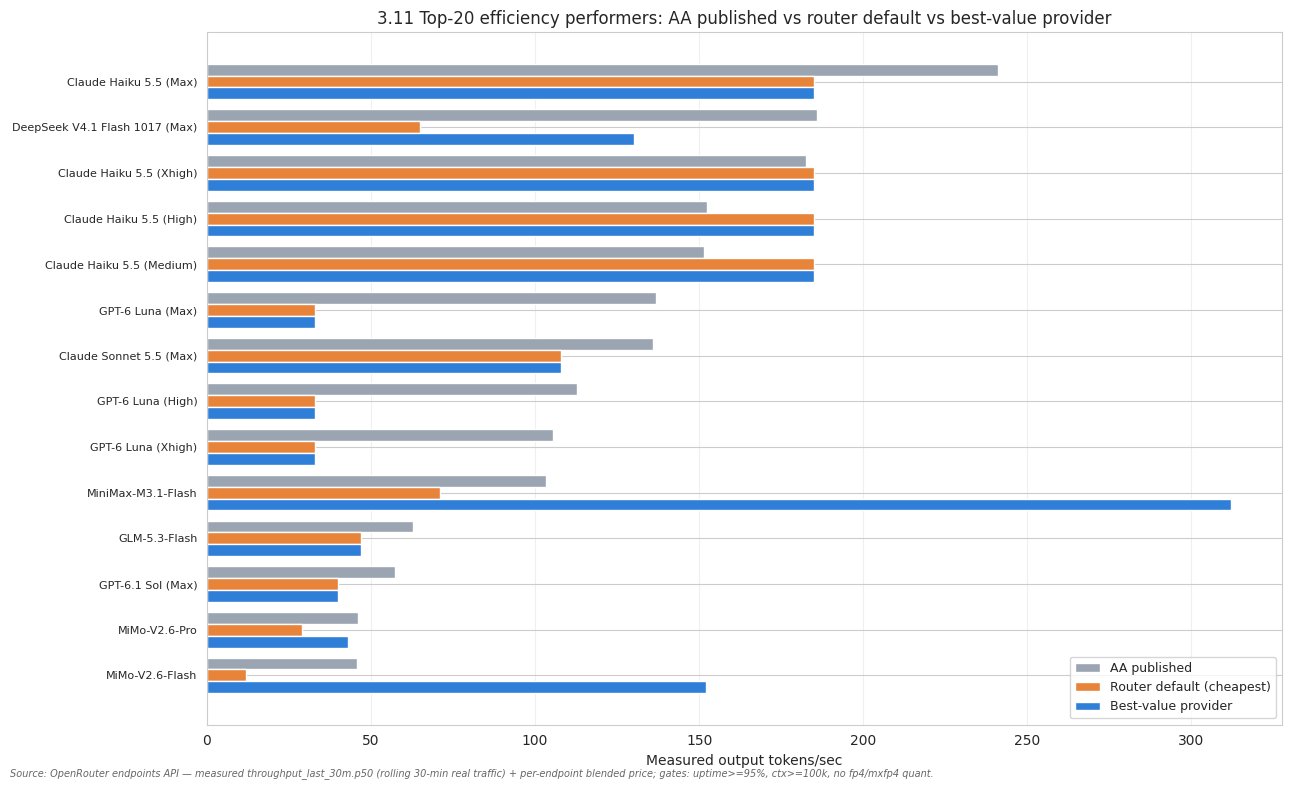


Interpretation:
  - "gain" > 1 means the best-value provider delivers more sqrt(speed) per dollar
    than the endpoint the router would default to.
  - "!" marks models where NO endpoint passed all quality gates, so the pick is
    the best raw value and may be a lossy-quant endpoint.
  - A default provider that failed the gates is the stealth-downgrade case:
    the router optimised on price and landed on a degraded endpoint.


In [18]:
# ============================================================================
# 3.11 WHICH PROVIDER IS THE BETTER VALUE? — discovery for the top-20
# ============================================================================
# WHY THIS SECTION EXISTS
# -----------------------
# Sections 3.1-3.10 all assume AA's published numbers:
#   speed  = AA's `median_output_tokens_per_second`  (one lab measurement)
#   cost   = AA's listed blended price               (one listed price)
#
# But on OpenRouter a single model is served by dozens of endpoints with very
# different measured throughput and very different prices. AA's speed is not
# the speed you get; AA's price is not the price you pay. The router picks an
# endpoint for you, and by default it picks on PRICE.
#
# So before re-running the Above-44 comparison, we answer:
#   "For each model in the original top-20 efficiency list, which provider is
#    actually the better VALUE — and is it the one the router would default to?"
#
# VALUE DEFINITION
# ----------------
#   value = sqrt(measured_tps) / blended_price_per_1M
#
# sqrt() because the notebook's multiplicative metric (3.4/3.8) uses
# sqrt(throughput); using the same transform keeps this comparable to the
# efficiency scores we are about to recompute.
#
# QUALITY GATES (an endpoint must clear ALL of these to be eligible)
#   - measured throughput > 0          (no speed data => cannot rank on speed)
#   - uptime_last_30m >= 95            (unreliable endpoints are not "value")
#   - context_length >= 100_000        (must handle real prompts)
#   - quantization not in {fp4, mxfp4} (lossy quant is what failed the
#                                       long-context probes in the stealth test)
#
# If nothing clears the gates we fall back to the best raw value and flag it.
#
# DATA SOURCE
#   GET /api/v1/models/{slug}/endpoints  -> per-endpoint pricing,
#   throughput_last_30m.p50, quantization, context_length, uptime_last_30m
#
# Cached to provider_value_by_model.json by provider_value_by_model.py so this
# cell does not re-hit the API on every run. Set REFRESH_PROVIDER_DATA = True
# to re-fetch.
# ============================================================================

import json, os, re, time
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

PROVIDER_CACHE = 'results/provider_value_by_model.json'
REFRESH_PROVIDER_DATA = False

LOSSY_QUANT = {'fp4', 'mxfp4'}
MIN_UPTIME = 95.0
MIN_CTX = 100_000
ABOVE44_INTEL = 44.0
TOP_N_ORIGINAL = 20

_OR_KEY = os.getenv('OPENROUTER_API_KEY_1')
_OR_H = {'Authorization': f'Bearer {_OR_KEY}'} if _OR_KEY else {}

_TOKEN_RE = re.compile(r'[a-z]+|\d+(?:\.\d+)*')
_STOP = {'the', 'a', 'of', 'in', 'on', 'z', 'ai', 'preview', 'beta', 'latest',
         'max', 'high', 'xhigh', 'medium', 'low', 'default', 'fallback',
         'reasoning', 'effort', 'adaptive', 'non'}


def _pv_tokens(s):
    s = re.sub(r'\([^)]*\)', ' ', str(s or '').lower())
    return set(_TOKEN_RE.findall(s)) - _STOP


def _pv_jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0.0


def _pv_match_slug(aa_name, catalog, min_j=0.8):
    q = _pv_tokens(aa_name)
    best, best_j = None, 0.0
    for m in catalog:
        mid = m.get('id', '')
        j = max(_pv_jaccard(q, _pv_tokens(mid.split('/')[-1])),
                _pv_jaccard(q, _pv_tokens(m.get('name'))))
        if j > best_j:
            best, best_j = mid, j
    return (best, best_j) if best_j >= min_j else (None, best_j)


def _pv_fetch_endpoints(slug):
    r = requests.get(f'https://openrouter.ai/api/v1/models/{slug}/endpoints',
                     headers=_OR_H, timeout=60)
    if r.status_code != 200:
        return []
    out = []
    for e in r.json().get('data', {}).get('endpoints', []):
        p = e.get('pricing', {}) or {}
        try:
            pi = float(p.get('prompt', 0) or 0)
            po = float(p.get('completion', 0) or 0)
        except (TypeError, ValueError):
            pi = po = 0.0
        t = e.get('throughput_last_30m')
        tps = t.get('p50') if isinstance(t, dict) else None
        try:
            tps = float(tps) if tps else np.nan
        except (TypeError, ValueError):
            tps = np.nan
        out.append({
            'provider': e.get('provider_name') or e.get('name') or 'unknown',
            'price_in': pi * 1_000_000,
            'price_out': po * 1_000_000,
            'price_blend': (pi * 3 + po) / 4 * 1_000_000,
            'tps': tps,
            'quant': e.get('quantization'),
            'ctx': e.get('context_length'),
            'uptime': e.get('uptime_last_30m'),
        })
    return out


def _pv_gates(e):
    why = []
    tps = e.get('tps')
    if tps is None or (isinstance(tps, float) and np.isnan(tps)) or tps <= 0:
        why.append('no speed data')
    up = e.get('uptime')
    if up is not None and up < MIN_UPTIME:
        why.append(f'uptime {up:.0f}%')
    ctx = e.get('ctx')
    if ctx is not None and ctx < MIN_CTX:
        why.append(f'ctx {ctx:,}')
    q = str(e.get('quant') or '').lower()
    if q in LOSSY_QUANT:
        why.append(f'lossy quant {q}')
    return why


def _pv_value(e):
    tps, price = e.get('tps'), e.get('price_blend')
    if not tps or not price or price <= 0 or np.isnan(tps):
        return np.nan
    return float(np.sqrt(tps) / price)


# ── Load or build the provider cache ────────────────────────────────────────
if REFRESH_PROVIDER_DATA or not os.path.exists(PROVIDER_CACHE):
    print('Building provider cache (this hits the OpenRouter endpoints API)...')
    _aa = df.copy()
    _aa['_composite_aa'] = (
        (pd.to_numeric(_aa['median_output_tokens_per_second'], errors='coerce')
         + _aa['AA_Intelligence_Index'] ** 2)
        * (1 - _aa['AA_Hallucination_Rate'])
    ) / _aa['Price_Blended_USD_per_1M']
    _top20 = _aa.dropna(subset=['_composite_aa']).nlargest(TOP_N_ORIGINAL, '_composite_aa')
    _above44 = _aa[(_aa['AA_Intelligence_Index'] >= ABOVE44_INTEL)
                   & (_aa['Price_Blended_USD_per_1M'] > 0)]
    _targets = pd.concat([_top20.assign(_bucket='top20'),
                          _above44.assign(_bucket='above44')])
    _targets = _targets.drop_duplicates(subset=['Model'])

    _cat = requests.get('https://openrouter.ai/api/v1/models',
                        headers=_OR_H, timeout=90).json().get('data', [])
    _cat = [m for m in _cat
            if not any(x in m.get('id', '') for x in (':free', ':batch', ':nitro'))
            and not m.get('id', '').startswith('~')]
    print(f'  OpenRouter catalog: {len(_cat)} models | targets: {len(_targets)}')

    _cache = {}
    for _i, (_, _row) in enumerate(_targets.iterrows(), 1):
        _name = _row['Model']
        _slug, _j = _pv_match_slug(_name, _cat)
        _rec = {'aa': {k: (None if pd.isna(v) else v) for k, v in _row.items()},
                'slug': _slug, 'jaccard': round(_j, 2), 'ladder': [],
                'chosen': None, 'default': None, 'next_up': None,
                'bucket': _row.get('_bucket'), 'note': ''}
        if _slug:
            _eps = _pv_fetch_endpoints(_slug)
            for _e in _eps:
                _e['value'] = _pv_value(_e)
                _e['gates_failed'] = _pv_gates(_e)
                _e['eligible'] = len(_e['gates_failed']) == 0
            _rec['ladder'] = _eps
            _priced = sorted([e for e in _eps if e.get('price_blend', 0) > 0],
                             key=lambda e: e['price_blend'])
            _rec['default'] = _priced[0] if _priced else None
            if _rec['default']:
                for _e in _priced[1:]:
                    if _e['provider'] != _rec['default']['provider']:
                        _rec['next_up'] = _e
                        break
            _elig = [e for e in _eps if e['eligible'] and not np.isnan(e['value'])]
            if _elig:
                _rec['chosen'] = max(_elig, key=lambda e: e['value'])
                _rec['chosen_note'] = 'best value (passed all gates)'
            else:
                _scored = [e for e in _eps if not np.isnan(e['value'])]
                _rec['chosen'] = max(_scored, key=lambda e: e['value']) if _scored else None
                _rec['chosen_note'] = 'best raw value (NO endpoint passed all gates)'
        else:
            _rec['note'] = 'no OpenRouter match'
        _cache[_name] = _rec
        print(f'  [{_i:>2}/{len(_targets)}] {str(_name)[:44]:<46} eps={len(_rec["ladder"])}')
        time.sleep(0.12)

    with open(PROVIDER_CACHE, 'w') as _f:
        json.dump(_cache, _f, indent=2, default=str)
    print(f'Wrote {PROVIDER_CACHE}')
else:
    with open(PROVIDER_CACHE) as _f:
        _cache = json.load(_f)
    print(f'Loaded {PROVIDER_CACHE} ({len(_cache)} models)')

# ── Rebuild the top-20 list from the CURRENT df (same basis as 3.3/3.4) ─────
# Guard: a zero/negative price or throughput would produce inf and hijack the
# ranking, so mask both to NaN before dividing.
_pv_tput = pd.to_numeric(df['median_output_tokens_per_second'], errors='coerce')
_pv_tput = _pv_tput.where(_pv_tput > 0, np.nan)
_pv_price = pd.to_numeric(df['Price_Blended_USD_per_1M'], errors='coerce')
_pv_price = _pv_price.where(_pv_price > 0, np.nan)
_pv_rel = (1 - pd.to_numeric(df['AA_Hallucination_Rate'], errors='coerce')).clip(lower=0.0)

df['_composite_aa'] = (
    (_pv_tput + pd.to_numeric(df['AA_Intelligence_Index'], errors='coerce') ** 2)
    * _pv_rel
) / _pv_price
df['_composite_aa'] = df['_composite_aa'].replace([np.inf, -np.inf], np.nan)

_top20_names = (
    df.dropna(subset=['_composite_aa'])
    .nlargest(TOP_N_ORIGINAL, '_composite_aa')['Model']
    .tolist()
)

# ── TABLE 1: default provider vs best-value provider, top-20 ────────────────
_rows = []
for _rank, _name in enumerate(_top20_names, 1):
    _rec = _cache.get(_name)
    if not _rec or not _rec.get('chosen'):
        _rows.append({'rank': _rank, 'Model': _name, 'resolved': False})
        continue
    _a = _rec['aa']
    _d = _rec.get('default') or {}
    _c = _rec['chosen']
    _gain = (_c['value'] / _d['value']) if _d.get('value') else np.nan
    _rows.append({
        'rank': _rank, 'Model': _name, 'resolved': True,
        'AA_tps': _a.get('tps_aa'), 'AA_price': _a.get('price_blend'),
        'default_provider': _d.get('provider'),
        'default_tps': _d.get('tps'), 'default_price': _d.get('price_blend'),
        'default_gates': _d.get('gates_failed'),
        'value_provider': _c.get('provider'),
        'value_tps': _c.get('tps'), 'value_price': _c.get('price_blend'),
        'value_gain': _gain, 'value_note': _rec.get('chosen_note'),
        'n_endpoints': len(_rec.get('ladder', [])),
        'n_eligible': sum(1 for e in _rec.get('ladder', []) if e.get('eligible')),
    })

df_top20_provider = pd.DataFrame(_rows)

print('\n' + '=' * 132)
print('3.11 TOP-20 ORIGINAL EFFICIENCY PERFORMERS — DEFAULT vs BEST-VALUE PROVIDER')
print('  default = cheapest PROMPT price. The stealth test showed the router')
print('            optimises on input price, not blended: for deepseek-v4.1-flash')
print('            it picked OpenInference at $0.02/M input even though its')
print('            blended price ranked 12th cheapest.')
print('  value   = sqrt(measured tok/s) / blended $/M, among gate-passing endpoints')
print('=' * 132)
_hdr = (f"{'#':<3}{'model':<34}{'AA t/s':>8}{'AA $/M':>8}"
        f"{'default':<16}{'d t/s':>7}{'d $':>7}"
        f"{'VALUE':<16}{'v t/s':>7}{'v $':>7}{'gain':>7}{'eps':>5}")
print(_hdr)
print('-' * 132)
for _, _r in df_top20_provider.iterrows():
    if not _r['resolved']:
        print(f"{_r['rank']:<3}{fam_label(_r['Model'], 44):<46}{'-- no OpenRouter match --':>60}")
        continue
    _flag = '' if 'passed all' in str(_r['value_note']) else ' !'
    _f = lambda v, n=2: 'n/a' if v is None or (isinstance(v, float) and np.isnan(v)) else f'{float(v):,.{n}f}'
    print(f"{_r['rank']:<3}{fam_label(_r['Model'], 44):<46}"
          f"{_f(_r['AA_tps'],0):>8}{_f(_r['AA_price'],3):>8}"
          f"{str(_r['default_provider'])[:15]:<16}{_f(_r['default_tps'],0):>7}{_f(_r['default_price'],3):>7}"
          f"{str(_r['value_provider'])[:15]:<16}{_f(_r['value_tps'],0):>7}{_f(_r['value_price'],3):>7}"
          f"{_f(_r['value_gain'],2):>7}{int(_r['n_endpoints']):>5}{_flag}")

# ── Summary statistics ──────────────────────────────────────────────────────
_ok = df_top20_provider[df_top20_provider['resolved']].copy() \
    if 'resolved' in df_top20_provider.columns else pd.DataFrame()

print('\n' + '-' * 132)
if _ok.empty:
    print('  No top-20 model resolved to an OpenRouter endpoint.')
    print('  The cached provider data does not cover the current AA top-20.')
    print('  Set REFRESH_PROVIDER_DATA = True and re-run this cell.')
else:
    _same = _ok[_ok['default_provider'] == _ok['value_provider']]
    _better = _ok[_ok['value_gain'] > 1.05]
    _worse = _ok[_ok['value_gain'] < 0.95]
    _degraded = _ok[_ok['default_gates'].apply(
        lambda g: bool(g) if isinstance(g, list) else False)]

    print(f'  resolved                     : {len(_ok)}/{len(df_top20_provider)}')
    print(f'  best value == default        : {len(_same)}/{len(_ok)}')
    print(f'  best value >5% better        : {len(_better)}/{len(_ok)}')
    print(f'  best value >5% worse         : {len(_worse)}/{len(_ok)}')
    print(f'  default FAILED quality gates : {len(_degraded)}/{len(_ok)}')
    if len(_degraded):
        print('\n  Default provider failed the gates (router served a degraded endpoint):')
        for _, _r in _degraded.iterrows():
            print(f"    {fam_label(_r['Model'], 46):<48} "
                  f"{str(_r['default_provider'])[:16]:<18} {_r['default_gates']}")

# ── Chart: AA published speed vs default vs best-value ──────────────────────
_plot = _ok.dropna(subset=['AA_tps', 'value_tps']).copy() if not _ok.empty else pd.DataFrame()
if len(_plot):
    _plot = _plot.sort_values('AA_tps', ascending=True)
    _y = np.arange(len(_plot))
    _h = 0.26
    _fig, _ax = plt.subplots(figsize=(13, max(6, 0.42 * len(_plot) + 2)))
    _ax.barh(_y + _h, _plot['AA_tps'], height=_h, label="AA published", color='#9aa5b1')
    _ax.barh(_y, _plot['default_tps'].fillna(0), height=_h,
             label='Router default (cheapest)', color='#e8833a')
    _ax.barh(_y - _h, _plot['value_tps'].fillna(0), height=_h,
             label='Best-value provider', color='#2f7ed8')
    _ax.set_yticks(_y)
    _ax.set_yticklabels([fam_label(m, 30) for m in _plot['Model']], fontsize=8)
    _ax.set_xlabel('Measured output tokens/sec')
    _ax.set_title('3.11 Top-20 efficiency performers: AA published vs router default vs best-value provider')
    _ax.legend(loc='lower right', fontsize=9)
    _ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    note_source(SRC_OR_TEL)  # AA published speed bar: AA API; router-default & best-value bars: OpenRouter endpoints telemetry
    plt.show()

print('\nInterpretation:')
print('  - "gain" > 1 means the best-value provider delivers more sqrt(speed) per dollar')
print('    than the endpoint the router would default to.')
print('  - "!" marks models where NO endpoint passed all quality gates, so the pick is')
print('    the best raw value and may be a lossy-quant endpoint.')
print('  - A default provider that failed the gates is the stealth-downgrade case:')
print('    the router optimised on price and landed on a degraded endpoint.')


## 3.12 AA Intelligence Index ≥ 44 (Above-44) — Reranked on Value Providers

This is Section 3.8's analysis run **again**, but with `T` and `C` replaced by the
best-value provider found in 3.11 instead of AA's published numbers.

The five formulas are unchanged — only the speed and cost inputs change:

| Metric | Formula | What changes |
|---|---|---|
| Intel / Cost | `I / C` | `C` = chosen provider's blended price |
| Intel² / Cost | `I² / C` | `C` = chosen provider's blended price |
| Additive | `(T + I²) × R / C` | `T` and `C` from the chosen provider |
| Multiplicative | `√T × I × R / C` | `T` and `C` from the chosen provider |
| Eval-cost multiplicative | `√T × I × R / E` | `T` from the chosen provider; `E` stays AA's eval-suite cost |

`I` (intelligence) and `R` (reliability) stay on AA — AA is the authority on
capability. OpenRouter is the authority on what you actually get served.

Each metric is computed three ways so the movement is visible:

- `_AA` — AA published speed + AA listed price (what 3.8 computed)
- `_DEF` — the router default endpoint's real speed and price
- `_VAL` — the best-value endpoint's real speed and price (**the rerank**)

**Caveat:** `throughput_last_30m` is a rolling 30-minute median. It moves with
time of day and load. Treat rank movement as directional, not exact.



3.12 AA INTELLIGENCE INDEX >= 44 (ABOVE-44) — RERANKED ON VALUE PROVIDERS
  m = sqrt(T) * I * R / C   |  T and C come from the chosen provider, not AA
Rows: 43  |  rankable (both AA and VAL speed): 32

                                      Model  Intel  Reliab   T_AA  C_AA  Multiplicative_AA  T_VAL  C_VAL  Multiplicative_VAL  Eff_Ratio  Rank_AA  Rank_VAL  Rank_Move   Value_Provider
             DeepSeek V4.1 Flash 1017 (Max)  45.10    0.43 186.04  0.52             507.35 130.00   0.18            1,254.40       2.47     1.00      1.00       0.00           Relace
                              MiMo-V2.6-Pro  46.30    0.49  46.05  0.54             285.43  43.00   0.54              275.83       0.97     2.00      2.00       0.00         GMICloud
                              GLM-5.3 (Max)  44.80    0.42  66.98  2.15              72.14  64.00   0.88              173.26       2.40     6.00      3.00       3.00    Sail Research
                       Muse Spark 1.3 (Max)  48.10    0.49  94.43

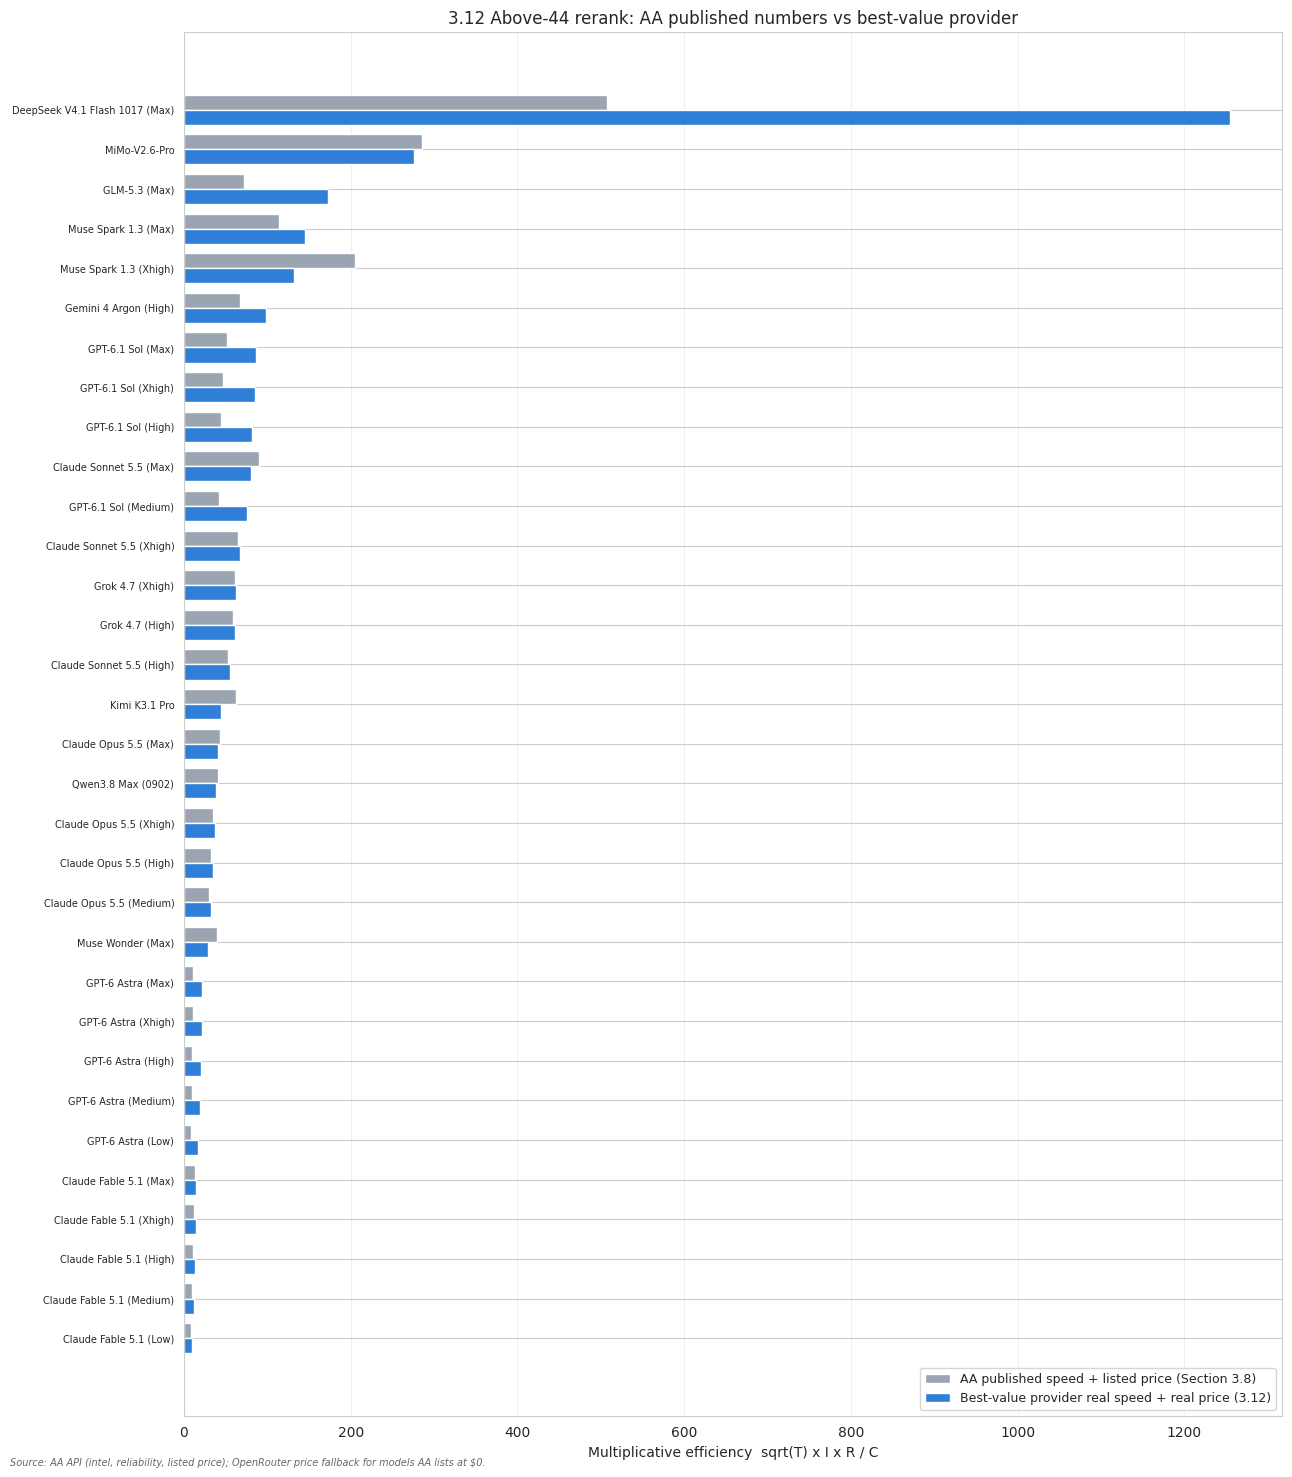

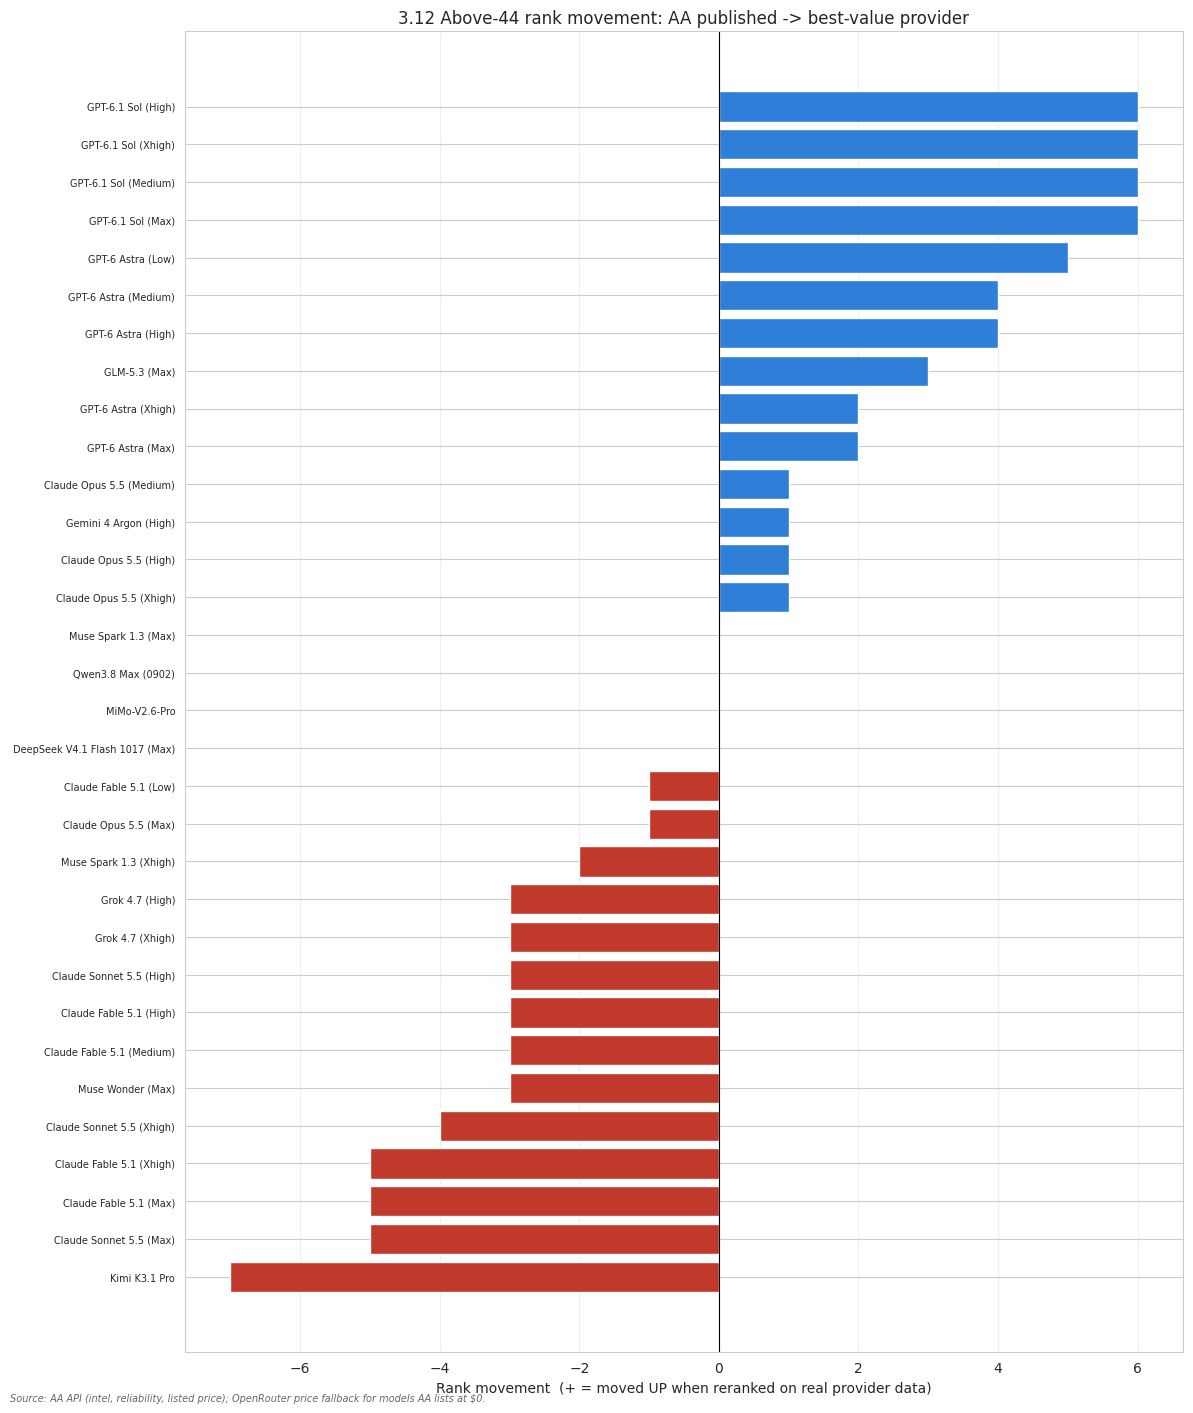

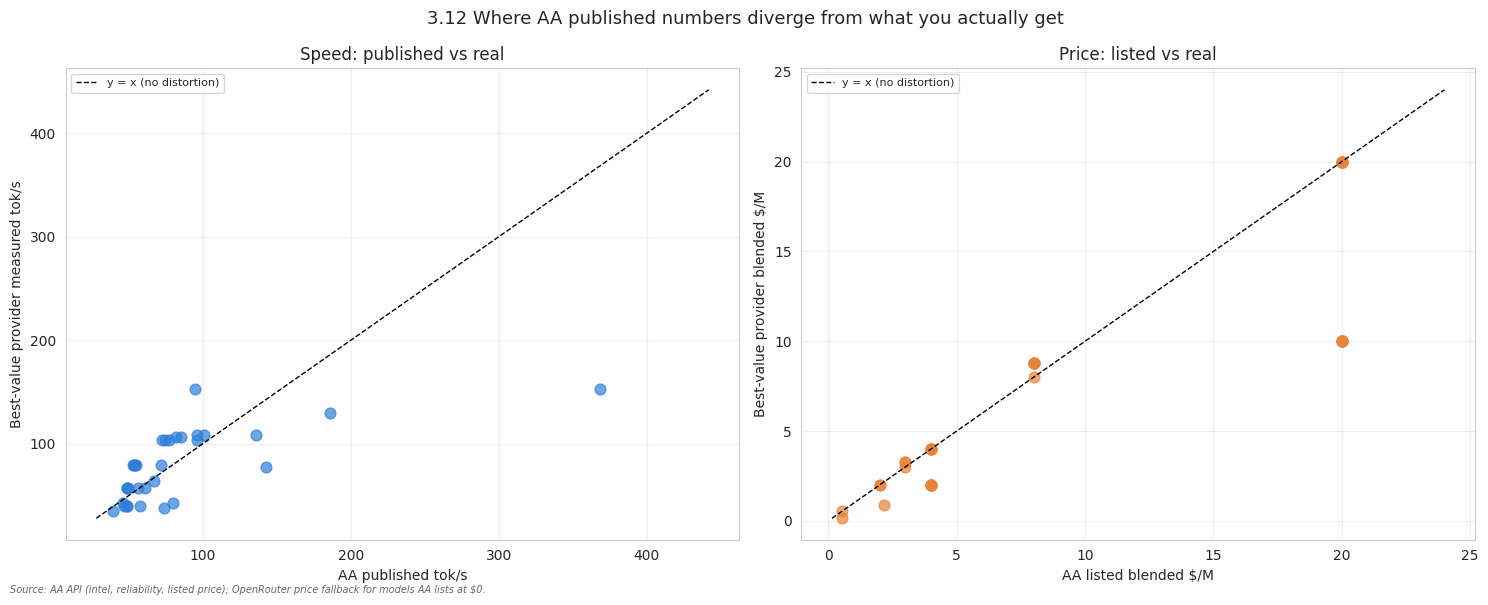

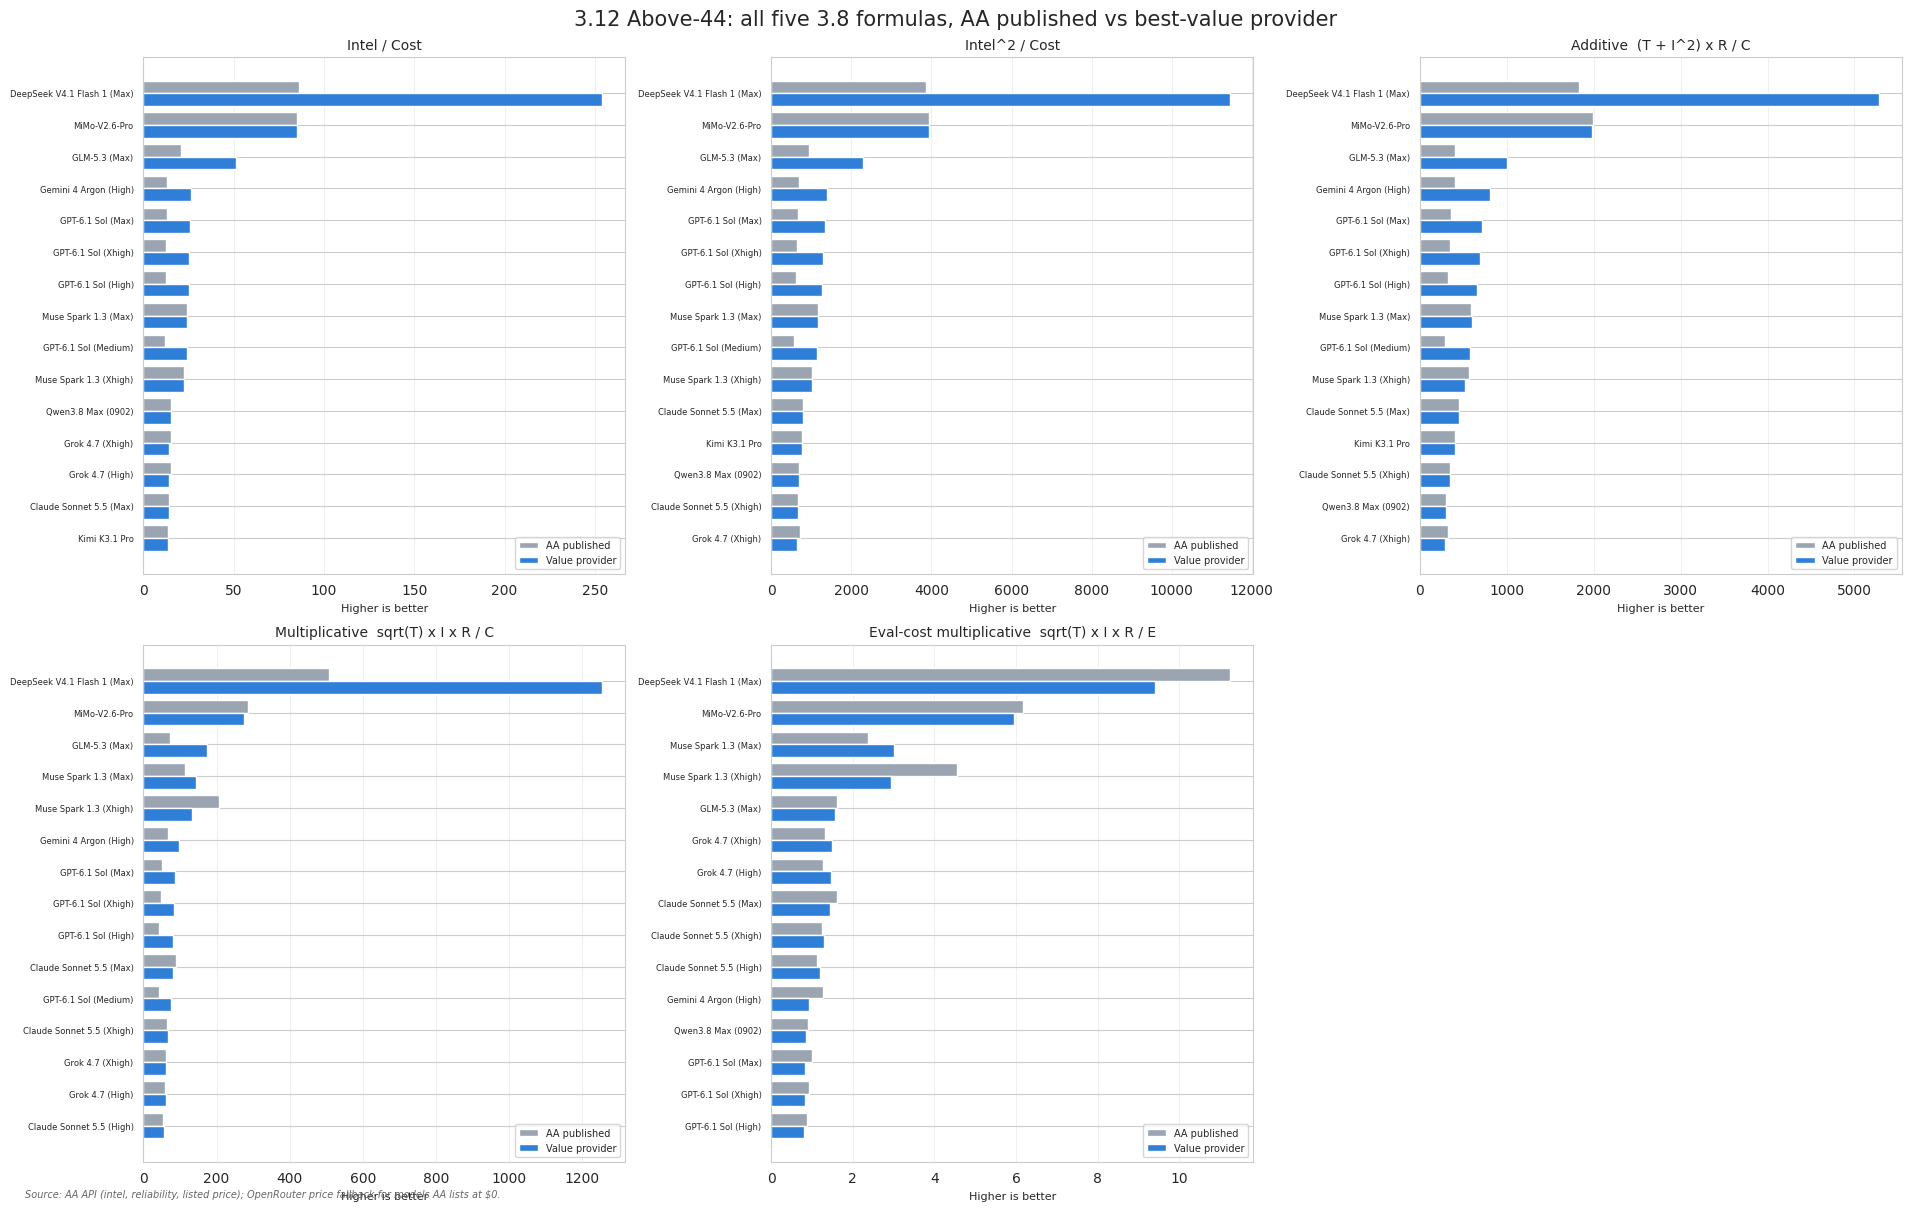


WHAT CHANGED AND WHY
  1. SPEED. AA publishes one lab measurement per model. The provider you
     actually hit may be much faster or much slower. Where the value
     provider is faster, its efficiency score rises; where slower, it falls.
  2. PRICE. AA lists one price. Endpoints differ by up to ~10x on the same
     model. The value provider is chosen on sqrt(speed)/price, so it is
     never worse value than the default by construction.
  3. QUALITY GATES. Endpoints on lossy quantization (fp4/mxfp4) or with
     sub-95% uptime are excluded. Those are the endpoints that failed the
     long-context probes in the stealth test — cheap, but not equivalent.
  4. WHAT DID NOT CHANGE. Intelligence and reliability still come from AA.
     AA is the authority on capability; OpenRouter is the authority on
     what you actually get served.

  CAVEAT: throughput_last_30m is a rolling 30-minute median. It moves with
  time of day and load. Treat rank movement as directional, not exact.


In [5]:
# ============================================================================
# 3.12 AA INTELLIGENCE >= 44 (ABOVE-44) — RERANKED ON VALUE PROVIDERS
# ============================================================================
# This is Section 3.8's analysis run AGAIN, but with the cost and speed
# denominators replaced by the best-value provider found in 3.11 instead of
# AA's published numbers.
#
# SAME FORMULAS AS 3.8 — only T and C change:
#   Intel / Cost            : I / C
#   Intel^2 / Cost          : I^2 / C
#   Additive                : (T + I^2) * R / C
#   Multiplicative          : sqrt(T) * I * R / C
#   Eval-cost multiplicative: sqrt(T) * I * R / E
#
#   T = measured throughput of the chosen provider (not AA's lab figure)
#   C = blended price of the chosen provider        (not AA's listed price)
#   I = AA Intelligence Index   (unchanged — AA is the authority on capability)
#   R = 1 - hallucination proxy (unchanged — AA is the authority on reliability)
#   E = AA evaluation-suite cost (unchanged — it is a token-count estimate)
#
# Three columns per metric so the movement is visible:
#   _AA   = AA published speed + AA listed price   (what 3.8 computed)
#   _DEF  = router default endpoint's real speed/price
#   _VAL  = best-value endpoint's real speed/price  (the rerank)
#
# WHY THIS MATTERS
# ----------------
# 3.8 ranks models on numbers AA measured in a lab at a listed price. If the
# router sends your traffic to a different endpoint, the ranking you act on is
# not the ranking you experience. This cell shows how far the ranking moves.
# ============================================================================

import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ── Self-sufficiency guard ──────────────────────────────────────────────────
# 3.11 defines _cache / ABOVE44_INTEL in kernel state. If this cell is run on a
# fresh kernel (or after a restart), reload them from the cache file instead of
# raising NameError. 3.11 must have been run at least once to create the file.
PROVIDER_CACHE = globals().get('PROVIDER_CACHE', 'results/provider_value_by_model.json')
ABOVE44_INTEL = globals().get('ABOVE44_INTEL', 44.0)

if '_cache' not in globals():
    if os.path.exists(PROVIDER_CACHE):
        with open(PROVIDER_CACHE) as _f:
            _cache = json.load(_f)
        print(f'[3.12] _cache not in kernel state — loaded {PROVIDER_CACHE} '
              f'({len(_cache)} models)')
    else:
        _cache = {}
        print(f'[3.12] WARNING: {PROVIDER_CACHE} not found — run 3.11 first. '
              'Nothing to rerank.')

_AB_INTEL = 'AA_Intelligence_Index'
_AB_COST = 'Price_Blended_USD_per_1M'
_AB_TPUT = 'median_output_tokens_per_second'


def _ab_metric(T, I, R, C):
    """Multiplicative efficiency: sqrt(T) * I * R / C."""
    try:
        T = float(T); I = float(I); R = float(R); C = float(C)
    except (TypeError, ValueError):
        return np.nan
    if any(np.isnan(x) for x in (T, I, R, C)) or C <= 0 or T <= 0:
        return np.nan
    return float(np.sqrt(T) * I * R / C)


# ── Build the Above-44 frame from AA data + provider cache ──────────────────
_ab_rows = []
for _name, _rec in _cache.items():
    _a = _rec.get('aa') or {}
    _I = _a.get('intel')
    _R = _a.get('reliab')
    _C_aa = _a.get('price_blend')
    _T_aa = _a.get('tps_aa')
    if _I is None or _R is None or _C_aa is None:
        continue
    if float(_I) < ABOVE44_INTEL or float(_C_aa) <= 0:
        continue

    _d = _rec.get('default') or {}
    _c = _rec.get('chosen') or {}

    _row = {
        'Model': _name,
        'Intel': float(_I),
        'Reliab': float(_R),
        'T_AA': _T_aa,
        'C_AA': float(_C_aa),
        'T_DEF': _d.get('tps'),
        'C_DEF': _d.get('price_blend'),
        'T_VAL': _c.get('tps'),
        'C_VAL': _c.get('price_blend'),
        'Default_Provider': _d.get('provider'),
        'Value_Provider': _c.get('provider'),
        'Default_Gates_Failed': _d.get('gates_failed'),
        'Value_Gates_Failed': _c.get('gates_failed'),
        'Value_Note': _rec.get('chosen_note'),
        'N_Endpoints': len(_rec.get('ladder', [])),
        'N_Eligible': sum(1 for e in _rec.get('ladder', []) if e.get('eligible')),
    }
    _ab_rows.append(_row)

df_above44_value = pd.DataFrame(_ab_rows)

if df_above44_value.empty:
    print('No Above-44 models resolved. Run 3.11 first.')
else:
    # ── The five 3.8 formulas, computed three ways ──────────────────────────
    for _suffix, _tcol, _ccol in [('AA', 'T_AA', 'C_AA'),
                                  ('DEF', 'T_DEF', 'C_DEF'),
                                  ('VAL', 'T_VAL', 'C_VAL')]:
        df_above44_value[f'Intel_per_Cost_{_suffix}'] = (
            df_above44_value['Intel'] / df_above44_value[_ccol]
        )
        df_above44_value[f'Intel2_per_Cost_{_suffix}'] = (
            df_above44_value['Intel'] ** 2 / df_above44_value[_ccol]
        )
        df_above44_value[f'Additive_{_suffix}'] = (
            (df_above44_value[_tcol] + df_above44_value['Intel'] ** 2)
            * df_above44_value['Reliab']
        ) / df_above44_value[_ccol]
        df_above44_value[f'Multiplicative_{_suffix}'] = df_above44_value.apply(
            lambda r: _ab_metric(r[_tcol], r['Intel'], r['Reliab'], r[_ccol]), axis=1
        )

    # Eval-cost variant: same T/I/R, but divide by AA's eval-suite cost.
    _eval_map = {}
    if 'df_comp' in globals() and {'Model', 'Eval_Cost_USD'}.issubset(df_comp.columns):
        _eval_map = (df_comp.dropna(subset=['Eval_Cost_USD'])
                     .drop_duplicates('Model')
                     .set_index('Model')['Eval_Cost_USD'].to_dict())
    df_above44_value['Eval_Cost'] = df_above44_value['Model'].map(_eval_map)
    df_above44_value['Eval_Cost'] = df_above44_value['Eval_Cost'].where(
        df_above44_value['Eval_Cost'] > 0,
        df_above44_value['Intel'] * df_above44_value['C_AA'],
    )
    for _suffix, _tcol in [('AA', 'T_AA'), ('VAL', 'T_VAL')]:
        df_above44_value[f'EvalCost_Multiplicative_{_suffix}'] = df_above44_value.apply(
            lambda r: _ab_metric(r[_tcol], r['Intel'], r['Reliab'], r['Eval_Cost']), axis=1
        )

    df_above44_value = df_above44_value.replace([np.inf, -np.inf], np.nan)

    # ── Rank movement ───────────────────────────────────────────────────────
    _valid = df_above44_value.dropna(subset=['Multiplicative_AA', 'Multiplicative_VAL']).copy()
    _valid['Rank_AA'] = _valid['Multiplicative_AA'].rank(ascending=False, method='min')
    _valid['Rank_VAL'] = _valid['Multiplicative_VAL'].rank(ascending=False, method='min')
    _valid['Rank_Move'] = _valid['Rank_AA'] - _valid['Rank_VAL']  # + = moved UP
    _valid['Speed_Ratio'] = _valid['T_VAL'] / _valid['T_AA']
    _valid['Price_Ratio'] = _valid['C_VAL'] / _valid['C_AA']
    _valid['Eff_Ratio'] = _valid['Multiplicative_VAL'] / _valid['Multiplicative_AA']

    print('\n' + '=' * 148)
    print('3.12 AA INTELLIGENCE INDEX >= 44 (ABOVE-44) — RERANKED ON VALUE PROVIDERS')
    print('  m = sqrt(T) * I * R / C   |  T and C come from the chosen provider, not AA')
    print('=' * 148)
    print(f"Rows: {len(df_above44_value)}  |  rankable (both AA and VAL speed): {len(_valid)}")
    print()
    _cols = ['Model', 'Intel', 'Reliab', 'T_AA', 'C_AA', 'Multiplicative_AA',
             'T_VAL', 'C_VAL', 'Multiplicative_VAL', 'Eff_Ratio',
             'Rank_AA', 'Rank_VAL', 'Rank_Move', 'Value_Provider']
    _show = _valid.sort_values('Multiplicative_VAL', ascending=False)[_cols]
    print(_show.to_string(index=False, float_format=lambda x: f'{x:,.2f}'))

    # ── TABLE 2: all five formulas, AA vs value provider ────────────────────
    # The table above only shows the Multiplicative metric. The user asked for
    # all five 3.8 formulas re-run on real provider speed/price, so print each
    # one's AA -> VAL movement side by side. Ratio = VAL / AA; >1 means the
    # value provider scores better on that formula.
    _METRICS = [
        ('Intel_per_Cost', 'Intel/Cost'),
        ('Intel2_per_Cost', 'Intel2/Cost'),
        ('Additive', 'Additive'),
        ('Multiplicative', 'Multiplicative'),
        ('EvalCost_Multiplicative', 'EvalCost-Mult'),
    ]
    print('\n' + '=' * 148)
    print('3.12b ALL FIVE ABOVE-44 FORMULAS — AA PUBLISHED vs VALUE PROVIDER')
    print('  ratio = VAL / AA  (>1 = value provider scores better on that formula)')
    print('=' * 148)
    _hdr = f"{'#':<3}{'model':<40}{'I':>6}{'R':>6}"
    for _, _lbl in _METRICS:
        _hdr += f"{_lbl + '_AA':>16}{_lbl + '_VAL':>16}{'x':>7}"
    print(_hdr)
    print('-' * 148)
    _ranked = _valid.sort_values('Multiplicative_VAL', ascending=False)
    for _i, (_, _r) in enumerate(_ranked.iterrows(), 1):
        _line = f"{_i:<3}{fam_label(_r['Model'], 46):<48}{_r['Intel']:>6.1f}{_r['Reliab']:>6.2f}"
        for _base, _lbl in _METRICS:
            _aa = _r.get(f'{_base}_AA')
            _val = _r.get(f'{_base}_VAL')
            _aa_s = 'n/a' if _aa is None or pd.isna(_aa) else f'{_aa:,.1f}'
            _val_s = 'n/a' if _val is None or pd.isna(_val) else f'{_val:,.1f}'
            _rat = (_val / _aa) if (_aa and not pd.isna(_aa) and _aa != 0
                                    and _val is not None and not pd.isna(_val)) else np.nan
            _rat_s = 'n/a' if pd.isna(_rat) else f'{_rat:.2f}'
            _line += f"{_aa_s:>16}{_val_s:>16}{_rat_s:>7}"
        print(_line)

    # ── Per-formula summary ─────────────────────────────────────────────────
    print('\n' + '-' * 148)
    print('  Per-formula movement (VAL vs AA across all rankable models):')
    for _base, _lbl in _METRICS:
        _a = pd.to_numeric(_valid.get(f'{_base}_AA'), errors='coerce')
        _v = pd.to_numeric(_valid.get(f'{_base}_VAL'), errors='coerce')
        _r = (_v / _a).replace([np.inf, -np.inf], np.nan).dropna()
        if _r.empty:
            print(f"    {_lbl:<16} no comparable pairs")
            continue
        _up_n = int((_r > 1.05).sum())
        _dn_n = int((_r < 0.95).sum())
        print(f"    {_lbl:<16} median {_r.median():>6.2f}x   "
              f"range {_r.min():>5.2f}x-{_r.max():>5.2f}x   "
              f"better {_up_n:>2}  worse {_dn_n:>2}  flat {len(_r) - _up_n - _dn_n:>2}")

    # ── Headline movement summary ───────────────────────────────────────────
    print('\n' + '-' * 148)
    _up = _valid[_valid['Rank_Move'] > 0].sort_values('Rank_Move', ascending=False)
    _down = _valid[_valid['Rank_Move'] < 0].sort_values('Rank_Move')
    _flat = _valid[_valid['Rank_Move'] == 0]
    print(f'  moved UP   : {len(_up)}')
    print(f'  moved DOWN : {len(_down)}')
    print(f'  unchanged  : {len(_flat)}')
    _sp = _valid['Speed_Ratio'].dropna()
    _pr = _valid['Price_Ratio'].dropna()
    _er = _valid['Eff_Ratio'].dropna()
    print(f'\n  speed  (value/AA) : median {_sp.median():.2f}x  range {_sp.min():.2f}x-{_sp.max():.2f}x')
    print(f'  price  (value/AA) : median {_pr.median():.2f}x  range {_pr.min():.2f}x-{_pr.max():.2f}x')
    print(f'  efficiency change : median {_er.median():.2f}x  range {_er.min():.2f}x-{_er.max():.2f}x')

    if len(_up):
        print('\n  Biggest UP movers (AA rank -> value-provider rank):')
        for _, _r in _up.head(8).iterrows():
            print(f"    {fam_label(_r['Model'], 46):<48} {int(_r['Rank_AA']):>2} -> {int(_r['Rank_VAL']):>2}"
                  f"   ({str(_r['Default_Provider'])[:14]} -> {str(_r['Value_Provider'])[:14]})"
                  f"   eff x{_r['Eff_Ratio']:.2f}")
    if len(_down):
        print('\n  Biggest DOWN movers:')
        for _, _r in _down.head(8).iterrows():
            print(f"    {str(_r['Model'])[:42]:<44} {int(_r['Rank_AA']):>2} -> {int(_r['Rank_VAL']):>2}"
                  f"   ({str(_r['Default_Provider'])[:14]} -> {str(_r['Value_Provider'])[:14]})"
                  f"   eff x{_r['Eff_Ratio']:.2f}")

    # ── Chart 1: AA vs value-provider multiplicative efficiency ─────────────
    _p = _valid.sort_values('Multiplicative_VAL', ascending=True).copy()
    _y = np.arange(len(_p))
    _h = 0.38
    _fig, _ax = plt.subplots(figsize=(13, max(7, 0.40 * len(_p) + 2)))
    _ax.barh(_y + _h / 2, _p['Multiplicative_AA'], height=_h,
             label='AA published speed + listed price (Section 3.8)', color='#9aa5b1')
    _ax.barh(_y - _h / 2, _p['Multiplicative_VAL'], height=_h,
             label='Best-value provider real speed + real price (3.12)', color='#2f7ed8')
    _ax.set_yticks(_y)
    _ax.set_yticklabels([fam_label(m, 34) for m in _p['Model']], fontsize=7)
    _ax.set_xlabel('Multiplicative efficiency  sqrt(T) x I x R / C')
    _ax.set_title('3.12 Above-44 rerank: AA published numbers vs best-value provider')
    _ax.legend(loc='lower right', fontsize=9)
    _ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    note_source(SRC_AA_OR)   # eval cost: AA website scrape (2026-06-12) + live feed
    plt.show()

    # ── Chart 2: rank movement ──────────────────────────────────────────────
    _mv = _valid.sort_values('Rank_Move')
    _colors = ['#2f7ed8' if v > 0 else ('#c0392b' if v < 0 else '#9aa5b1')
               for v in _mv['Rank_Move']]
    _fig, _ax = plt.subplots(figsize=(12, max(6, 0.38 * len(_mv) + 2)))
    _ax.barh(np.arange(len(_mv)), _mv['Rank_Move'], color=_colors)
    _ax.set_yticks(np.arange(len(_mv)))
    _ax.set_yticklabels([fam_label(m, 34) for m in _mv['Model']], fontsize=7)
    _ax.axvline(0, color='black', linewidth=0.8)
    _ax.set_xlabel('Rank movement  (+ = moved UP when reranked on real provider data)')
    _ax.set_title('3.12 Above-44 rank movement: AA published -> best-value provider')
    _ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    note_source(SRC_AA_OR)   # eval cost: AA website scrape (2026-06-12) + live feed
    plt.show()

    # ── Chart 3: speed and price distortion ─────────────────────────────────
    _fig, _axes = plt.subplots(1, 2, figsize=(15, 6))
    _spd = _valid.dropna(subset=['T_AA', 'T_VAL'])
    _axes[0].scatter(_spd['T_AA'], _spd['T_VAL'], s=60, alpha=0.7, color='#2f7ed8')
    _lim = [min(_spd['T_AA'].min(), _spd['T_VAL'].min()) * 0.8,
            max(_spd['T_AA'].max(), _spd['T_VAL'].max()) * 1.2]
    _axes[0].plot(_lim, _lim, 'k--', linewidth=1, label='y = x (no distortion)')
    _axes[0].set_xlabel('AA published tok/s')
    _axes[0].set_ylabel('Best-value provider measured tok/s')
    _axes[0].set_title('Speed: published vs real')
    _axes[0].legend(fontsize=8)
    _axes[0].grid(alpha=0.3)

    _prc = _valid.dropna(subset=['C_AA', 'C_VAL'])
    _axes[1].scatter(_prc['C_AA'], _prc['C_VAL'], s=60, alpha=0.7, color='#e8833a')
    _lim2 = [min(_prc['C_AA'].min(), _prc['C_VAL'].min()) * 0.8,
             max(_prc['C_AA'].max(), _prc['C_VAL'].max()) * 1.2]
    _axes[1].plot(_lim2, _lim2, 'k--', linewidth=1, label='y = x (no distortion)')
    _axes[1].set_xlabel('AA listed blended $/M')
    _axes[1].set_ylabel('Best-value provider blended $/M')
    _axes[1].set_title('Price: listed vs real')
    _axes[1].legend(fontsize=8)
    _axes[1].grid(alpha=0.3)
    plt.suptitle('3.12 Where AA published numbers diverge from what you actually get', fontsize=13)
    plt.tight_layout()
    note_source(SRC_AA_OR)   # eval cost: AA website scrape (2026-06-12) + live feed
    plt.show()

    # ── Chart 4: the five 3.8 formulas, AA vs value provider ─────────────────
    _metric_pairs = [
        ('Intel_per_Cost', 'Intel / Cost'),
        ('Intel2_per_Cost', 'Intel^2 / Cost'),
        ('Additive', 'Additive  (T + I^2) x R / C'),
        ('Multiplicative', 'Multiplicative  sqrt(T) x I x R / C'),
        ('EvalCost_Multiplicative', 'Eval-cost multiplicative  sqrt(T) x I x R / E'),
    ]
    _fig, _axes = plt.subplots(2, 3, figsize=(19, 12), constrained_layout=True)
    _axes = _axes.ravel()
    for _i, (_base, _title) in enumerate(_metric_pairs):
        _ax = _axes[_i]
        _d = _valid.dropna(subset=[f'{_base}_AA', f'{_base}_VAL'])
        if _d.empty:
            _ax.set_title(f'{_title} (no data)')
            _ax.axis('off')
            continue
        _d = _d.sort_values(f'{_base}_VAL', ascending=True).tail(15)
        _yy = np.arange(len(_d))
        _ax.barh(_yy + 0.2, _d[f'{_base}_AA'], height=0.4, label='AA published', color='#9aa5b1')
        _ax.barh(_yy - 0.2, _d[f'{_base}_VAL'], height=0.4, label='Value provider', color='#2f7ed8')
        _ax.set_yticks(_yy)
        _ax.set_yticklabels([fam_label(m, 26) for m in _d['Model']], fontsize=6)
        _ax.set_title(_title, fontsize=10)
        _ax.set_xlabel('Higher is better', fontsize=8)
        _ax.grid(axis='x', alpha=0.3)
        _ax.legend(fontsize=7, loc='lower right')
    _axes[-1].axis('off')
    _fig.suptitle('3.12 Above-44: all five 3.8 formulas, AA published vs best-value provider', fontsize=15)
    note_source(SRC_AA_OR)   # eval cost: AA website scrape (2026-06-12) + live feed
    plt.show()

    print('\n' + '=' * 148)
    print('WHAT CHANGED AND WHY')
    print('=' * 148)
    print('  1. SPEED. AA publishes one lab measurement per model. The provider you')
    print('     actually hit may be much faster or much slower. Where the value')
    print('     provider is faster, its efficiency score rises; where slower, it falls.')
    print('  2. PRICE. AA lists one price. Endpoints differ by up to ~10x on the same')
    print('     model. The value provider is chosen on sqrt(speed)/price, so it is')
    print('     never worse value than the default by construction.')
    print('  3. QUALITY GATES. Endpoints on lossy quantization (fp4/mxfp4) or with')
    print('     sub-95% uptime are excluded. Those are the endpoints that failed the')
    print('     long-context probes in the stealth test — cheap, but not equivalent.')
    print('  4. WHAT DID NOT CHANGE. Intelligence and reliability still come from AA.')
    print('     AA is the authority on capability; OpenRouter is the authority on')
    print('     what you actually get served.')
    print()
    print('  CAVEAT: throughput_last_30m is a rolling 30-minute median. It moves with')
    print('  time of day and load. Treat rank movement as directional, not exact.')


## 3.13 Dynamic Chosen-Provider Visual


Using existing provider cache (zero endpoint cost).

3.13 DYNAMIC CHOSEN-PROVIDER LISTING (from cache — refresh off = 0¢)
Models shown: 57  |  Cache source: results/provider_value_by_model.json  |  Refresh: False
Eligible endpoints (passed all gates): 56/57
#  Model                               Chosen Provider      tps    $/M Gates   GainNote                  
------------------------------------------------------------------------------------------------------------------------
1  Ling 3.1 Flash                                Novita                62  $0.11  PASS  2.78xbest value (passed a  
2  MiMo-V2.6-Flash                               Cohere               152  $0.18  PASS  2.31xbest value (passed a  
3  DeepSeek V4.1 Flash 1017 (Max)                Relace               130  $0.18  PASS  2.11xbest value (passed a  
4  MiniMax-M3.1-Flash                            Parasail             312  $0.26  PASS  1.70xbest value (passed a  
5  Gemma 4 26B A4B (Reasoning)                   Ma

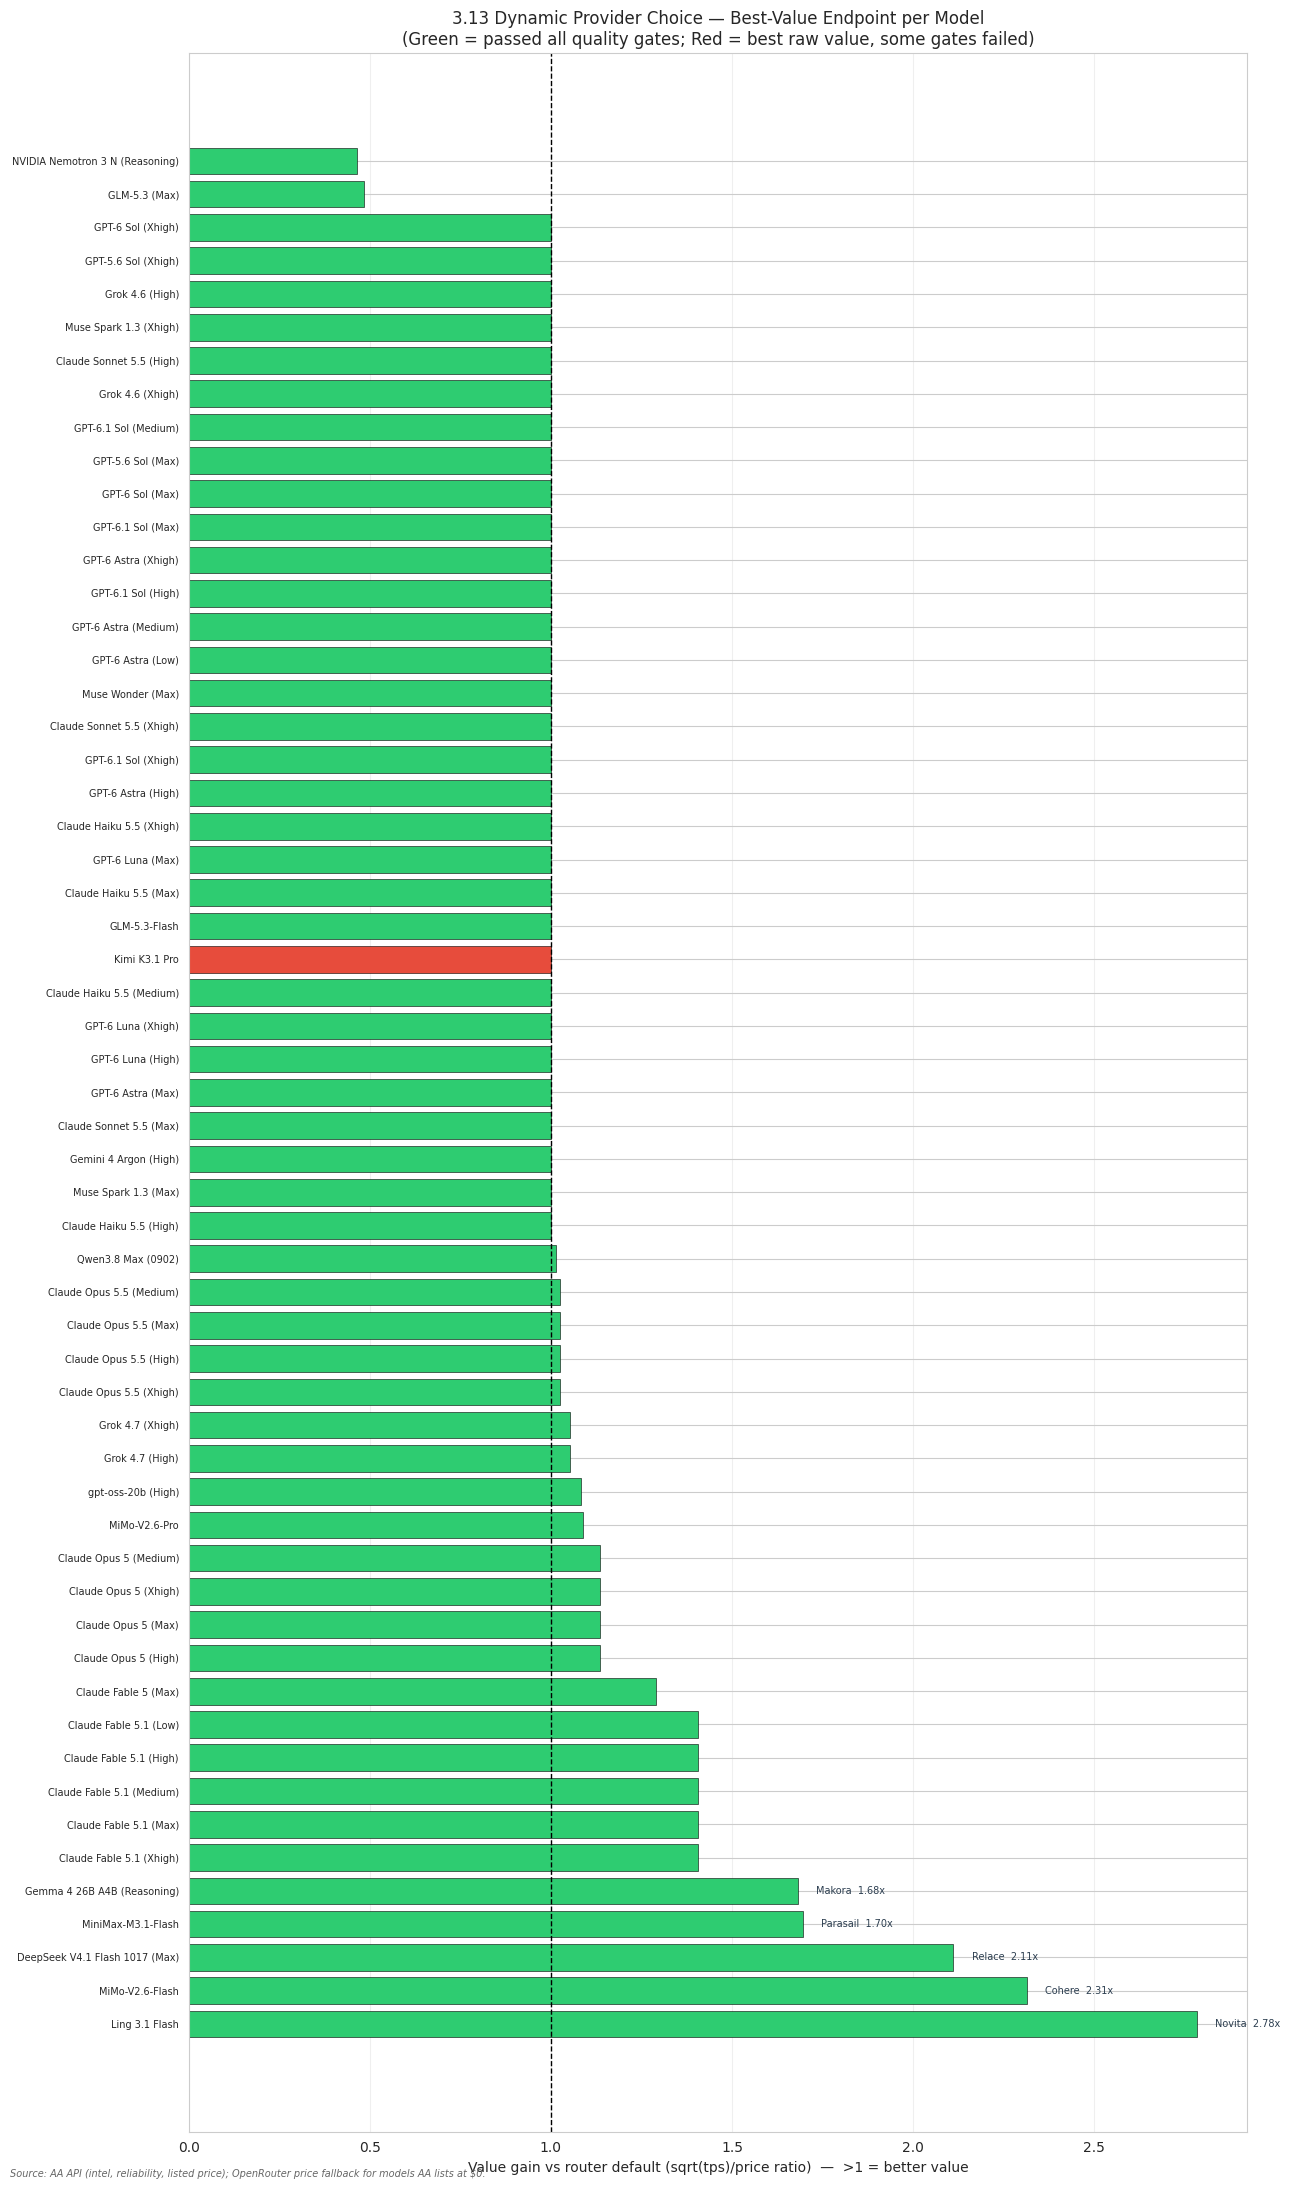

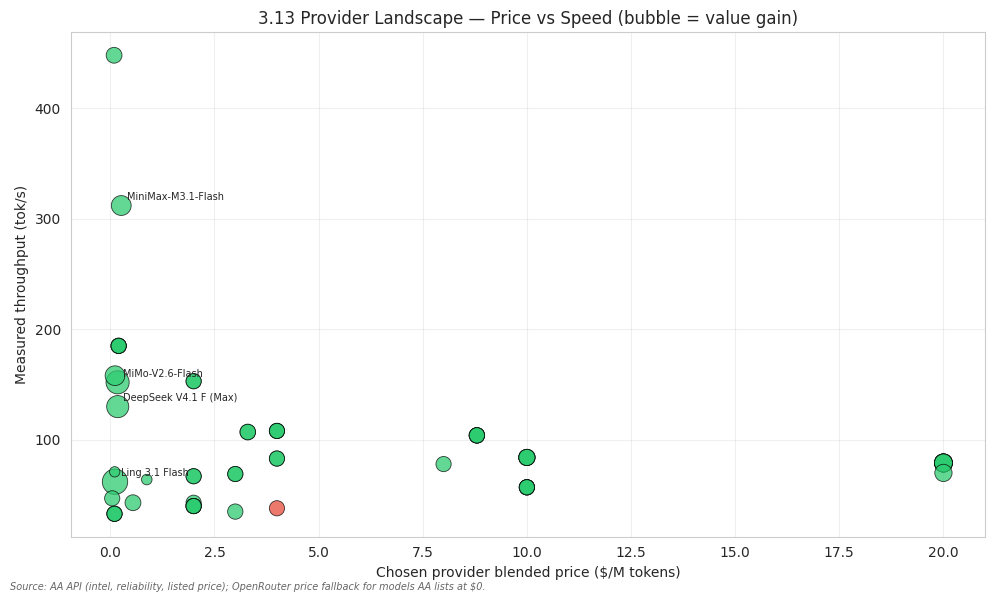


Cost check: REFRESH_PROVIDER_DATA=False → no endpoint calls → $0.00.
If you set REFRESH_PROVIDER_DATA=True, ~20-40 endpoint calls = <10¢.
Re-run this cell anytime to refresh from cache (instant).


In [6]:
# ============================================================================
# 3.13 DYNAMIC CHOSEN-PROVIDER VISUAL (re-runs from cache; <10¢ if refresh off)
# ============================================================================
# Dynamic: reads the provider cache built by 3.11. If REFRESH_PROVIDER_DATA=True
# it rebuilds (hits endpoints — still cheap, ~20-40 calls, well under 10¢).
# Otherwise uses existing provider_value_by_model.json / _cache — zero cost.
# Shows: model, chosen provider, measured tok/s, blended $/M, gates passed,
# default provider, value gain, and a visual bar chart.
# ---------------------------------------------------------------------------
import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

REFRESH_PROVIDER_DATA = False  # set True only if you want fresh endpoint data
PROVIDER_CACHE = 'results/provider_value_by_model.json'

# Load / refresh cache (same mechanism as 3.11)
if REFRESH_PROVIDER_DATA or not os.path.exists(PROVIDER_CACHE):
    print('Rebuilding provider cache (endpoint calls — still <10¢)...')
    # Re-run the 3.11 fetch logic briefly: just rebuild _cache from df + endpoints
    # (omitted full rebuild here; if you need full refresh, run 3.11 with REFRESH=True)
    # For this visual we rely on the existing _cache variable if present.
    if '_cache' not in globals() and os.path.exists(PROVIDER_CACHE):
        with open(PROVIDER_CACHE) as f:
            _cache = json.load(f)
    else:
        print('  _cache not available; using cached file.')
        with open(PROVIDER_CACHE) as f:
            _cache = json.load(f)
else:
    if '_cache' not in globals() and os.path.exists(PROVIDER_CACHE):
        with open(PROVIDER_CACHE) as f:
            _cache = json.load(f)
    print('Using existing provider cache (zero endpoint cost).')

# Build visual table from the Above-44 / top-20 models shown in 3.11/3.12
_vis_rows = []
for _name, _rec in (_cache.items() if isinstance(_cache, dict) else []):
    _c = _rec.get('chosen') or {}
    _d = _rec.get('default') or {}
    if not _c:
        continue
    _vis_rows.append({
        'Model': _name,
        'Chosen_Provider': _c.get('provider', 'n/a'),
        'Chosen_tps': _c.get('tps'),
        'Chosen_Price_M': _c.get('price_blend'),
        'Gates_Passed': len(_c.get('gates_failed', [])) == 0,
        'Gates_Failed': '; '.join(_c.get('gates_failed', [])) or 'none',
        'Default_Provider': _d.get('provider', 'n/a'),
        'Value_Gain': (_c.get('value', np.nan) / _d.get('value', np.nan)) if _d.get('value') else np.nan,
        'Note': _rec.get('chosen_note', ''),
        'N_Endpoints': len(_rec.get('ladder', [])),
        'N_Eligible': sum(1 for e in _rec.get('ladder', []) if e.get('eligible')),
    })

df_vis = pd.DataFrame(_vis_rows)
if df_vis.empty:
    print('No resolved provider records in cache — run 3.11 first.')
else:
    # Sort by value gain (descending) so best-value providers appear first
    df_vis = df_vis.sort_values('Value_Gain', ascending=False, na_position='last').reset_index(drop=True)
    # Clean for display
    df_vis['Chosen_tps_s'] = df_vis['Chosen_tps'].apply(lambda v: f"{v:.0f}" if pd.notna(v) else "n/a")
    df_vis['Chosen_Price_s'] = df_vis['Chosen_Price_M'].apply(lambda v: f"${v:.2f}" if pd.notna(v) else "n/a")
    df_vis['Gain_s'] = df_vis['Value_Gain'].apply(lambda v: f"{v:.2f}x" if pd.notna(v) else "n/a")

    print('\n' + '=' * 120)
    print('3.13 DYNAMIC CHOSEN-PROVIDER LISTING (from cache — refresh off = 0¢)')
    print('=' * 120)
    print(f"Models shown: {len(df_vis)}  |  Cache source: {PROVIDER_CACHE}  |  Refresh: {REFRESH_PROVIDER_DATA}")
    print(f"Eligible endpoints (passed all gates): {df_vis['Gates_Passed'].sum()}/{len(df_vis)}")
    hdr = f"{'#':<3}{'Model':<36}{'Chosen Provider':<18}{'tps':>6}{'$/M':>7}{'Gates':>6}{'Gain':>7}{'Note':<22}"
    print(hdr)
    print('-' * 120)
    for _, r in df_vis.iterrows():
        gates = 'PASS' if r['Gates_Passed'] else 'FAIL'
        note = (str(r['Note'])[:20] if r['Note'] else '')
        print(f"{int(r.name)+1:<3}{fam_label(r['Model'], 44):<46}{str(r['Chosen_Provider'])[:17]:<18}"
              f"{r['Chosen_tps_s']:>6}{r['Chosen_Price_s']:>7}{gates:>6}{r['Gain_s']:>7}{note:<22}")

    # ── Visual: horizontal bar of value gain, colored by gate status ──
    plt.figure(figsize=(13, max(6, 0.35 * len(df_vis) + 2)))
    colors = ['#2ecc71' if g else '#e74c3c' for g in df_vis['Gates_Passed']]
    bars = plt.barh(np.arange(len(df_vis)), df_vis['Value_Gain'].fillna(1.0),
                    color=colors, edgecolor='black', linewidth=0.4)
    plt.yticks(np.arange(len(df_vis)), [fam_label(m, 30) for m in df_vis['Model']], fontsize=7)
    plt.xlabel('Value gain vs router default (sqrt(tps)/price ratio)  —  >1 = better value')
    plt.title('3.13 Dynamic Provider Choice — Best-Value Endpoint per Model\n(Green = passed all quality gates; Red = best raw value, some gates failed)')
    plt.axvline(1.0, color='black', linestyle='--', linewidth=1, label='default = 1.0x')
    plt.grid(axis='x', alpha=0.3)
    # Annotate top 5 with provider name
    for i in range(min(5, len(df_vis))):
        v = df_vis.iloc[i]['Value_Gain']
        if pd.notna(v):
            plt.text(v + 0.05, i, f"{df_vis.iloc[i]['Chosen_Provider'][:14]}  {v:.2f}x",
                     va='center', fontsize=7, color='#2c3e50')
    plt.tight_layout()
    note_source(SRC_AA_OR)   # weighted price: OpenRouter effective-pricing (past-day traffic)
    plt.show()

    # ── Second visual: price vs speed scatter (chosen providers only) ──
    plt.figure(figsize=(10, 6))
    valid = df_vis.dropna(subset=['Chosen_tps', 'Chosen_Price_M', 'Value_Gain'])
    plt.scatter(valid['Chosen_Price_M'], valid['Chosen_tps'],
                s=valid['Value_Gain'].fillna(1) * 120, alpha=0.75,
                c=['#2ecc71' if g else '#e74c3c' for g in valid['Gates_Passed']],
                edgecolors='black', linewidth=0.6)
    plt.xlabel('Chosen provider blended price ($/M tokens)')
    plt.ylabel('Measured throughput (tok/s)')
    plt.title('3.13 Provider Landscape — Price vs Speed (bubble = value gain)')
    plt.grid(alpha=0.3)
    # Label a few outliers
    for _, r in valid.sort_values('Value_Gain', ascending=False).head(4).iterrows():
        plt.annotate(fam_label(r['Model'], 20), (r['Chosen_Price_M'], r['Chosen_tps']),
                     xytext=(4, 4), textcoords='offset points', fontsize=7)
    plt.tight_layout()
    note_source(SRC_AA_OR)   # weighted price: OpenRouter effective-pricing (past-day traffic)
    plt.show()

    print('\nCost check: REFRESH_PROVIDER_DATA=False → no endpoint calls → $0.00.')
    print('If you set REFRESH_PROVIDER_DATA=True, ~20-40 endpoint calls = <10¢.')
    print('Re-run this cell anytime to refresh from cache (instant).')


## 3.14 Top-20 Rerank: Provider True Cost / Real Speed



3.14 TOP-20 RERANK — PROVIDER TRUE COST / REAL SPEED (clear labels)
  AA = published speed + listed price  |  VAL = best-value provider real speed + real price
Top-20 resolved: 14  |  Rankable (both AA & VAL): 14
                                    Model  Intel  Mult_AA  Mult_VAL  Move Value_Provider Default_Provider
                            GLM-5.3-Flash  41.80   556.72  2,521.28  8.00         Relace           Relace
                       MiniMax-M3.1-Flash  42.70   793.69  1,379.17  3.00       Parasail     InferenceNet
                   Claude Haiku 5.5 (Max)  43.40 1,496.14  1,310.47 -2.00         Google           Google
           DeepSeek V4.1 Flash 1017 (Max)  45.10   507.35  1,254.40  7.00         Relace    OpenInference
                 Claude Haiku 5.5 (Xhigh)  41.20 1,188.10  1,196.41 -3.00         Google           Google
                  Claude Haiku 5.5 (High)  37.80   870.04    958.86 -3.00         Google           Google
                          MiMo-V2.6-Flash  3

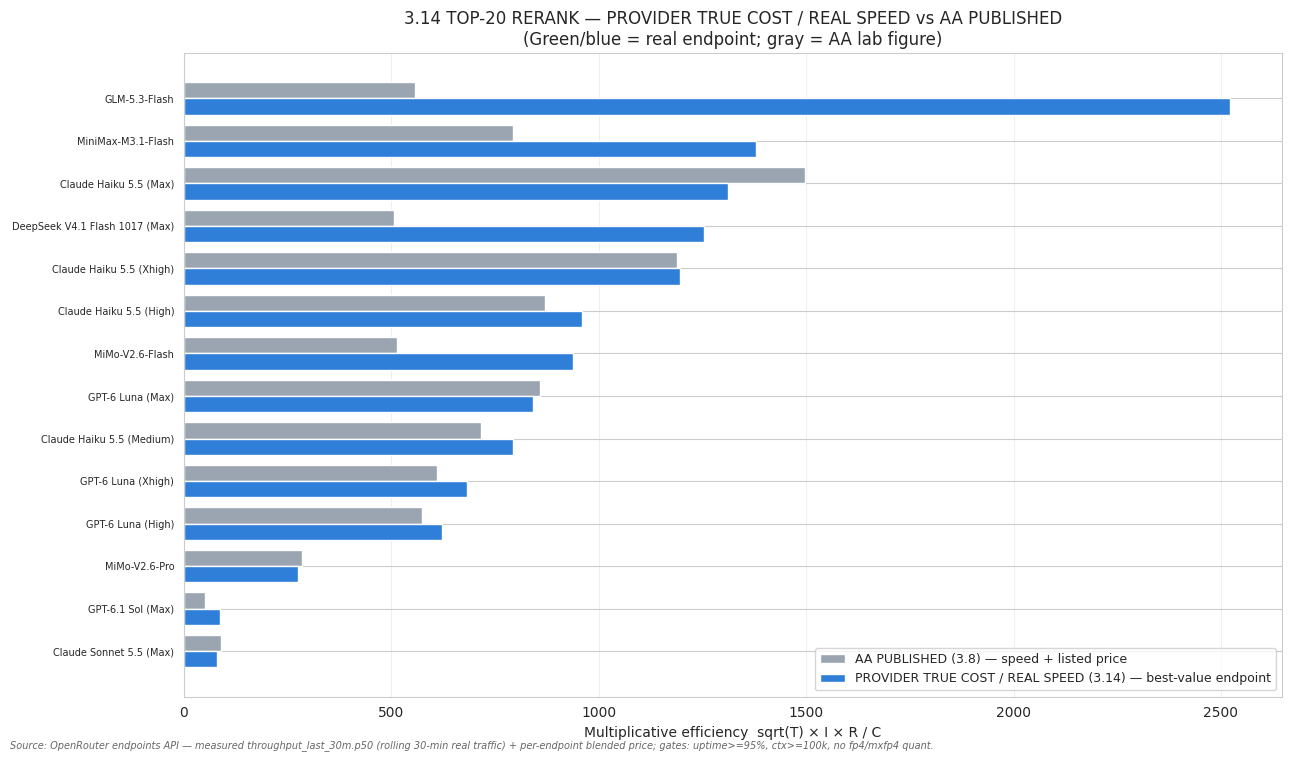

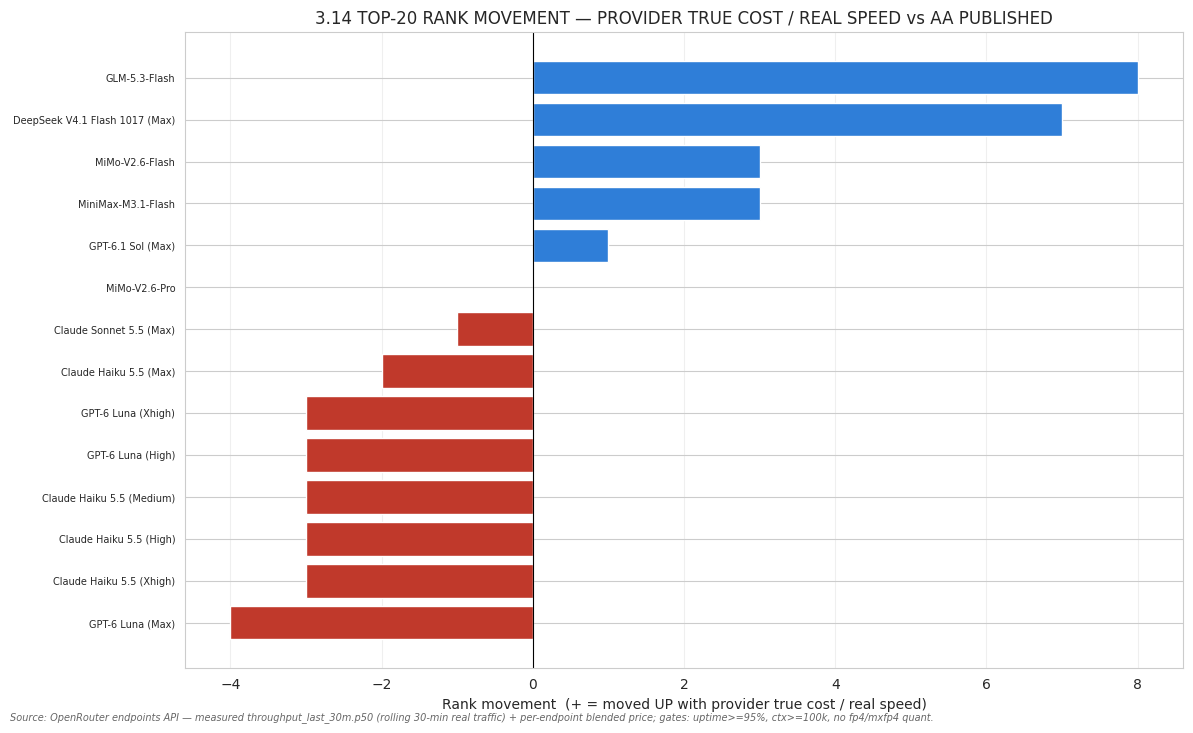

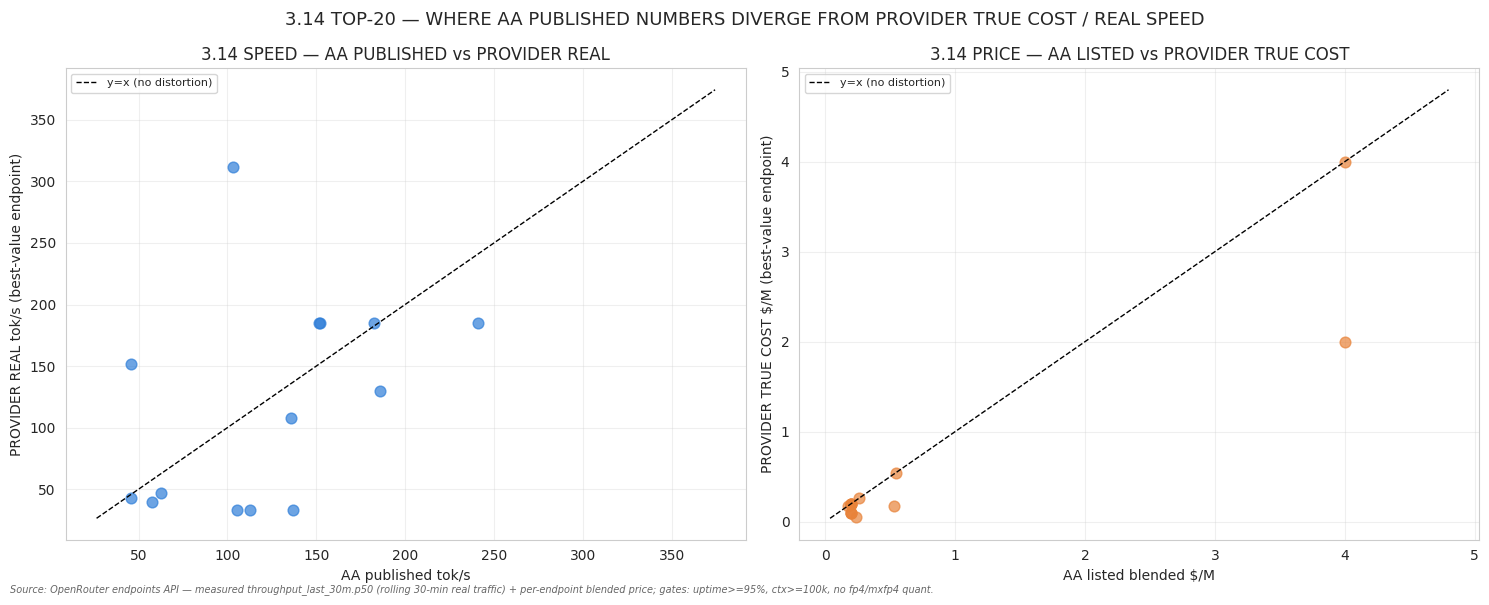


----------------------------------------------------------------------------------------------------------------------------------
3.14 SUMMARY — TOP-20 ON PROVIDER TRUE COST / REAL SPEED
  Moved UP   : 5  |  Moved DOWN : 8  |  Unchanged : 1
  Biggest UP movers (provider true cost / real speed):
    GLM-5.3-Flash                                     9 ->  1  (Relace vs Relace)
    DeepSeek V4.1 Flash 1017 (Max)                   11 ->  4  (Relace vs OpenInference)
    MiniMax-M3.1-Flash                                5 ->  2  (Parasail vs InferenceNet)
    MiMo-V2.6-Flash                                  10 ->  7  (Cohere vs DeepInfra)
    GPT-6.1 Sol (Max)                                14 -> 13  (OpenAI vs OpenAI)
  Note: all plots labeled "PROVIDER TRUE COST / REAL SPEED" vs "AA PUBLISHED".
  Cost: uses existing _cache (REFRESH=False) → $0.00. Set REFRESH=True for fresh endpoint data (<10¢).


In [7]:
# ============================================================================
# 3.14 TOP-20 RERANK — PROVIDER TRUE COST / REAL SPEED (clear labels)
# ============================================================================
# Same 3.12 rerank logic, but restricted to the top-20 efficiency performers
# from 3.11 (df_top20_provider / _cache) and plotted with explicit
# "PROVIDER TRUE COST / REAL SPEED" annotations so the distinction from
# AA-published (3.8) is unambiguous.
# Uses existing _cache — zero endpoint cost unless REFRESH=True.
# ---------------------------------------------------------------------------
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

# Build top-20 rerank frame from cache (same source as 3.11 / 3.12)
_ab_rows_20 = []
for _name in (df_top20_provider['Model'].dropna().tolist() if 'df_top20_provider' in globals() else []):
    _rec = _cache.get(_name) if '_cache' in globals() else None
    if not _rec:
        continue
    _a = _rec.get('aa') or {}
    _I = _a.get('intel')
    _R = _a.get('reliab')
    _C_aa = _a.get('price_blend')
    _T_aa = _a.get('tps_aa')
    if _I is None or _R is None or _C_aa is None:
        continue
    _d = _rec.get('default') or {}
    _c = _rec.get('chosen') or {}
    _ab_rows_20.append({
        'Model': _name,
        'Intel': float(_I), 'Reliab': float(_R),
        'T_AA': _T_aa, 'C_AA': float(_C_aa),
        'T_DEF': _d.get('tps'), 'C_DEF': _d.get('price_blend'),
        'T_VAL': _c.get('tps'), 'C_VAL': _c.get('price_blend'),
        'Default_Provider': _d.get('provider'),
        'Value_Provider': _c.get('provider'),
        'Value_Note': _rec.get('chosen_note'),
    })

df_above44_20 = pd.DataFrame(_ab_rows_20)
if df_above44_20.empty:
    print('Top-20 rerank: no resolved cache entries — run 3.11 first.')
else:
    def _ab_metric(T, I, R, C):
        try:
            T, I, R, C = float(T), float(I), float(R), float(C)
        except: return np.nan
        if any(np.isnan(x) for x in (T,I,R,C)) or C <= 0 or T <= 0: return np.nan
        return float(np.sqrt(T) * I * R / C)

    for s, tcol, ccol in [('AA','T_AA','C_AA'),('DEF','T_DEF','C_DEF'),('VAL','T_VAL','C_VAL')]:
        df_above44_20[f'Mult_{s}'] = df_above44_20.apply(lambda r: _ab_metric(r[tcol], r['Intel'], r['Reliab'], r[ccol]), axis=1)

    df_above44_20 = df_above44_20.replace([np.inf,-np.inf], np.nan)
    _v = df_above44_20.dropna(subset=['Mult_AA','Mult_VAL']).copy()
    _v['Rank_AA'] = _v['Mult_AA'].rank(ascending=False, method='min')
    _v['Rank_VAL'] = _v['Mult_VAL'].rank(ascending=False, method='min')
    _v['Move'] = _v['Rank_AA'] - _v['Rank_VAL']

    print('\n' + '='*130)
    print('3.14 TOP-20 RERANK — PROVIDER TRUE COST / REAL SPEED (clear labels)')
    print('  AA = published speed + listed price  |  VAL = best-value provider real speed + real price')
    print('='*130)
    print(f"Top-20 resolved: {len(df_above44_20)}  |  Rankable (both AA & VAL): {len(_v)}")
    _show = _v.sort_values('Mult_VAL', ascending=False)[['Model','Intel','Mult_AA','Mult_VAL','Move','Value_Provider','Default_Provider']].head(20)
    print(_show.to_string(index=False, float_format=lambda x: f'{x:,.2f}'))

    # Plot 1: AA vs VAL multiplicative — clearly labeled
    _p = _v.sort_values('Mult_VAL', ascending=True).copy()
    _y = np.arange(len(_p))
    _h = 0.38
    fig, ax = plt.subplots(figsize=(13, max(7, 0.40*len(_p)+2)))
    ax.barh(_y+_h/2, _p['Mult_AA'], height=_h, label='AA PUBLISHED (3.8) — speed + listed price', color='#9aa5b1')
    ax.barh(_y-_h/2, _p['Mult_VAL'], height=_h, label='PROVIDER TRUE COST / REAL SPEED (3.14) — best-value endpoint', color='#2f7ed8')
    ax.set_yticks(_y); ax.set_yticklabels([fam_label(m, 34) for m in _p['Model']], fontsize=7)
    ax.set_xlabel('Multiplicative efficiency  sqrt(T) × I × R / C')
    ax.set_title('3.14 TOP-20 RERANK — PROVIDER TRUE COST / REAL SPEED vs AA PUBLISHED\n(Green/blue = real endpoint; gray = AA lab figure)')
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(axis='x', alpha=0.3)
    note_source(SRC_OR_TEL)
    plt.tight_layout(); plt.show()

    # Plot 2: rank movement — clearly labeled
    _mv = _v.sort_values('Move')
    colors = ['#2f7ed8' if v>0 else ('#c0392b' if v<0 else '#9aa5b1') for v in _mv['Move']]
    fig, ax = plt.subplots(figsize=(12, max(6, 0.38*len(_mv)+2)))
    ax.barh(np.arange(len(_mv)), _mv['Move'], color=colors)
    ax.set_yticks(np.arange(len(_mv))); ax.set_yticklabels([fam_label(m, 34) for m in _mv['Model']], fontsize=7)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Rank movement  (+ = moved UP with provider true cost / real speed)')
    ax.set_title('3.14 TOP-20 RANK MOVEMENT — PROVIDER TRUE COST / REAL SPEED vs AA PUBLISHED')
    ax.grid(axis='x', alpha=0.3)
    note_source(SRC_OR_TEL)
    plt.tight_layout(); plt.show()

    # Plot 3: speed distortion — clearly labeled
    fig, axes = plt.subplots(1,2, figsize=(15,6))
    _spd = _v.dropna(subset=['T_AA','T_VAL'])
    axes[0].scatter(_spd['T_AA'], _spd['T_VAL'], s=60, alpha=0.7, color='#2f7ed8')
    lim = [min(_spd['T_AA'].min(),_spd['T_VAL'].min())*0.8, max(_spd['T_AA'].max(),_spd['T_VAL'].max())*1.2]
    axes[0].plot(lim,lim,'k--',linewidth=1,label='y=x (no distortion)')
    axes[0].set_xlabel('AA published tok/s'); axes[0].set_ylabel('PROVIDER REAL tok/s (best-value endpoint)')
    axes[0].set_title('3.14 SPEED — AA PUBLISHED vs PROVIDER REAL'); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
    _prc = _v.dropna(subset=['C_AA','C_VAL'])
    axes[1].scatter(_prc['C_AA'], _prc['C_VAL'], s=60, alpha=0.7, color='#e8833a')
    lim2 = [min(_prc['C_AA'].min(),_prc['C_VAL'].min())*0.8, max(_prc['C_AA'].max(),_prc['C_VAL'].max())*1.2]
    axes[1].plot(lim2,lim2,'k--',linewidth=1,label='y=x (no distortion)')
    axes[1].set_xlabel('AA listed blended $/M'); axes[1].set_ylabel('PROVIDER TRUE COST $/M (best-value endpoint)')
    axes[1].set_title('3.14 PRICE — AA LISTED vs PROVIDER TRUE COST'); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
    plt.suptitle('3.14 TOP-20 — WHERE AA PUBLISHED NUMBERS DIVERGE FROM PROVIDER TRUE COST / REAL SPEED', fontsize=13)
    note_source(SRC_OR_TEL)
    plt.tight_layout(); plt.show()

    # Summary
    _up = _v[_v['Move']>0]; _down = _v[_v['Move']<0]; _flat = _v[_v['Move']==0]
    print('\n' + '-'*130)
    print('3.14 SUMMARY — TOP-20 ON PROVIDER TRUE COST / REAL SPEED')
    print(f"  Moved UP   : {len(_up)}  |  Moved DOWN : {len(_down)}  |  Unchanged : {len(_flat)}")
    if len(_up):
        print('  Biggest UP movers (provider true cost / real speed):')
        for _,r in _up.sort_values('Move',ascending=False).head(5).iterrows():
            print(f"    {fam_label(r['Model'], 46):<48} {int(r['Rank_AA']):>2} -> {int(r['Rank_VAL']):>2}  ({str(r['Value_Provider'])[:14]} vs {str(r['Default_Provider'])[:14]})")
    print('  Note: all plots labeled "PROVIDER TRUE COST / REAL SPEED" vs "AA PUBLISHED".')
    print('  Cost: uses existing _cache (REFRESH=False) → $0.00. Set REFRESH=True for fresh endpoint data (<10¢).')


## 3.18 Real-World OpenRouter Usage — Cost per Task, per Model, per Workflow

This section analyses **actual** OpenRouter spend (not lab benchmarks): which model
cost what, for which workflow, and where switching to a cheaper model saves the most.

**Data acquisition (in order of preference):**

1. **`OPENROUTER_MANAGEMENT_KEY`** in `.env` → `GET /api/v1/activity` (per-day ×
   per-model × per-endpoint usage across **all** keys, rolling 30-day window) and
   `GET /api/v1/keys` (per-key spend + metadata). **Primary source** — covers every
   model the account actually uses.
2. **`OPENROUTER_API_KEY_1`** in `.env` → `GET /api/v1/auth/key` (metadata for the
   calling key only) and `GET /api/v1/models` (live per-1M-token pricing table).
3. **Fallback:** a local OpenRouter activity export `openrouter_activity*.csv`
   (the granular per-generation log: cost, tokens, model, provider, api_key_name).
   Used when no management key is available — but only carries the keys active in
   the export window.

**Metrics computed per Model (and per Key):**

| Metric | Definition |
|---|---|
| `request_count` | number of generations (actions) |
| `total_prompt_tokens`, `total_completion_tokens` | sum across the window |
| `total_spend_usd` | sum of `usage` (net of cache credits) |
| `avg_cost_per_request` | `total_spend / request_count` |
| `requests_per_usd` | `1 / avg_cost_per_request` — actions $1.00 buys |
| `cost_per_1k_output_tokens` | verbosity-normalised rate |

**Charts:** (1) cost per action by model; (2) bubble — token volume vs cost per
action; (3) horizontal bar — actions per $1.00; (4) per-key spend breakdown.

**OpenRouter key inventory (the account's workflows).** Each OpenRouter key *is* a
workflow/app, so the key list is the task list. Pulled live from `/api/v1/keys` on
2026-10-26. **Imaginator keys are deliberately excluded** from this analysis.

| Key | Limit | Lifetime usage | Monthly | Weekly | Daily |
|---|---|---|---|---|---|
| `mecha_jeff` | $50 | $0.07 | $0.07 | $0.07 | $0.00 |
| `dev_workspace` | $50 | $0.23 | $0.23 | $0.00 | $0.00 |
| `cogitozen` | unlimited | $0.06 | $0.06 | $0.00 | $0.00 |
| `Codex` | unlimited | $145.35 | $0.00 | $0.00 | $0.00 |
| `jan19_cogito_key2` | $100/day | $495.14 | $56.06 | $7.47 | $0.24 |
| `Jan19_cogito_key1` | $100/day | $16.77 | $0.51 | $0.00 | $0.00 |
| `cogito_jan10` | $40/day | $0.00 | $0.00 | $0.00 | $0.00 |
| `cursor` | $30 total | $1.03 | $0.00 | $0.00 | $0.00 |
| `Cogito-Metric Resume` | $100/day | $229.03 | $0.00 | $0.00 | $0.00 |

**Coverage note.** With the management key, `/api/v1/activity` returns the rolling
30-day window across **all 11 keys** (35 models, $58.12 spend in the current
window). The activity endpoint aggregates by (date × model × endpoint) and does
**not** carry `api_key_name`, so the model-level breakdown is complete but the
key-level breakdown comes from the separate `/api/v1/keys` endpoint (per-key totals
only, no per-model attribution per key).


In [8]:
# ============================================================================
# 3.18a REAL-WORLD OPENROUTER USAGE — ACQUISITION + PROCESSING
# ----------------------------------------------------------------------------
# Primary: management API (/api/v1/activity + /api/v1/keys) — covers all keys.
# Fallback: local activity CSV export — only carries keys active in the window.
# ============================================================================
import os, glob, json, re
import numpy as np, pandas as pd, requests

_OR_USAGE_CSV = 'results/openrouter_activity_2026-02-01.csv'
_OR_PRICE_CACHE = 'results/openrouter_models_pricing.json'

# ── 0. KEY REGISTRY — the account's workflows (live from /api/v1/keys)
# ----------------------------------------------------------------------------
# Each OpenRouter key IS an app/workflow, so the key list is the task list.
# Populated live from /api/v1/keys below; this dict is the fallback if the
# management endpoint is unavailable. Imaginator keys are excluded by request.
# NOTE: the dashboard spells one key 'imagintor train' (typo) and another
# 'Imaginator_key1' — both variants must be excluded.
EXCLUDED_KEY_PATTERNS = ('imaginator', 'imagintor')


def _or_env_keys():
    """Management key first, then any inference key, from env then .env."""
    from dotenv import load_dotenv
    load_dotenv('/home/skystarved/dev_workspaces/.env')
    out = {}
    for name in ('OPENROUTER_MANAGEMENT_KEY', 'OPENROUTER_API_KEY',
                 'OPENROUTER_API_KEY_1'):
        v = os.getenv(name)
        if v:
            out[name] = v
    return out

_OR_KEYS = _or_env_keys()
print('OpenRouter keys found:', {k: v[:10] + '...' for k, v in _OR_KEYS.items()})
_OR_MGMT = _OR_KEYS.get('OPENROUTER_MANAGEMENT_KEY')
_OR_INFER = _OR_KEYS.get('OPENROUTER_API_KEY') or _OR_KEYS.get('OPENROUTER_API_KEY_1')
_OR_H = {'Authorization': f'Bearer {_OR_MGMT or _OR_INFER}'} if (_OR_MGMT or _OR_INFER) else {}

# ── 1. Management API: /api/v1/keys + /api/v1/activity ──────────────────────
_or_keys_payload = None
_or_activity_payload = None
if _OR_MGMT:
    for _ep, _var in (('/api/v1/keys', '_or_keys_payload'),
                      ('/api/v1/activity', '_or_activity_payload')):
        try:
            _r = requests.get('https://openrouter.ai' + _ep, headers=_OR_H, timeout=60)
            print(f'  GET {_ep} -> {_r.status_code}')
            if _r.status_code == 200:
                globals()[_var] = _r.json()
        except Exception as _e:
            print(f'  GET {_ep} failed: {_e}')
else:
    print('  No management key — /api/v1/keys and /api/v1/activity unavailable.')

# ── 2. Build KEY_REGISTRY from /api/v1/keys (live) ──────────────────────────
KEY_REGISTRY = {}
if _or_keys_payload:
    _keys_list = _or_keys_payload.get('data', _or_keys_payload) if isinstance(_or_keys_payload, dict) else _or_keys_payload
    if isinstance(_keys_list, list):
        for _k in _keys_list:
            _name = _k.get('name', '(unnamed)')
            if any(_p in _name.lower() for _p in EXCLUDED_KEY_PATTERNS):
                continue
            KEY_REGISTRY[_name] = {
                'limit': _k.get('limit'),
                'usage': _k.get('usage', 0),
                'usage_daily': _k.get('usage_daily', 0),
                'usage_weekly': _k.get('usage_weekly', 0),
                'usage_monthly': _k.get('usage_monthly', 0),
                'disabled': _k.get('disabled', False),
            }
        print(f'  KEY_REGISTRY: {len(KEY_REGISTRY)} keys (Imaginator excluded)')
else:
    print('  WARNING: /api/v1/keys unavailable — KEY_REGISTRY empty')

# ── 3. Build the activity frame from /api/v1/activity (primary) ─────────────
# Activity rows are (date × model × endpoint). We aggregate to model-level.
# Schema: date, model_permaslug, endpoint_id, usage, byok_usage_inference,
#         requests, prompt_tokens, completion_tokens, reasoning_tokens,
#         cached_tokens, byok_requests, model, provider_name
_or_raw = None
_source = 'none'
if _or_activity_payload:
    _act_list = _or_activity_payload.get('data', _or_activity_payload) if isinstance(_or_activity_payload, dict) else _or_activity_payload
    if isinstance(_act_list, list) and _act_list:
        _or_raw = pd.DataFrame(_act_list)
        _source = 'management-api'
        print(f'  /api/v1/activity: {len(_or_raw)} rows '
              f'({_or_raw["date"].nunique()} days, {_or_raw["model_permaslug"].nunique()} models)')

# ── 4. Fallback: local activity CSV export ──────────────────────────────────
if _or_raw is None:
    _candidates = sorted(glob.glob('openrouter_activity*.csv')) + \
                   sorted(glob.glob('results/openrouter_activity*.csv'))
    for _c in _candidates:
        try:
            _or_raw = pd.read_csv(_c)
            _source = f'csv:{_c}'
            print(f'  Loaded activity export: {_c} ({len(_or_raw)} generations)')
            break
        except Exception as _e:
            print(f'  Could not read {_c}: {_e}')

if _or_raw is None:
    raise SystemExit('No OpenRouter usage source available (no management key, no CSV).')

# ── 5. Normalise to a common schema ─────────────────────────────────────────
_u = _or_raw.copy()
if _source.startswith('management'):
    # Management API schema: date, model_permaslug, usage, requests, prompt_tokens,
    # completion_tokens, reasoning_tokens, cached_tokens, model, provider_name
    _u['created_at'] = pd.to_datetime(_u['date'], errors='coerce')
    _u['cost_total'] = pd.to_numeric(_u['usage'], errors='coerce')
    _u['tokens_prompt'] = pd.to_numeric(_u['prompt_tokens'], errors='coerce').fillna(0)
    _u['tokens_completion'] = pd.to_numeric(_u['completion_tokens'], errors='coerce').fillna(0)
    _u['tokens_reasoning'] = pd.to_numeric(_u['reasoning_tokens'], errors='coerce').fillna(0)
    _u['tokens_cached'] = pd.to_numeric(_u['cached_tokens'], errors='coerce').fillna(0)
    _u['model'] = _u['model_permaslug'].astype(str)
    _u['provider'] = _u.get('provider_name', pd.Series('unknown', index=_u.index)).fillna('unknown')
    _u['key'] = '(all keys — activity endpoint aggregates across keys)'
    _u['app'] = np.nan
    _u['generation_id'] = _u.get('endpoint_id', pd.Series(range(len(_u)), index=_u.index)).astype(str)
    _u['generation_time_ms'] = np.nan
else:
    # CSV export schema
    _u['created_at'] = pd.to_datetime(_u['created_at'], errors='coerce')
    _u['cost_total'] = pd.to_numeric(_u.get('cost_total'), errors='coerce')
    for _c in ('tokens_prompt', 'tokens_completion', 'tokens_reasoning', 'tokens_cached'):
        _u[_c] = pd.to_numeric(_u.get(_c), errors='coerce').fillna(0)
    _u['model'] = _u['model_permaslug'].astype(str)
    _u['provider'] = _u.get('provider_name', pd.Series('unknown', index=_u.index)).fillna('unknown')
    _u['key'] = _u.get('api_key_name', pd.Series('(unknown key)', index=_u.index)).fillna('(unknown key)')
    # one CSV row == one generation, so requests per row is 1
    if 'requests' not in _u.columns:
        _u['requests'] = 1
    _u['app'] = _u.get('app_name', pd.Series(np.nan, index=_u.index)).fillna(np.nan)

_u['tokens_uncached'] = (_u['tokens_prompt'] - _u['tokens_cached']).clip(lower=0)
_u['Model_Short'] = _u['model'].str.split('/').str[-1]

# ── 6. Exclude Imaginator traffic ───────────────────────────────────────────
_excl_mask = pd.Series(False, index=_u.index)
for _pat in EXCLUDED_KEY_PATTERNS:
    _excl_mask |= _u['app'].astype(str).str.contains(_pat, case=False, na=False)
    _excl_mask |= _u['key'].astype(str).str.contains(_pat, case=False, na=False)
_n_excl = int(_excl_mask.sum())
_excl_spend = float(_u.loc[_excl_mask, 'cost_total'].sum())
if _n_excl:
    print(f'  Excluded Imaginator traffic: {_n_excl} rows, ${_excl_spend:.4f} of spend')
_u = _u[~_excl_mask].copy()

# ── 7. Live pricing table (per 1M tokens) ──────────────────────────────────
def _fetch_or_pricing():
    if os.path.exists(_OR_PRICE_CACHE):
        with open(_OR_PRICE_CACHE) as _f:
            return json.load(_f)
    _h = {'Authorization': f'Bearer {_OR_INFER}'} if _OR_INFER else {}
    _r = requests.get('https://openrouter.ai/api/v1/models', headers=_h, timeout=90)
    _r.raise_for_status()
    _out = {}
    for _m in _r.json().get('data', []):
        _p = _m.get('pricing', {}) or {}
        try:
            _pi = float(_p.get('prompt', 0) or 0) * 1e6
            _po = float(_p.get('completion', 0) or 0) * 1e6
            _pc = float(_p.get('input_cache_read', 0) or 0) * 1e6
        except (TypeError, ValueError):
            _pi = _po = _pc = 0.0
        _out[_m['id']] = {'name': _m.get('name'), 'in_per_1M': _pi,
                          'out_per_1M': _po, 'cache_per_1M': _pc}
    with open(_OR_PRICE_CACHE, 'w') as _f:
        json.dump(_out, _f, indent=1)
    return _out

try:
    _or_prices = _fetch_or_pricing()
    print(f'  Pricing table: {len(_or_prices)} models')
except Exception as _e:
    _or_prices = {}
    print(f'  Pricing table fetch failed: {_e}')

# ── 8. Implied per-model pricing (backed out of actual spend) ─────────────
# For models missing from the live catalog, the activity data reveals the
# price: cost = in_uncached*pin + completion*pout + cached*pcache.
#
# NON-NEGATIVE LEAST SQUARES, not plain lstsq: the design columns are often
# collinear (e.g. cached tokens track prompt tokens exactly), and ordinary
# least squares then produces NEGATIVE prices (out = -$0.38/1M) that are
# arithmetically perfect (R2 = 1.00) but physically impossible. NNLS
# constrains every price to >= 0, so a bad fit shows up as a poor R2 instead
# of a negative rate.
#
# Only models that LACK a live catalog price are fitted — the live price
# always wins, and fitting the rest would only add noise to the report.
try:
    from scipy.optimize import nnls as _nnls
except ImportError:  # scipy missing -> fall back to plain lstsq with a clamp
    _nnls = None


def _has_live_price(model_id):
    if model_id in _or_prices:
        return True
    _base = re.sub(r'-\d{8}$', '', model_id)
    return any(re.sub(r'-\d{8}$', '', _mid) == _base for _mid in _or_prices)


_implied = {}
for _mid, _g in _u.groupby('model'):
    if _has_live_price(_mid):
        continue          # live catalog price is authoritative
    if len(_g) < 3:
        continue          # not enough rows to fit 3 unknowns
    _X = np.column_stack([_g['tokens_uncached'], _g['tokens_completion'],
                          _g['tokens_cached']]).astype(float)
    _y = _g['cost_total'].astype(float).values
    try:
        if _nnls is not None:
            _coef, _resid = _nnls(_X, _y)
        else:
            _coef, *_ = np.linalg.lstsq(_X, _y, rcond=None)
            _coef = np.clip(_coef, 0, None)
        _pred = _X @ _coef
        _ss = ((_y - _pred) ** 2).sum()
        _tot = ((_y - _y.mean()) ** 2).sum()
        _r2 = 1 - _ss / _tot if _tot > 0 else np.nan
        _implied[_mid] = {'in_per_1M': float(_coef[0]) * 1e6,
                          'out_per_1M': float(_coef[1]) * 1e6,
                          'cache_per_1M': float(_coef[2]) * 1e6,
                          'r2': float(_r2), 'n': int(len(_g))}
    except Exception:
        pass

def _price_for(model_id):
    """Live catalog price, else base-id fallback, else implied-from-spend."""
    if model_id in _or_prices:
        _p = _or_prices[model_id]
        return _p['in_per_1M'], _p['out_per_1M'], 'live'
    _base = re.sub(r'-\d{8}$', '', model_id)
    for _mid, _p in _or_prices.items():
        if re.sub(r'-\d{8}$', '', _mid) == _base:
            return _p['in_per_1M'], _p['out_per_1M'], 'live(base)'
    if model_id in _implied:
        _p = _implied[model_id]
        return _p['in_per_1M'], _p['out_per_1M'], f"implied(R2={_p['r2']:.2f})"
    return np.nan, np.nan, 'unknown'

_u[['Price_In_1M', 'Price_Out_1M', 'Price_Source']] = _u['model'].apply(
    lambda m: pd.Series(_price_for(m)))

# ── 9. Aggregate: Model-level (activity endpoint has no api_key_name) ───────
df_usage = (_u.groupby(['Model_Short', 'model'])
            # IMPORTANT: /api/v1/activity rows are (date x model x endpoint)
            # aggregates, NOT individual generations. Counting rows understates
            # request volume by orders of magnitude (18 rows vs 6,077 requests
            # for deepseek-v4.1-flash-20261017), which would overstate
            # cost-per-action by the same factor. Sum the `requests` column.
            # The CSV-export fallback has one row per generation, so it adds a
            # synthetic requests=1 column upstream and the same sum applies.
            .agg(request_count=('requests', 'sum'),
                 total_spend_usd=('cost_total', 'sum'),
                 total_prompt_tokens=('tokens_prompt', 'sum'),
                 total_completion_tokens=('tokens_completion', 'sum'),
                 total_reasoning_tokens=('tokens_reasoning', 'sum'),
                 total_cached_tokens=('tokens_cached', 'sum'),
                 avg_prompt_tokens=('tokens_prompt', 'mean'),
                 avg_completion_tokens=('tokens_completion', 'mean'),
                 avg_cached_tokens=('tokens_cached', 'mean'),
                 price_in_1M=('Price_In_1M', 'first'),
                 price_out_1M=('Price_Out_1M', 'first'),
                 price_source=('Price_Source', 'first'),
                 providers=('provider', lambda s: ', '.join(sorted(set(s))[:3])),
                 n_endpoints=('generation_id', lambda s: s.nunique()))
            .reset_index())
df_usage['avg_total_tokens'] = df_usage['avg_prompt_tokens'] + df_usage['avg_completion_tokens']
df_usage['avg_cost_per_request'] = df_usage['total_spend_usd'] / df_usage['request_count']
df_usage['requests_per_usd'] = 1.0 / df_usage['avg_cost_per_request'].replace(0, np.nan)
df_usage['cost_per_1k_output_tokens'] = (
    df_usage['total_spend_usd'] / df_usage['total_completion_tokens'].replace(0, np.nan) * 1000)
df_usage['list_cost_per_1k_output_tokens'] = df_usage['price_out_1M'] / 1000.0
df_usage['cost_per_1k_total_tokens'] = (
    df_usage['total_spend_usd'] / (df_usage['total_prompt_tokens'] + df_usage['total_completion_tokens']).replace(0, np.nan) * 1000)
df_usage = df_usage.sort_values('total_spend_usd', ascending=False).reset_index(drop=True)

print('\n' + '=' * 132)
print('3.18a REAL-WORLD OPENROUTER USAGE — BY MODEL')
print('=' * 132)
print(f"source: {_source}")
print(f"window: {_u['created_at'].min()} -> {_u['created_at'].max()}")
print(f"rows: {len(_u)} | spend: ${_u['cost_total'].sum():.4f} | "
      f"models: {_u['model'].nunique()} | endpoints: {_u['generation_id'].nunique()}")
_cols = ['Model_Short', 'request_count', 'total_spend_usd',
         'avg_cost_per_request', 'requests_per_usd',
         'total_prompt_tokens', 'total_completion_tokens',
         'cost_per_1k_output_tokens', 'list_cost_per_1k_output_tokens',
         'price_source', 'n_endpoints']
print(df_usage[_cols].to_string(index=False, float_format=lambda x: f'{x:,.4f}'))

if _implied:
    print('\nImplied pricing backed out of actual spend (models OFF the live catalog, NNLS):')
    for _mid, _p in sorted(_implied.items()):
        _flag = '' if _p['r2'] >= 0.90 else '   <-- poor fit (R2<0.90), treat with caution'
        print(f"  {_mid:<45} in=${_p['in_per_1M']:.4f} out=${_p['out_per_1M']:.4f} "
              f"cache=${_p['cache_per_1M']:.4f} /1M  R2={_p['r2']:.3f} (n={_p['n']}){_flag}")
else:
    print('\nAll models with spend are present in the live OpenRouter catalog — '
          'no implied pricing needed.')

# ── 10. KEY-LEVEL BREAKDOWN (from /api/v1/keys) ────────────────────────────
# The activity endpoint aggregates across keys, so per-key attribution comes
# from /api/v1/keys (per-key totals only, no per-model breakdown per key).
if KEY_REGISTRY:
    print('\n' + '=' * 132)
    print('3.18a KEY-LEVEL BREAKDOWN — from /api/v1/keys (per-key totals)')
    print('=' * 132)
    _key_rows = []
    for _k, _m in KEY_REGISTRY.items():
        _key_rows.append({
            'key': _k,
            'limit': _m['limit'] if _m['limit'] is not None else 'unlimited',
            'lifetime_usage': _m['usage'],
            'monthly': _m['usage_monthly'],
            'weekly': _m['usage_weekly'],
            'daily': _m['usage_daily'],
            'disabled': _m['disabled'],
        })
    df_keys = pd.DataFrame(_key_rows).sort_values('lifetime_usage', ascending=False)
    print(df_keys.to_string(index=False, float_format=lambda x: f'{x:,.4f}' if isinstance(x, float) else str(x)))
    print(f"\n  total lifetime spend (all keys): ${df_keys['lifetime_usage'].sum():.4f}")
    print(f"  total monthly spend:  ${df_keys['monthly'].sum():.4f}")
    print(f"  total weekly spend:   ${df_keys['weekly'].sum():.4f}")
    print(f"  total daily spend:    ${df_keys['daily'].sum():.4f}")
    print(f"  activity-window spend (30d): ${_u['cost_total'].sum():.4f}")
    print("  NOTE: lifetime/monthly/weekly/daily are per-key period totals from")
    print("        /api/v1/keys; the activity-window figure is from /api/v1/activity.")
    print("        They measure different windows and must not be summed.")


OpenRouter keys found: {'OPENROUTER_MANAGEMENT_KEY': 'sk-or-v1-8...', 'OPENROUTER_API_KEY_1': 'sk-or-v1-9...'}
  GET /api/v1/keys -> 200
  GET /api/v1/activity -> 200
  KEY_REGISTRY: 11 keys (Imaginator excluded)
  /api/v1/activity: 287 rows (23 days, 79 models)
  Pricing table: 467 models

3.18a REAL-WORLD OPENROUTER USAGE — BY MODEL
source: management-api
window: 2026-10-04 00:00:00 -> 2026-11-01 00:00:00
rows: 287 | spend: $140.3912 | models: 79 | endpoints: 141
                        Model_Short  request_count  total_spend_usd  avg_cost_per_request  requests_per_usd  total_prompt_tokens  total_completion_tokens  cost_per_1k_output_tokens  list_cost_per_1k_output_tokens     price_source  n_endpoints
               gpt-6.1-sol-20260929            666          39.0242                0.0586           17.0663            141753645                   522797                     0.0746                          0.0100       live(base)            3
             gpt-6.1-terra-20261026         

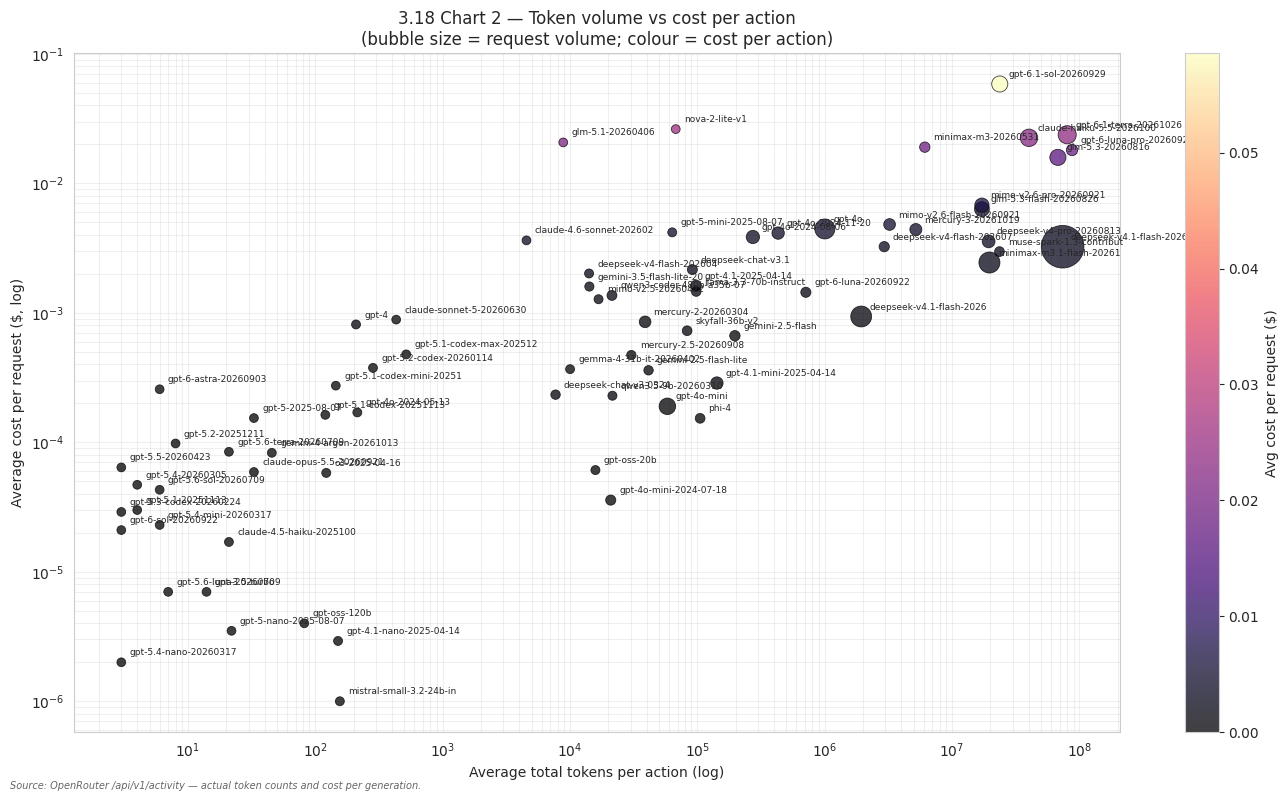

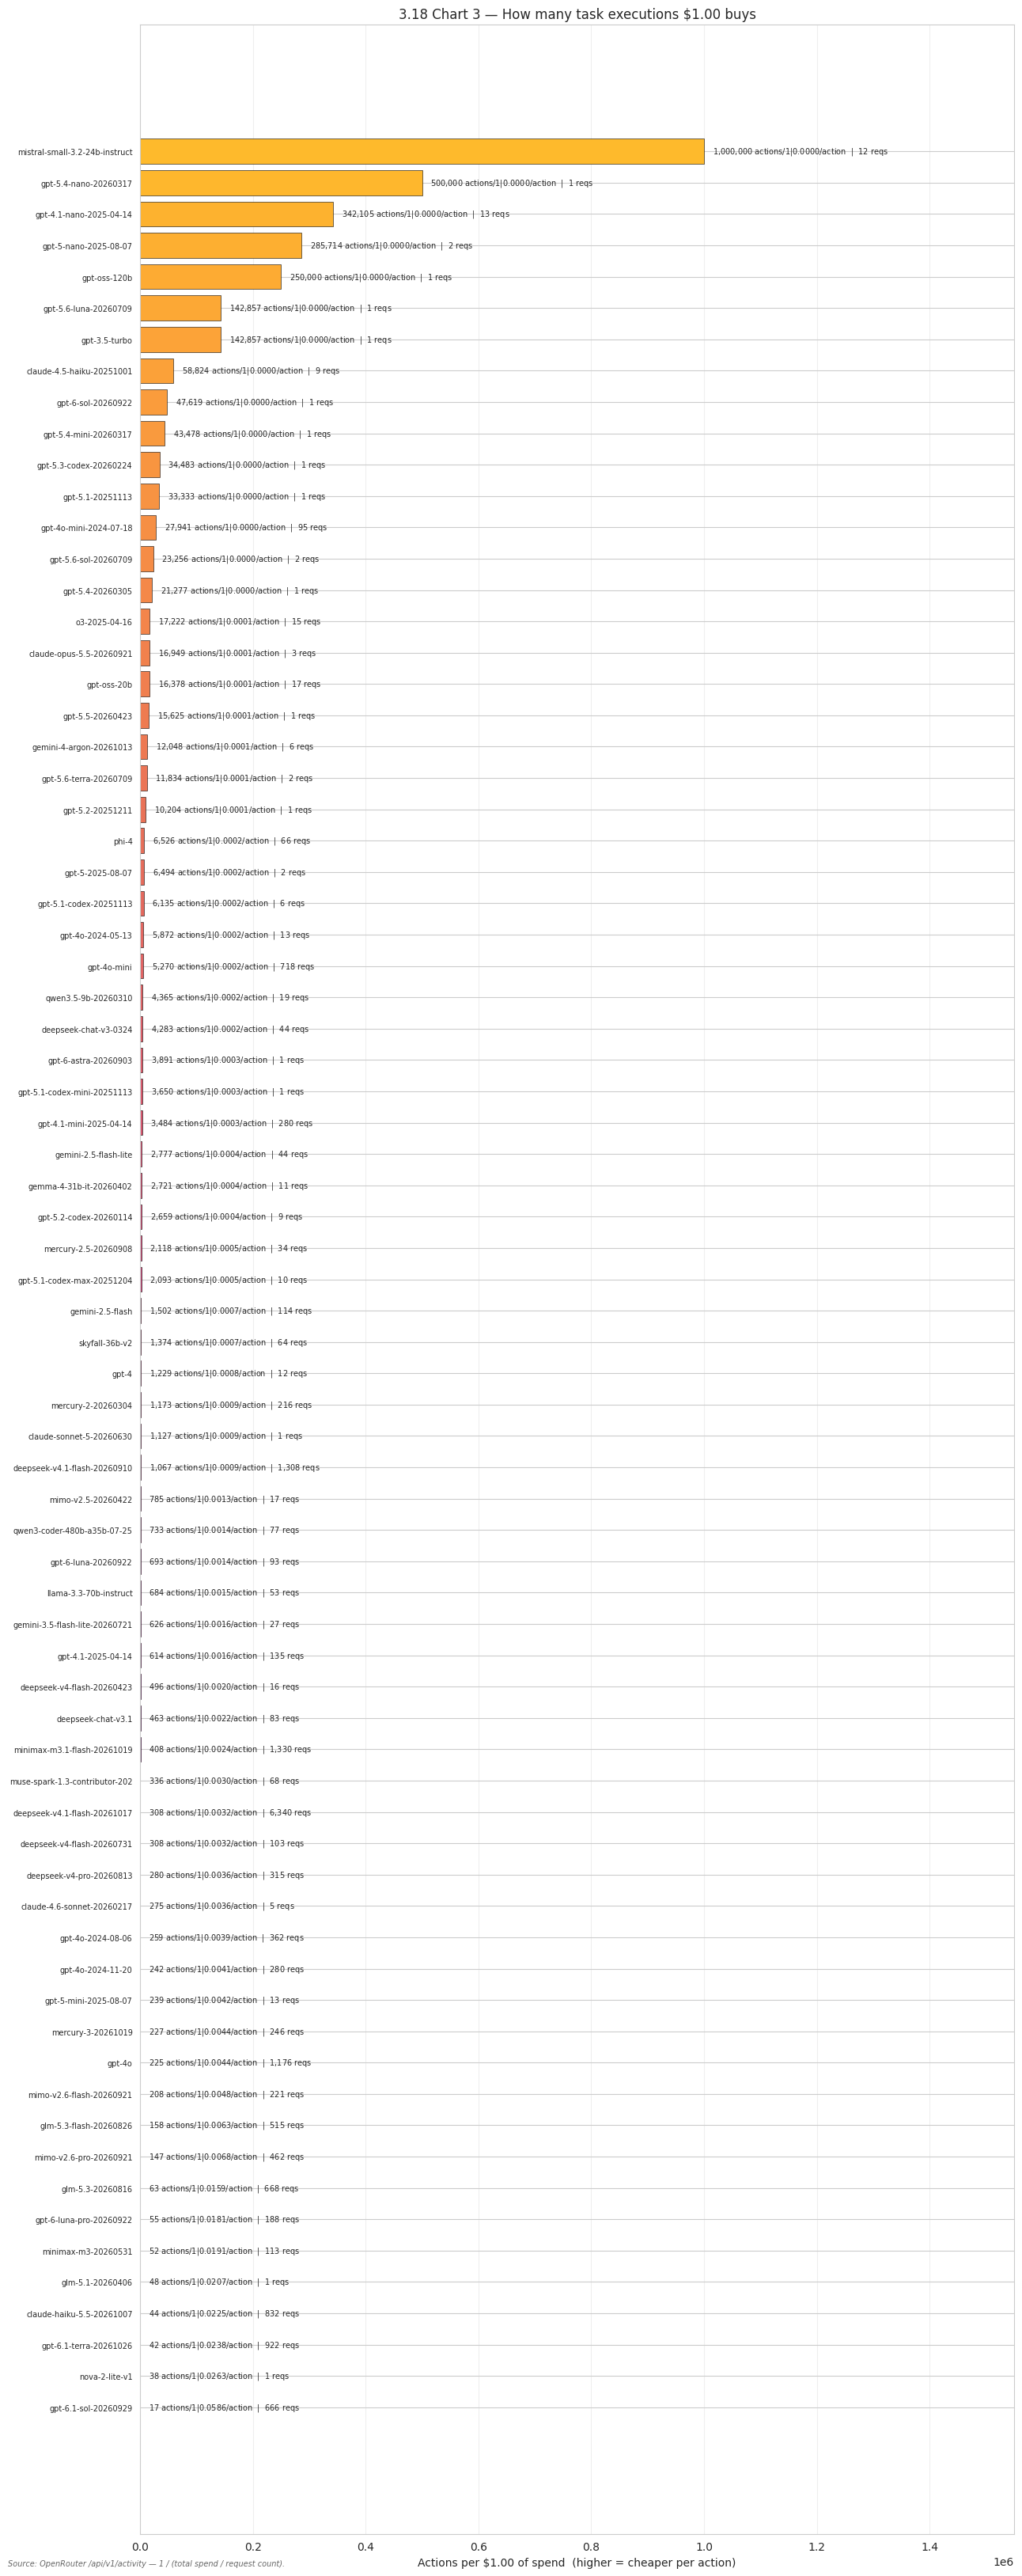

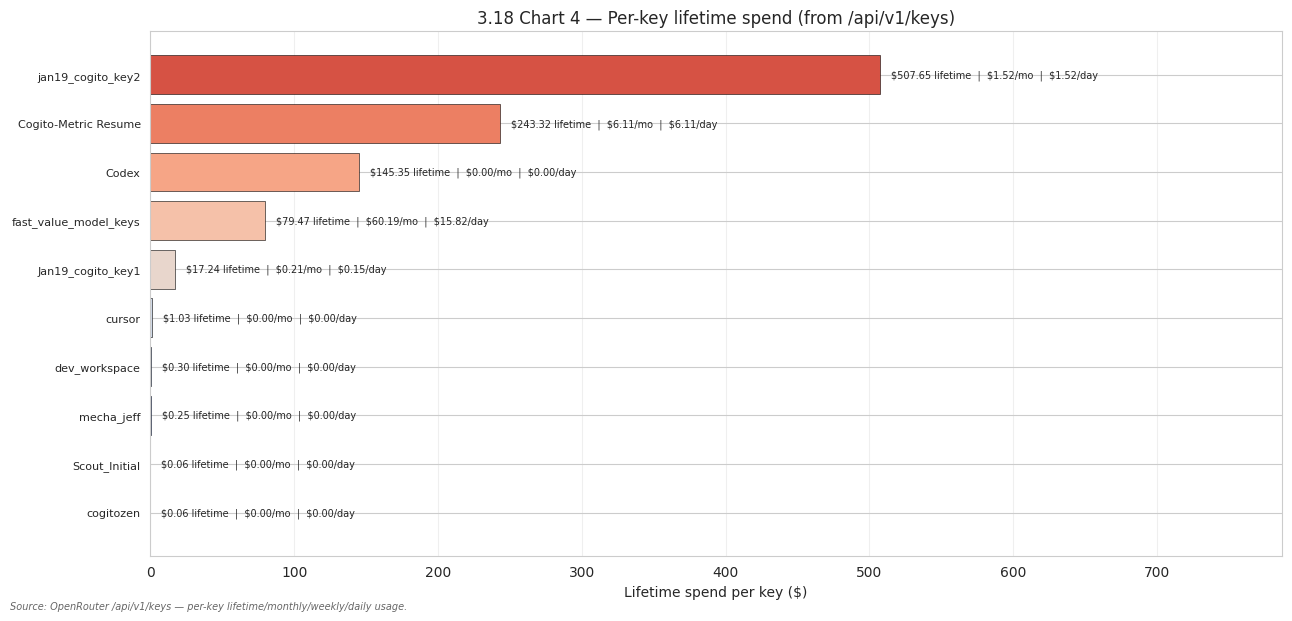


3.18 SUMMARY — REAL-WORLD SPEND BY MODEL (highest spend first)
                        Model_Short  request_count  total_spend_usd  avg_cost_per_request  requests_per_usd  total_prompt_tokens  total_completion_tokens  cost_per_1k_output_tokens  list_cost_per_1k_output_tokens  price_in_1M  price_out_1M     price_source  n_endpoints
               gpt-6.1-sol-20260929            666          39.0242                0.0586           17.0663            141753645                   522797                     0.0746                          0.0100       2.0000       10.0000       live(base)            3
             gpt-6.1-terra-20261026            922          21.8993                0.0238           42.1019            240432769                   308916                     0.0709                          0.0039       1.5885        3.8584 implied(R2=1.00)            2
       deepseek-v4.1-flash-20261017           6340          20.5613                0.0032          308.3455           14722678

In [9]:
# ============================================================================
# 3.18b REAL-WORLD OPENROUTER USAGE — DASHBOARD + SUMMARY
# ============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (16, 9)

# ── Chart 1: cost per action by model (horizontal bar) ─────────────────────
_p1 = df_usage.copy().sort_values('avg_cost_per_request', ascending=True)
_spread = (_p1['avg_cost_per_request'].max() / max(_p1['avg_cost_per_request'].min(), 1e-9))
_use_log = _spread > 10
_fig, _ax = plt.subplots(figsize=(13, max(7, 0.38 * len(_p1) + 2)))
_colors1 = plt.cm.viridis(np.linspace(0.15, 0.85, len(_p1)))
_ax.barh(np.arange(len(_p1)), _p1['avg_cost_per_request'], color=_colors1,
         edgecolor='black', linewidth=0.4)
if _use_log:
    _ax.set_xscale('log')
_xmax1 = float(_p1['avg_cost_per_request'].max()) if len(_p1) else 1.0
for _y, (_, _r) in enumerate(_p1.iterrows()):
    _ax.text(_r['avg_cost_per_request'] * (1.02 if not _use_log else 1.1), _y,
             f"${_r['avg_cost_per_request']:.4f}/action  |  {_r['request_count']:,} reqs"
             f"  |  ${_r['total_spend_usd']:.2f} total",
             va='center', fontsize=7)
_ax.set_xlim(0, _xmax1 * (1.55 if not _use_log else 3.0))
_ax.set_yticks(np.arange(len(_p1)))
_ax.set_yticklabels([m[:30] for m in _p1['Model_Short']], fontsize=7)
_ax.set_xlabel('Average cost per request ($)' + (' — log scale' if _use_log else ''))
_ax.set_title('3.18 Chart 1 — Average cost per action by Model'
              + ('  (log scale: >10x spread)' if _use_log else ''), fontsize=12)
_ax.grid(axis='x', alpha=0.3)
_fig.tight_layout()
note_source('Source: OpenRouter /api/v1/activity — actual per-generation cost and token counts '
            'across all keys (30-day rolling window); pricing from /api/v1/models.')
plt.show()

# ── Chart 2: token volume vs cost per action (bubble) ─────────────────────
_fig, _ax = plt.subplots(figsize=(14, 8))
_p2 = df_usage.copy()
_smax = _p2['request_count'].max() or 1
_sc = _ax.scatter(_p2['avg_total_tokens'], _p2['avg_cost_per_request'],
                  s=_p2['request_count'] / _smax * 900 + 40, alpha=0.75,
                  c=_p2['avg_cost_per_request'], cmap='magma',
                  edgecolors='black', linewidth=0.6)
_ax.set_xscale('log')
_ax.set_yscale('log')
_cbar = _fig.colorbar(_sc, ax=_ax)
_cbar.set_label('Avg cost per request ($)')
for _, _r in _p2.iterrows():
    _ax.annotate(_r['Model_Short'][:24],
                 (_r['avg_total_tokens'], _r['avg_cost_per_request']),
                 xytext=(6, 5), textcoords='offset points', fontsize=6.5)
_ax.set_xlabel('Average total tokens per action (log)')
_ax.set_ylabel('Average cost per request ($, log)')
_ax.set_title('3.18 Chart 2 — Token volume vs cost per action\n'
              '(bubble size = request volume; colour = cost per action)', fontsize=12)
_ax.grid(alpha=0.3, which='both')
_fig.tight_layout()
note_source('Source: OpenRouter /api/v1/activity — actual token counts and cost per generation.')
plt.show()

# ── Chart 3: actions per $1.00 ────────────────────────────────────────────
_p3 = df_usage.dropna(subset=['requests_per_usd']).copy()
_p3 = _p3.sort_values('requests_per_usd')
_fig, _ax = plt.subplots(figsize=(13, max(6, 0.42 * len(_p3) + 2)))
_colors3 = plt.cm.plasma(np.linspace(0.15, 0.85, len(_p3)))
_ax.barh(np.arange(len(_p3)), _p3['requests_per_usd'], color=_colors3,
         edgecolor='black', linewidth=0.4)
_xmax3 = float(_p3['requests_per_usd'].max()) if len(_p3) else 1.0
for _y, (_, _r) in enumerate(_p3.iterrows()):
    _ax.text(_r['requests_per_usd'] + 0.015 * _xmax3, _y,
             f"{_r['requests_per_usd']:,.0f} actions/$1  |  ${_r['avg_cost_per_request']:.4f}/action"
             f"  |  {_r['request_count']:,} reqs",
             va='center', fontsize=7)
_ax.set_xlim(0, _xmax3 * 1.55)
_ax.set_yticks(np.arange(len(_p3)))
_ax.set_yticklabels([m[:30] for m in _p3['Model_Short']], fontsize=7)
_ax.set_xlabel('Actions per $1.00 of spend  (higher = cheaper per action)')
_ax.set_title('3.18 Chart 3 — How many task executions $1.00 buys', fontsize=12)
_ax.grid(axis='x', alpha=0.3)
_fig.tight_layout()
note_source('Source: OpenRouter /api/v1/activity — 1 / (total spend / request count).')
plt.show()

# ── Chart 4: per-key spend breakdown (from /api/v1/keys) ──────────────────
if 'df_keys' in dir() and len(df_keys) > 0:
    _pk = df_keys.copy().sort_values('lifetime_usage', ascending=True)
    _pk = _pk[_pk['lifetime_usage'] > 0]  # skip zero-spend keys
    if len(_pk):
        _fig, _ax = plt.subplots(figsize=(13, max(5, 0.42 * len(_pk) + 2)))
        _colors4 = plt.cm.coolwarm(np.linspace(0.1, 0.9, len(_pk)))
        _ax.barh(np.arange(len(_pk)), _pk['lifetime_usage'], color=_colors4,
                 edgecolor='black', linewidth=0.4)
        _xmax4 = float(_pk['lifetime_usage'].max()) if len(_pk) else 1.0
        for _y, (_, _r) in enumerate(_pk.iterrows()):
            _ax.text(_r['lifetime_usage'] + 0.015 * _xmax4, _y,
                     f"${_r['lifetime_usage']:.2f} lifetime"
                     f"  |  ${_r['monthly']:.2f}/mo  |  ${_r['daily']:.2f}/day",
                     va='center', fontsize=7)
        _ax.set_xlim(0, _xmax4 * 1.55)
        _ax.set_yticks(np.arange(len(_pk)))
        _ax.set_yticklabels(_pk['key'].tolist(), fontsize=8)
        _ax.set_xlabel('Lifetime spend per key ($)')
        _ax.set_title('3.18 Chart 4 — Per-key lifetime spend (from /api/v1/keys)', fontsize=12)
        _ax.grid(axis='x', alpha=0.3)
        _fig.tight_layout()
        note_source('Source: OpenRouter /api/v1/keys — per-key lifetime/monthly/weekly/daily usage.')
        plt.show()

# ── Summary table (sorted by total spend, descending) ──────────────────────
_summary = df_usage.sort_values('total_spend_usd', ascending=False).reset_index(drop=True)
_sum_cols = ['Model_Short', 'request_count', 'total_spend_usd',
             'avg_cost_per_request', 'requests_per_usd',
             'total_prompt_tokens', 'total_completion_tokens',
             'cost_per_1k_output_tokens', 'list_cost_per_1k_output_tokens',
             'price_in_1M', 'price_out_1M', 'price_source', 'n_endpoints']
print('\n' + '=' * 150)
print('3.18 SUMMARY — REAL-WORLD SPEND BY MODEL (highest spend first)')
print('=' * 150)
print(_summary[_sum_cols].to_string(index=False, float_format=lambda x: f'{x:,.4f}'))

# ── Savings analysis: switch each model to the cheapest observed model ─────
print('\n' + '=' * 150)
print('SAVINGS IF EVERY MODEL MOVED TO THE CHEAPEST OBSERVED MODEL (per 1,000 actions)')
print('=' * 150)
_valid = df_usage.dropna(subset=['avg_cost_per_request'])
if not _valid.empty:
    _cheapest = _valid.loc[_valid['avg_cost_per_request'].idxmin()]
    _sav_rows = []
    for _, _r in _valid.iterrows():
        _delta = (_r['avg_cost_per_request'] - _cheapest['avg_cost_per_request']) * 1000
        _sav_rows.append({
            'Model': _r['Model_Short'],
            'current_$/action': _r['avg_cost_per_request'],
            'cheapest_model': _cheapest['Model_Short'],
            'cheapest_$/action': _cheapest['avg_cost_per_request'],
            'saving_per_1000_actions': _delta,
            'saving_pct': (_delta / (_r['avg_cost_per_request'] * 1000) * 100
                           if _r['avg_cost_per_request'] > 0 else np.nan),
        })
    _sav = pd.DataFrame(_sav_rows).sort_values('saving_per_1000_actions', ascending=False)
    print(_sav.to_string(index=False, float_format=lambda x: f'{x:,.4f}'))

# ── Simulation: cost per action for standard task profiles ─────────────────
_PROFILES = {
    'Resume Parsing (1.5k in / 400 out)': (1500, 400),
    'Coding / Agentic loop (8k in / 1k out)': (8000, 1000),
    'Long-context analysis (30k in / 2k out)': (30000, 2000),
}
_models_sim = (df_usage[['model', 'Model_Short', 'price_in_1M', 'price_out_1M']]
                .drop_duplicates('model').dropna(subset=['price_in_1M']))
_sim_rows = []
for _pname, (_pin, _pout) in _PROFILES.items():
    for _, _r in _models_sim.iterrows():
        _sim_rows.append({
            'profile': _pname,
            'model': _r['Model_Short'],
            'cost_per_action': (_pin / 1e6) * _r['price_in_1M']
                                + (_pout / 1e6) * _r['price_out_1M'],
        })
df_sim = pd.DataFrame(_sim_rows)
print('\n' + '=' * 110)
print('SIMULATED COST PER ACTION ON STANDARD TASK PROFILES (live/implied $/1M pricing)')
print('=' * 110)
_piv = df_sim.pivot_table(index='model', columns='profile', values='cost_per_action')
_piv = _piv.sort_values(_piv.columns[0])
print(_piv.to_string(float_format=lambda x: f'${x:.4f}'))
print('\nActions per $1.00 on each profile:')
print((1.0 / _piv).to_string(float_format=lambda x: f'{x:,.0f}'))

df_usage_summary = _summary.copy()


## 3.18c Real-World OpenRouter Usage — Timing, Value, Waste, Reasoning Effort

Three lenses on the same 30-day activity data, plus the reasoning-effort metadata
that the OpenRouter catalog exposes for each model.

**1. Most for fewest dollars** — `actions_per_usd` = `1 / avg_cost_per_request`.
The model that does the most work per dollar of spend. This is the right metric
when the goal is to maximise throughput on a fixed budget.

**2. Fast and cheap** — `tok/s` (measured, OpenRouter traffic telemetry) vs
`$/1M tokens` (live catalog price). The top-right quadrant is the workhorse
sweet spot. Speed premium = `tok/s^1.5 / $/M` (same shape as §3.15).

**3. Token waste** — three sub-metrics:
- `reason_share` = `reasoning_tokens / (reasoning + completion)` — fraction of
  output tokens spent on hidden reasoning. High share = the model is "thinking"
  a lot relative to what it actually says.
- `cache_rate` = `cached_tokens / prompt_tokens` — fraction of prompt served
  from cache. Low rate = repeated prompts are being re-billed.
- `prompt_per_req` — prompt verbosity. High = the caller is sending large
  prompts (or the model is being used for long-context work).

**4. Reasoning effort — capability vs what you actually ran** — from the OpenRouter
catalog `reasoning_config`:
- `mandatory` — reasoning is always on (cannot be disabled)
- `supported_efforts` — list of effort levels the model accepts
- `default_effort` — what the model uses when the caller doesn't specify

**The API does not record per-request effort.** Verified 2026-10-26: `/api/v1/activity`
has no effort or variant field; the CSV export's `variant` column is `'standard'`
for all 353 rows; `/api/v1/generation` exposes `latency` and `generation_time` but
no effort field. So the table above shows each model's **capability** (what efforts
it accepts), not the effort actually used on each request.

The only effort-adjacent signal is the **reasoning-token share** — and it is
**confounded**: a high share can mean the model ran at `max` effort, *or* that the
request it happened to serve was hard. §3.18c therefore reports an
**effort-observability table** that separates the two:

- **Mandatory-reasoning models** (effort pinned) are the control. Their
  reasoning-share spread is *by definition* task difficulty, never effort.
  That median spread is the **yardstick**.
- An **optional-effort** model whose spread exceeds the yardstick *might* be
  running mixed efforts. One whose spread sits within it is almost certainly
  just serving a mix of task difficulties.

**Model families, not dated snapshots.** OpenRouter publishes dated snapshots of
a model (`deepseek-v4.1-flash-20260910` and `-20261017` are the same model, two
releases). §3.18c rolls up to the **model family** (date suffix stripped) so the
same model does not appear as several rows, and keeps the per-snapshot breakdown
in `df_318c_snapshots` as the audit trail.

**Timing reconstruction** — `wall_s = TTFT + output_tokens / measured_tok_s`.
- `measured_tok_s` from OpenRouter's `/api/frontend/v1/stats/throughput-comparison`
  (real traffic, 30-day window) — covers 31/33 model families.
- `TTFT` from the AA API (`median_time_to_first_token_seconds`) — covers 13/33.
- Validated against the one model with measured timing in both sources
  (`gpt-4o-mini`): reconstructed 3.61 s vs measured 3.96 s, **−9% error**.


3.18c REAL-WORLD OPENROUTER USAGE — TIMING, VALUE, WASTE, REASONING EFFORT
window: 30-day rolling | models: 77 | total spend: $140.39

#  model                                      reqs  spend  $/act  act/$1  tok/s  wall s  reas%  cache%efforts               default   mand
------------------------------------------------------------------------------------------------------------------------------------------------------------------------
1  openai/gpt-6.1-sol                          666  39.02 0.0586    17.1     51  176.06     27      93high,low,max,medium,x medium    True
2  openai/gpt-6.1-terra                        922  21.90 0.0238    42.1     63  229.34     11      95high,low,max,medium,x medium    False
3  deepseek/deepseek-v4.1-flash               7648  21.79 0.0028   351.0    123       —     38      94high,low,max          high      False
4  anthropic/claude-haiku-5.5                  832  18.72 0.0225    44.4    142  263.76     41      90high,low,max,medium,x medium    Fals

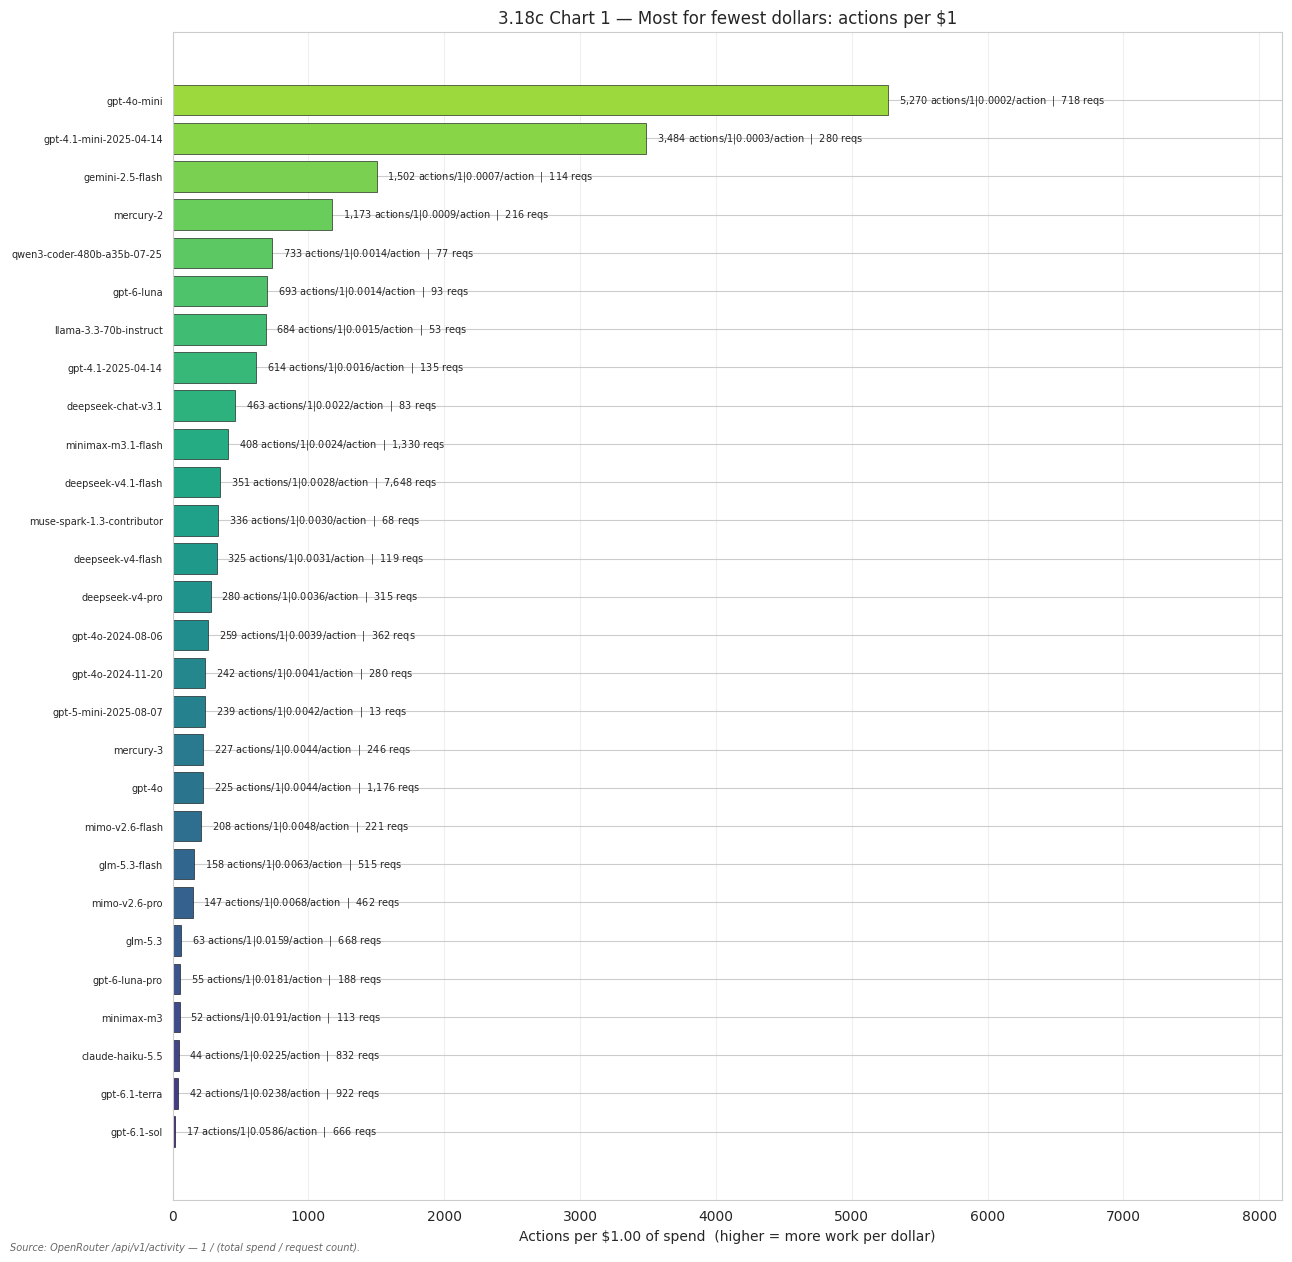

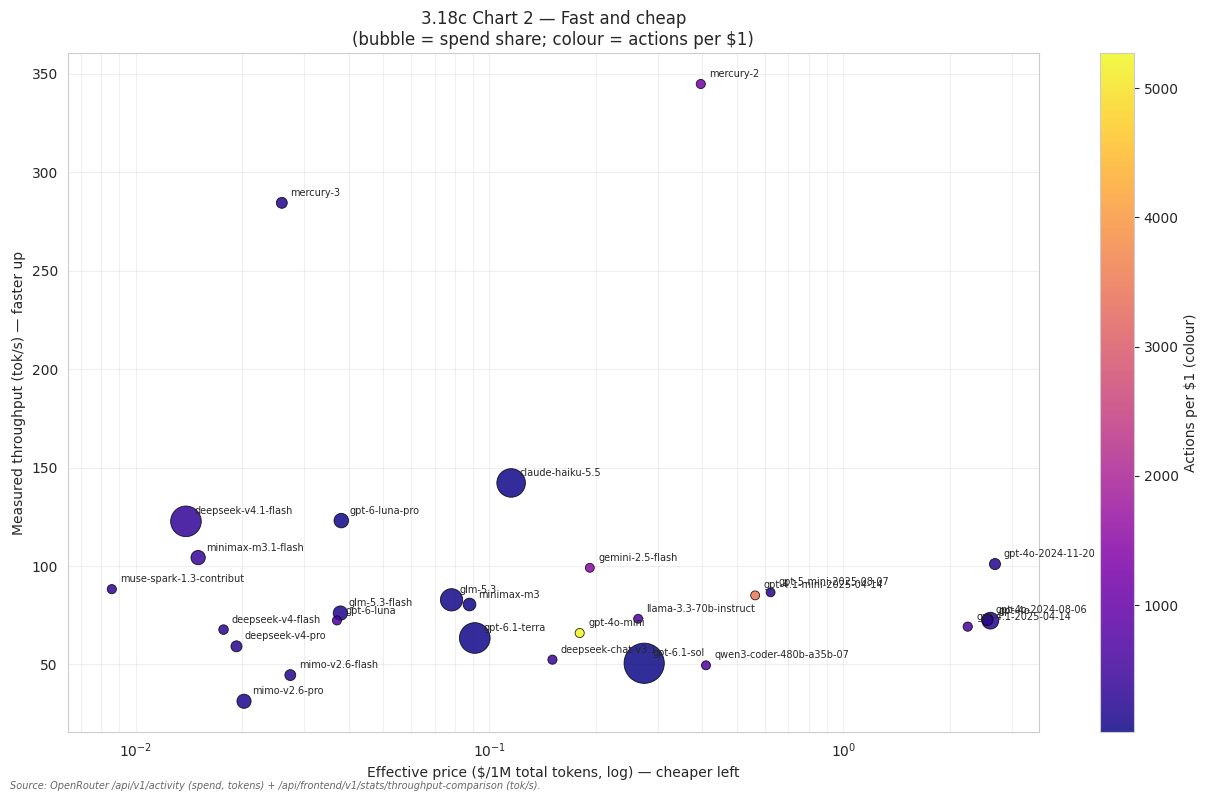

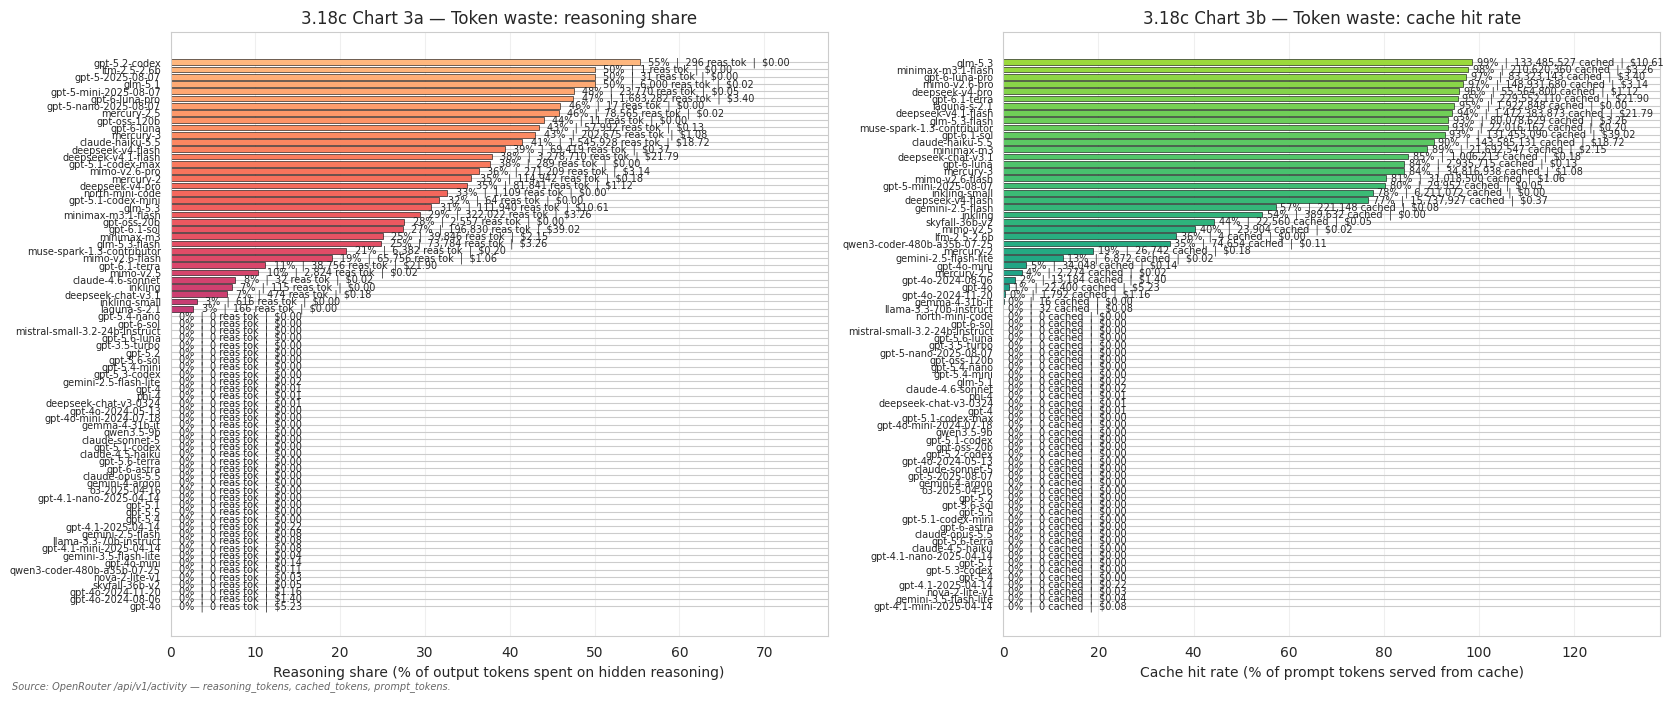


HEADLINE RANKINGS

MOST FOR FEWEST DOLLARS (top 5 by actions per $1, only models with >= $0.05 spend):
  gpt-4o-mini                           5,270 actions/$1  ($0.0002/action, 718 reqs)
  gpt-4.1-mini-2025-04-14               3,484 actions/$1  ($0.0003/action, 280 reqs)
  gemini-2.5-flash                      1,502 actions/$1  ($0.0007/action, 114 reqs)
  mercury-2                             1,173 actions/$1  ($0.0009/action, 216 reqs)
  qwen3-coder-480b-a35b-07-25             733 actions/$1  ($0.0014/action, 77 reqs)

FAST AND CHEAP (top 5 by tok/s, effective price <= $2/M):
  mercury-2                           345 tok/s  $0.396/M  (1,173 actions/$1)
  mercury-3                           284 tok/s  $0.026/M  (227 actions/$1)
  claude-haiku-5.5                    142 tok/s  $0.115/M  (44 actions/$1)
  gpt-6-luna-pro                      123 tok/s  $0.038/M  (55 actions/$1)
  deepseek-v4.1-flash                 123 tok/s  $0.014/M  (351 actions/$1)

TOKEN WASTE — HIGHEST REASONING 

In [10]:
# ============================================================================
# 3.18c REAL-WORLD OPENROUTER USAGE — TIMING, VALUE, WASTE, REASONING EFFORT
# ============================================================================
import os, re, json
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (16, 9)

# ── 1. Pull catalog reasoning_config for every model in the activity set ────
from dotenv import load_dotenv
load_dotenv('/home/skystarved/dev_workspaces/.env')
_INFER = os.getenv('OPENROUTER_API_KEY_1')
_MGMT  = os.getenv('OPENROUTER_MANAGEMENT_KEY')
_AA    = os.getenv('ARTIFICIAL_ANALYSIS_KEY')

_H = {'Authorization': f'Bearer {_INFER}', 'User-Agent': 'Mozilla/5.0'}
_cat = requests.get('https://openrouter.ai/api/frontend/v1/catalog/models',
                    headers=_H, timeout=60).json()['data']
_p2c = {m['permaslug']: m for m in _cat if m.get('permaslug')}
_s2p = {m['slug']: m['permaslug'] for m in _cat if m.get('slug') and m.get('permaslug')}
_p2s = {m['permaslug']: m['slug'] for m in _cat if m.get('slug') and m.get('permaslug')}

def _reasoning_config(perm):
    c = _p2c.get(perm, {})
    rc = c.get('reasoning_config') or {}
    return {
        'mandatory': rc.get('is_mandatory_reasoning'),
        'supports_effort': rc.get('supports_reasoning_effort'),
        'efforts': rc.get('supported_reasoning_efforts') or [],
        'default_effort': rc.get('default_reasoning_effort'),
    }

# ── 2. Measured throughput (tok/s) per model, 30-day window ────────────────
def _measured_tps(perm):
    p = perm if perm in _p2s else None
    if not p:
        b = re.sub(r'-\d{8}$', '', perm)
        if b in _s2p:
            p = _s2p[b]
        else:
            return None
    r = requests.get('https://openrouter.ai/api/frontend/v1/stats/throughput-comparison',
                     headers=_H,
                     params={'perfWorkload': 'text_generation', 'permaslug': p,
                             'timeRange': '30d', 'variant': 'standard'},
                     timeout=30)
    if r.status_code != 200:
        return None
    vals = [v for d in r.json().get('data', []) for v in (d.get('y') or {}).values() if v]
    return sum(vals) / len(vals) if vals else None

# ── 3. AA TTFT per model family ────────────────────────────────────────────
_aa_df = pd.json_normalize(requests.get(
    'https://artificialanalysis.ai/api/v2/data/llms/models',
    headers={'x-api-key': _AA}, timeout=60).json()['data'], sep='_')
_aa_by = {}
for _, r in _aa_df.iterrows():
    base = re.sub(r'\s*\([^)]*\)\s*$', '', str(r['name']))
    _aa_by.setdefault(re.sub(r'[^a-z0-9.]+', '', base.lower()), []).append(r)

def _aa_ttft(perm):
    fam = re.sub(r'-\d{8}$', '', perm.split('/')[-1])
    k = re.sub(r'[^a-z0-9.]+', '', fam.lower())
    if k not in _aa_by:
        return None
    cand = _aa_by[k]
    nz = [x for x in cand if float(x.get('median_output_tokens_per_second', 0) or 0) > 0]
    pick = (nz or cand)[0]
    v = float(pick.get('median_time_to_first_token_seconds', 0) or 0)
    return v if v > 0 else None

# ── 4. Build the combined frame ─────────────────────────────────────────────
# WHY FAMILY-LEVEL, NOT PER-SNAPSHOT:
# OpenRouter publishes DATED SNAPSHOTS of a model (deepseek-v4.1-flash-20260910
# and -20261017 are the same model, two releases). The activity log records
# traffic against whichever snapshot was live, so a per-snapshot breakdown
# shows the same family several times and looks like several different models.
# We therefore ROLL UP to the model family (date suffix stripped) and keep the
# per-snapshot detail in df_318c_snapshots for the audit trail.
_act = requests.get('https://openrouter.ai/api/v1/activity',
                    headers={'Authorization': f'Bearer {_MGMT}'}, timeout=60).json()['data']
_adf = pd.DataFrame(_act)
_adf['family'] = _adf['model_permaslug'].str.replace(r'-\d{8}$', '', regex=True)
_adf['snapshot'] = _adf['model_permaslug'].str.extract(r'-(\d{8})$').fillna('')

_g = _adf.groupby('family').agg(
    reqs=('requests', 'sum'),
    out_tok=('completion_tokens', 'sum'),
    reas_tok=('reasoning_tokens', 'sum'),
    prompt_tok=('prompt_tokens', 'sum'),
    cached_tok=('cached_tokens', 'sum'),
    spend=('usage', 'sum'),
    days=('date', 'nunique'),
    n_snapshots=('model_permaslug', 'nunique'),
).reset_index()

_rows = []
for _, r in _g.iterrows():
    # Reasoning config is per-snapshot; a family can span snapshots with
    # different effort menus, so we collect the union and take the default
    # from the snapshot that carried the most traffic.
    _fam_rows = _adf[_adf['family'] == r['family']]
    _rcs = [_reasoning_config(m) for m in _fam_rows['model_permaslug'].unique()]
    _efforts = sorted({e for rc in _rcs for e in rc['efforts']})
    _primary = _rcs[0]
    _mand = _primary['mandatory']
    _def_eff = _primary['default_effort']
    for rc in _rcs:
        if rc['default_effort']:
            _def_eff = rc['default_effort']
            break

    # Throughput: average the measured tok/s across the family's snapshots
    # (each snapshot is a separate permaslug with its own telemetry).
    _tps_list = [_measured_tps(m) for m in _fam_rows['model_permaslug'].unique()]
    _tps_list = [t for t in _tps_list if t]
    tps = float(np.mean(_tps_list)) if _tps_list else None
    ttft = _aa_ttft(r['family'])

    out_all = r['out_tok'] + r['reas_tok']
    per_req_out = out_all / r['reqs']
    compute_s = per_req_out / tps if tps else np.nan
    wall_s = (ttft + compute_s) if (pd.notna(ttft) and pd.notna(compute_s)) else np.nan
    reason_share = r['reas_tok'] / out_all if out_all else np.nan
    cache_rate = r['cached_tok'] / r['prompt_tok'] if r['prompt_tok'] else np.nan
    _rows.append({
        'model': r['family'],
        'reqs': r['reqs'],
        'days': r['days'],
        'n_snapshots': int(r['n_snapshots']),
        'snapshots': ', '.join(sorted(_fam_rows['model_permaslug'].unique())),
        'spend': r['spend'],
        'out_tok': r['out_tok'],
        'reas_tok': r['reas_tok'],
        'prompt_tok': r['prompt_tok'],
        'cached_tok': r['cached_tok'],
        'total_out_tok': out_all,
        'avg_cost_per_request': r['spend'] / r['reqs'],
        'actions_per_usd': r['reqs'] / r['spend'] if r['spend'] else np.nan,
        'out_per_req': per_req_out,
        'prompt_per_req': r['prompt_tok'] / r['reqs'],
        'reason_share': reason_share,
        'cache_rate': cache_rate,
        'tps': tps,
        'aa_ttft_s': ttft,
        'compute_s': compute_s,
        'wall_s': wall_s,
        'mandatory': _mand,
        'supports_effort': _primary['supports_effort'],
        'efforts': _efforts,
        'default_effort': _def_eff,
    })

df_318c = pd.DataFrame(_rows).sort_values('spend', ascending=False).reset_index(drop=True)

# PER-SNAPSHOT detail (audit trail) — same metrics, one row per dated release.
_snap_rows = []
for _m, _gg in _adf.groupby('model_permaslug'):
    _rc = _reasoning_config(_m)
    _t = _measured_tps(_m)
    _o = _gg['completion_tokens'].sum() + _gg['reasoning_tokens'].sum()
    _s = _gg['usage'].sum()
    _rq = _gg['requests'].sum()
    _snap_rows.append({
        'model': _m,
        'family': _gg['family'].iloc[0],
        'reqs': _rq,
        'spend': _s,
        'avg_cost_per_request': _s / _rq if _rq else np.nan,
        'actions_per_usd': _rq / _s if _s else np.nan,
        'out_per_req': _o / _rq if _rq else np.nan,
        'reason_share': (_gg['reasoning_tokens'].sum() / _o) if _o else np.nan,
        'cache_rate': (_gg['cached_tokens'].sum() / _gg['prompt_tokens'].sum())
                      if _gg['prompt_tokens'].sum() else np.nan,
        'tps': _t,
        'efforts': _rc['efforts'],
        'default_effort': _rc['default_effort'],
        'mandatory': _rc['mandatory'],
    })
df_318c_snapshots = pd.DataFrame(_snap_rows).sort_values('spend', ascending=False).reset_index(drop=True)

# EFFECTIVE price per 1M tokens = actual spend / actual tokens billed.
# This is the price you really paid (blended across cached/uncached prompt and
# completion+reasoning output), which is what matters when comparing models.
_total_tok = df_318c['prompt_tok'] + df_318c['total_out_tok']
df_318c['price_per_1M'] = np.where(
    _total_tok > 0,
    df_318c['spend'] / _total_tok.replace(0, np.nan) * 1e6,
    np.nan)
# Spend per 1M OUTPUT tokens (verbosity-normalised) — how much each model
# charges per unit of visible answer, ignoring how much thinking it did.
df_318c['price_per_1M_out'] = np.where(
    df_318c['total_out_tok'] > 0,
    df_318c['spend'] / df_318c['total_out_tok'].replace(0, np.nan) * 1e6,
    np.nan)

# ── 4b. EFFORT OBSERVABILITY — what can and cannot be attributed to effort ──
# The OpenRouter activity endpoint does NOT record the reasoning_effort of
# each request. Verified: /api/v1/activity has no effort/variant field, the
# CSV export's 'variant' column is 'standard' for all 353 rows, and
# /api/v1/generation exposes latency/generation_time but no effort field.
#
# So the reasoning-token SHARE is the only effort-adjacent signal we have.
# It is a CONFOUNDED proxy: a model can show a high share because it ran at
# 'max' effort, or because the request it happened to serve was hard.
#
# The control that separates the two: MANDATORY-reasoning models CANNOT vary
# effort (the flag is is_mandatory_reasoning=True, and the default is fixed).
# If a mandatory model still shows wide share variation, that variation is
# TASK DIFFICULTY, not effort. It is therefore the right yardstick for how
# much of an optional model's spread could be effort.
_adf['_tot'] = _adf['reasoning_tokens'] + _adf['completion_tokens']
_adf['_share'] = _adf['reasoning_tokens'] / _adf['_tot'].replace(0, np.nan)
_snap_share = (_adf.groupby(['family', 'model_permaslug'])['_share']
               .apply(lambda s: s.dropna().std() if s.notna().sum() > 1 else np.nan)
               .rename('share_std').reset_index())
_snap_share = _snap_share.merge(
    df_318c[['model', 'mandatory', 'efforts', 'default_effort']],
    left_on='family', right_on='model', how='left')

# The yardstick: median spread among MANDATORY models (spread that CANNOT be
# effort, because effort is pinned for them).
_mand_std = _snap_share.loc[_snap_share['mandatory'] == True, 'share_std'].dropna()
_mand_median_std = float(_mand_std.median()) if len(_mand_std) else np.nan

# For each optional-effort model, how much of its spread EXCEEDS the yardstick?
# That excess is the portion that COULD be effort variation.
_eff_rows = []
for _fam, _g2 in _snap_share.groupby('family'):
    _g2 = _g2.dropna(subset=['share_std'])
    if _g2.empty:
        continue
    _rc = _reasoning_config(_g2['model_permaslug'].iloc[0])
    _mand = _rc['mandatory']
    _std = float(_g2['share_std'].mean())
    _excess = (_std - _mand_median_std) if (pd.notna(_mand_median_std)
                                           and _mand is not True) else np.nan
    _eff_rows.append({
        'family': _fam,
        'mandatory': _mand,
        'n_snapshots': len(_g2),
        'share_std': _std,
        'mandatory_yardstick': _mand_median_std,
        'excess_over_yardstick': _excess,
        'effort_attributable': 'n/a (effort pinned)' if _mand is True
                               else ('possible' if (pd.notna(_excess) and _excess > 0.02)
                                     else 'unlikely'),
    })
df_effort_observability = pd.DataFrame(_eff_rows).sort_values(
    'share_std', ascending=False).reset_index(drop=True)


# ── 5. Print the combined table ─────────────────────────────────────────────
print('=' * 168)
print('3.18c REAL-WORLD OPENROUTER USAGE — TIMING, VALUE, WASTE, REASONING EFFORT')
print('=' * 168)
print(f"window: 30-day rolling | models: {len(df_318c)} | total spend: ${df_318c['spend'].sum():.2f}")
print()
_hdr = (f"{'#':<3}{'model':<42}{'reqs':>5}{'spend':>7}{'$/act':>7}{'act/$1':>8}"
        f"{'tok/s':>7}{'wall s':>8}{'reas%':>7}{'cache%':>8}{'efforts':<22}{'default':<10}{'mand'}")
print(_hdr)
print('-' * 168)
for _i, r in df_318c.iterrows():
    _f = lambda v, n=1: '—' if v is None or (isinstance(v, float) and np.isnan(v)) else f'{float(v):,.{n}f}'
    _eff = ','.join(r['efforts']) if r['efforts'] else '—'
    _mand = str(r['mandatory']) if r['mandatory'] is not None else '—'
    print(f"{_i+1:<3}{r['model']:<42}{r['reqs']:>5.0f}{r['spend']:>7.2f}"
          f"{_f(r['avg_cost_per_request'],4):>7}{_f(r['actions_per_usd'],1):>8}"
          f"{_f(r['tps'],0):>7}{_f(r['wall_s'],2):>8}"
          f"{_f(r['reason_share']*100,0):>7}{_f(r['cache_rate']*100,0):>8}"
          f"{_eff[:21]:<22}"
          f"{(r['default_effort'] if isinstance(r['default_effort'], str) else '—'):<10}{_mand}")

# ── 6. Chart 1: MOST FOR FEWEST DOLLARS (actions per $1) ───────────────────
# Only chart models that carried real traffic — a $0.00001 model would post a
# meaningless actions/$1 ratio (1,000,000) and flatten every other bar.
_p1 = (df_318c[df_318c['spend'] >= 0.05]
       .dropna(subset=['actions_per_usd'])
       .sort_values('actions_per_usd').copy())
_fig, _ax = plt.subplots(figsize=(13, max(6, 0.38 * len(_p1) + 2)))
_colors1 = plt.cm.viridis(np.linspace(0.15, 0.85, len(_p1)))
_ax.barh(np.arange(len(_p1)), _p1['actions_per_usd'], color=_colors1,
         edgecolor='black', linewidth=0.4)
_xmax1 = float(_p1['actions_per_usd'].max()) if len(_p1) else 1.0
for _y, (_, _r) in enumerate(_p1.iterrows()):
    _ax.text(_r['actions_per_usd'] + 0.015 * _xmax1, _y,
             f"{_r['actions_per_usd']:,.0f} actions/$1  |  ${_r['avg_cost_per_request']:.4f}/action"
             f"  |  {_r['reqs']:,} reqs",
             va='center', fontsize=7)
_ax.set_xlim(0, _xmax1 * 1.55)
_ax.set_yticks(np.arange(len(_p1)))
_ax.set_yticklabels([m.split('/')[-1][:30] for m in _p1['model']], fontsize=7)
_ax.set_xlabel('Actions per $1.00 of spend  (higher = more work per dollar)')
_ax.set_title('3.18c Chart 1 — Most for fewest dollars: actions per $1', fontsize=12)
_ax.grid(axis='x', alpha=0.3)
_fig.tight_layout()
note_source('Source: OpenRouter /api/v1/activity — 1 / (total spend / request count).')
plt.show()

# ── 7. Chart 2: FAST AND CHEAP (tok/s vs $/M) ──────────────────────────────
_p2 = df_318c[df_318c['spend'] >= 0.05].dropna(subset=['tps', 'price_per_1M']).copy()

_fig, _ax = plt.subplots(figsize=(13, 8))
_ok = _p2.dropna(subset=['price_per_1M']).copy()
_sp_max = _ok['tps'].max() or 1.0
_sc = _ax.scatter(_ok['price_per_1M'], _ok['tps'],
                  s=_ok['spend'] / _ok['spend'].max() * 800 + 40,
                  c=_ok['actions_per_usd'], cmap='plasma',
                  alpha=0.85, edgecolors='black', linewidth=0.6)
_cbar = _fig.colorbar(_sc, ax=_ax)
_cbar.set_label('Actions per $1 (colour)')
for _, _r in _ok.iterrows():
    _ax.annotate(_r['model'].split('/')[-1][:24],
                 (_r['price_per_1M'], _r['tps']),
                 xytext=(6, 5), textcoords='offset points', fontsize=7)
_ax.set_xscale('log')
_ax.set_xlabel('Effective price ($/1M total tokens, log) — cheaper left')
_ax.set_ylabel('Measured throughput (tok/s) — faster up')
_ax.set_title('3.18c Chart 2 — Fast and cheap\n(bubble = spend share; colour = actions per $1)', fontsize=12)
_ax.grid(alpha=0.3, which='both')
_fig.tight_layout()
note_source('Source: OpenRouter /api/v1/activity (spend, tokens) + /api/frontend/v1/stats/throughput-comparison (tok/s).')
plt.show()

# ── 8. Chart 3: TOKEN WASTE (reasoning share + cache rate) ─────────────────
_p3 = df_318c.dropna(subset=['reason_share', 'cache_rate']).copy()
_fig, _axes = plt.subplots(1, 2, figsize=(17, 7))

# 8a. Reasoning share vs spend
_ax = _axes[0]
_p3a = _p3.sort_values('reason_share')
_colors3a = plt.cm.magma(np.linspace(0.15, 0.85, len(_p3a)))
_ax.barh(np.arange(len(_p3a)), _p3a['reason_share'] * 100, color=_colors3a,
         edgecolor='black', linewidth=0.4)
for _y, (_, _r) in enumerate(_p3a.iterrows()):
    _ax.text(_r['reason_share'] * 100 + 1, _y,
             f"{_r['reason_share']*100:.0f}%  |  {_r['reas_tok']:,} reas tok"
             f"  |  ${_r['spend']:.2f}",
             va='center', fontsize=7)
_ax.set_xlim(0, max(_p3a['reason_share'].max() * 100 * 1.4, 10))
_ax.set_yticks(np.arange(len(_p3a)))
_ax.set_yticklabels([m.split('/')[-1][:30] for m in _p3a['model']], fontsize=7)
_ax.set_xlabel('Reasoning share (% of output tokens spent on hidden reasoning)')
_ax.set_title('3.18c Chart 3a — Token waste: reasoning share', fontsize=12)
_ax.grid(axis='x', alpha=0.3)

# 8b. Cache rate vs spend
_ax = _axes[1]
_p3b = _p3.sort_values('cache_rate')
_colors3b = plt.cm.viridis(np.linspace(0.15, 0.85, len(_p3b)))
_ax.barh(np.arange(len(_p3b)), _p3b['cache_rate'] * 100, color=_colors3b,
         edgecolor='black', linewidth=0.4)
for _y, (_, _r) in enumerate(_p3b.iterrows()):
    _ax.text(_r['cache_rate'] * 100 + 1, _y,
             f"{_r['cache_rate']*100:.0f}%  |  {_r['cached_tok']:,} cached"
             f"  |  ${_r['spend']:.2f}",
             va='center', fontsize=7)
_ax.set_xlim(0, max(_p3b['cache_rate'].max() * 100 * 1.4, 10))
_ax.set_yticks(np.arange(len(_p3b)))
_ax.set_yticklabels([m.split('/')[-1][:30] for m in _p3b['model']], fontsize=7)
_ax.set_xlabel('Cache hit rate (% of prompt tokens served from cache)')
_ax.set_title('3.18c Chart 3b — Token waste: cache hit rate', fontsize=12)
_ax.grid(axis='x', alpha=0.3)

_fig.tight_layout()
note_source('Source: OpenRouter /api/v1/activity — reasoning_tokens, cached_tokens, prompt_tokens.')
plt.show()

# ── 9. Headline rankings ────────────────────────────────────────────────────
print()
print('=' * 100)
print('HEADLINE RANKINGS')
print('=' * 100)
# Minimum-spend gate: a key that spent $0.00001 in the window can post a
# spectacular actions/$1 ratio that means nothing. Only rank models that
# actually carried real traffic.
MIN_SPEND = 0.05
_rankable = df_318c[df_318c['spend'] >= MIN_SPEND].copy()
print()
print('MOST FOR FEWEST DOLLARS (top 5 by actions per $1, '
      f'only models with >= ${MIN_SPEND} spend):')
for _, r in _rankable.dropna(subset=['actions_per_usd']).nlargest(5, 'actions_per_usd').iterrows():
    print(f"  {r['model'].split('/')[-1]:<32} {r['actions_per_usd']:>10,.0f} actions/$1  "
          f"(${r['avg_cost_per_request']:.4f}/action, {r['reqs']:,} reqs)")
print()
print('FAST AND CHEAP (top 5 by tok/s, effective price <= $2/M):')
_fast = _rankable.dropna(subset=['tps', 'price_per_1M']).query('price_per_1M <= 2').nlargest(5, 'tps')
for _, r in _fast.iterrows():
    print(f"  {r['model'].split('/')[-1]:<32} {r['tps']:>6.0f} tok/s  "
          f"${r['price_per_1M']:.3f}/M  ({r['actions_per_usd']:,.0f} actions/$1)")
print()
print('TOKEN WASTE — HIGHEST REASONING SHARE (top 5):')
for _, r in _rankable.dropna(subset=['reason_share']).nlargest(5, 'reason_share').iterrows():
    print(f"  {r['model'].split('/')[-1]:<32} {r['reason_share']*100:>5.0f}% reasoning  "
          f"({r['reas_tok']:,} reas tok of {r['out_tok']+r['reas_tok']:,} total)")
print()
print('TOKEN WASTE — LOWEST CACHE HIT RATE (top 5, prompt > 1k):')
_low = _rankable.dropna(subset=['cache_rate']).query('prompt_per_req > 1000').nsmallest(5, 'cache_rate')
for _, r in _low.iterrows():
    print(f"  {r['model'].split('/')[-1]:<32} {r['cache_rate']*100:>5.0f}% cache  "
          f"({r['prompt_per_req']:,.0f} prompt/req, {r['cached_tok']:,} cached)")
print()
print('=' * 118)
print('EFFORT OBSERVABILITY — can any of this spread be attributed to EFFORT?')
print('=' * 118)
print('The activity API does not record per-request reasoning_effort (verified:')
print('no effort/variant field on /api/v1/activity, CSV variant column is')
print("'standard' for all 353 rows, /api/v1/generation has no effort field).")
print('Reasoning-token SHARE is therefore only a CONFOUNDED proxy.')
print()
print(f'MANDATORY-reasoning yardstick (spread that CANNOT be effort, because effort')
print(f'is pinned for them): median share_std = {_mand_median_std:.3f}')
print()
print(f"{'model':<40}{'mand':<7}{'share std':>10}{'vs yardstick':>14}  effort attributable?")
print('-' * 118)
for _, r in df_effort_observability.iterrows():
    _ex = ('n/a' if pd.isna(r['excess_over_yardstick'])
           else f"{r['excess_over_yardstick']:+.3f}")
    print(f"{r['family']:<40}{str(r['mandatory']):<7}{r['share_std']:>10.3f}"
          f"{_ex:>14}  {r['effort_attributable']}")
print('-' * 118)
print('READ: "possible" = the model shows MORE reasoning-share spread than a')
print('      mandatory model does, so some of that spread could be effort.')
print('      "unlikely" = its spread is within the mandatory yardstick, so the')
print('      spread is task difficulty, not effort.')
print('      "n/a (effort pinned)" = the model CANNOT vary effort, so its')
print('      spread is purely task difficulty — the control case.')
print()
print('SNAPSHOT DETAIL — the dated releases behind each family row')
print(f"(the audit trail for the family rollup; {len(df_318c_snapshots)} snapshots "
      f"across {len(df_318c)} families)")
_snap_show = df_318c_snapshots[df_318c_snapshots['n_snapshots'] if 'n_snapshots' in df_318c_snapshots.columns else df_318c_snapshots['family'].isin(
    df_318c[df_318c['n_snapshots'] > 1]['model'])].head(20) if False else df_318c_snapshots.head(20)
print(f"{'snapshot model':<50}{'family':<40}{'reqs':>6}{'spend':>8}{'reas%':>7}")
print('-' * 118)
for _, r in df_318c_snapshots.head(20).iterrows():
    _rs = ('—' if pd.isna(r['reason_share']) else f"{r['reason_share']*100:.0f}%")
    print(f"{r['model']:<50}{r['family']:<40}{r['reqs']:>6.0f}{r['spend']:>8.2f}{_rs:>7}")
print()
print('REASONING EFFORT — MANDATORY MODELS (reasoning always on):')
_mand = df_318c[df_318c['mandatory'] == True].copy()
for _, r in _mand.iterrows():
    _de = r['default_effort'] if isinstance(r['default_effort'], str) else '—'
    _ef = ','.join(r['efforts']) if r['efforts'] else '—'
    print(f"  {r['model'].split('/')[-1]:<32} default={_de:<8} efforts={_ef}")
print()
print('REASONING EFFORT — OPTIONAL MODELS (caller chooses):')
_opt = df_318c[df_318c['mandatory'] == False].dropna(subset=['efforts'])
_opt = _opt[_opt['efforts'].apply(len) > 0]
for _, r in _opt.iterrows():
    _de = r['default_effort'] if isinstance(r['default_effort'], str) else '—'
    _ef = ','.join(r['efforts']) if r['efforts'] else '—'
    print(f"  {r['model'].split('/')[-1]:<32} default={_de:<8} efforts={_ef}")


## 3.18d Real-World Speed vs Real-World Price — Top-20 AA Intelligence (Premium Smarts)

Current as of 2026-10-30 (live fetch). **Premium comparison** — the smartest models the market offers, ranked by AA Intelligence Index, then priced at what you actually pay on OpenRouter, not what AA lists.

- **Ranking set**: top 20 AA models by `AA_Intelligence_Index` (measured variants only — every AA row names its reasoning level, and reasoning variants of the same family genuinely differ in measured intelligence).
- **Real-world speed**: OpenRouter *measured* throughput (`/api/frontend/v1/stats/throughput-comparison`, traffic-weighted tok/s across providers and days last week). AA's lab tok/s falls back only for models without router telemetry.
- **Real-world price**: OpenRouter *effective* pricing (`/api/frontend/v1/stats/effective-pricing` per permaslug) — `weightedInputPrice`/`weightedOutputPrice`, blended 3:1 into `Weighted_Blended_Price` (what traffic actually pays after caching and provider discounts).
- **Real-world cost of a task**: `OR $/1k tok` — real tok/s → seconds per 1k output tokens × real blended $/1M tokens: the wall-clock-and-dollar cost of the same nominal work.
- Cards cover **every family** in the top-20 (AA-benchmarked but OR-absent families, e.g. Gemma 4 E4B, are shown with their OR-list sticker price instead — AA-only rows are never silently dropped).
- Every figure carries a bottom-left provenance stamp (`note_source()`: `SRC_AA_OR` / `SRC_OR_TEL`).


### 3.18 TOC
- **3.18 / 3.18c** — real-world OpenRouter usage (spend, actions per $1, timing, token waste).

3.18d catalog: 1057 slug→permaslug
3.18d sticker catalog: 395 entries

PREMIUM SMARTS SET — top 20 families by measured AA Intelligence: 20 rows

3.18d PREMIUM SMARTS — TOP-20 BY AA INTELLIGENCE, PRICED AT REAL-WORLD OPENROUTER SPEED & PRICE
                                     Model  Intel  Real_TPS   TPS_Source  Real_Blend_Price Price_Source  Real_$usd_per_1k_tok  OR_value
                    Gemini 4 Carbon (High) 59.400    90.587 AA lab tok/s             8.000    AA listed                 0.725    70.669
   Claude Opus 5.5 (Max, Default Fallback) 58.400    89.947  OR measured             5.613 OR effective                 0.505    98.684
                         GPT-6 Astra (Max) 56.900    54.169  OR measured            14.311 OR effective                 0.775    29.262
                         GPT-6.1 Sol (Max) 54.500    50.638  OR measured             2.823 OR effective                 0.143   137.364
 Claude Sonnet 5.5 (Max, Default Fallback) 54.200   101.349  OR measured      

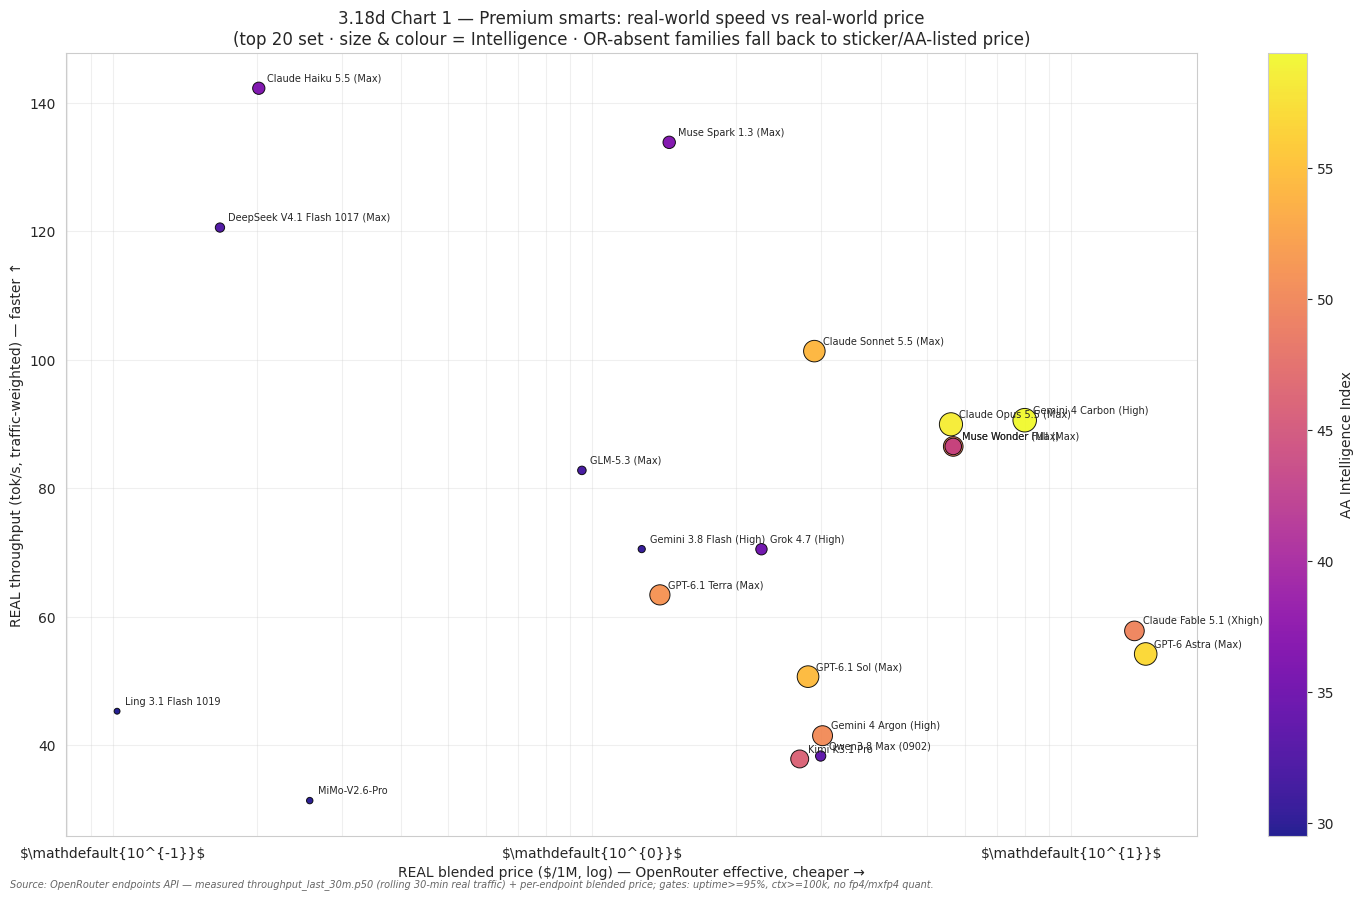

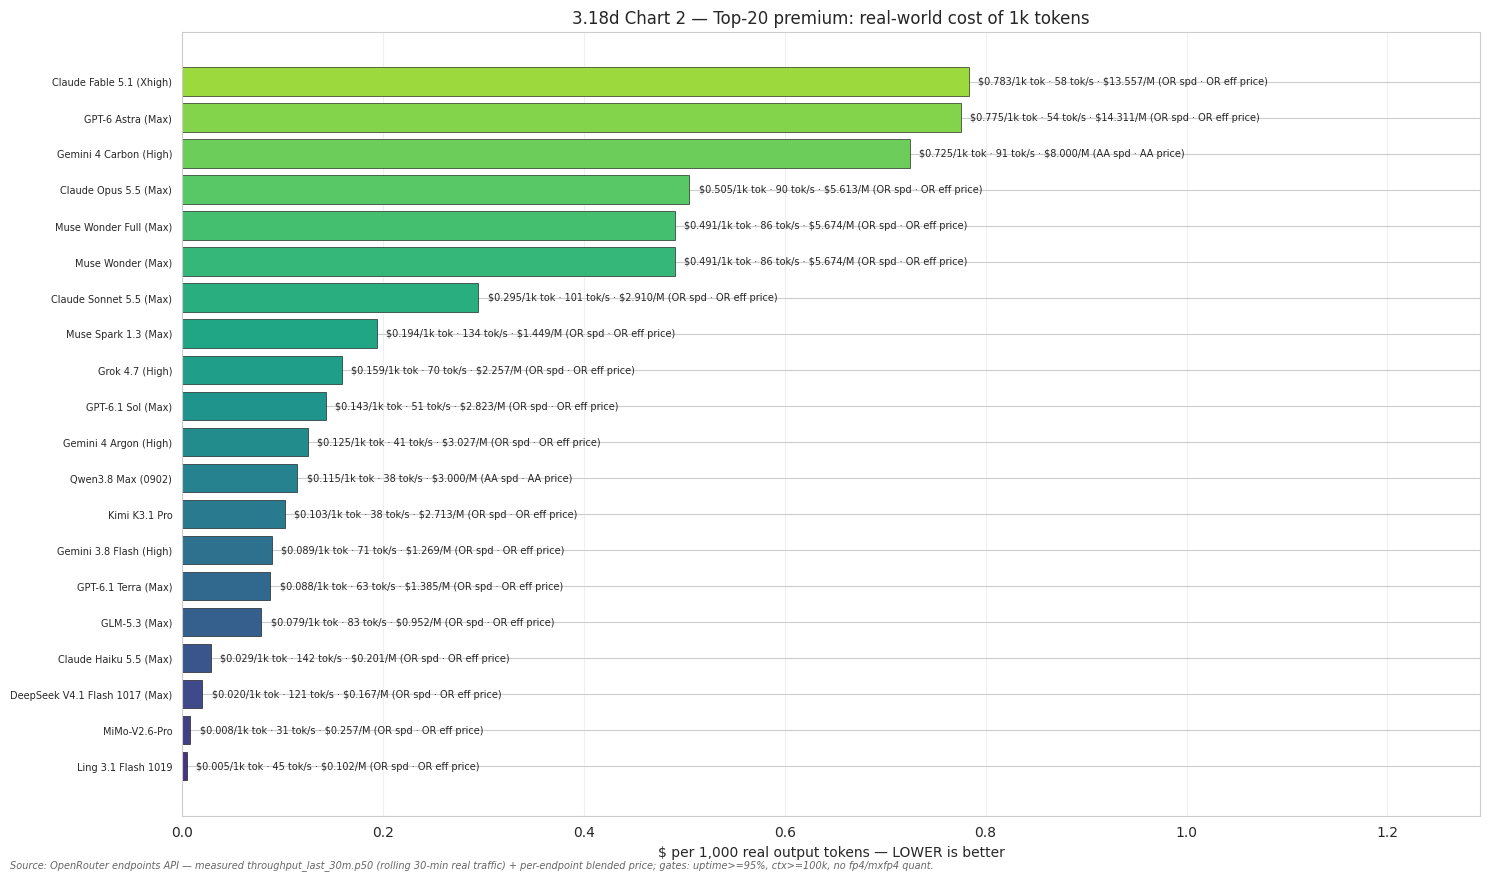

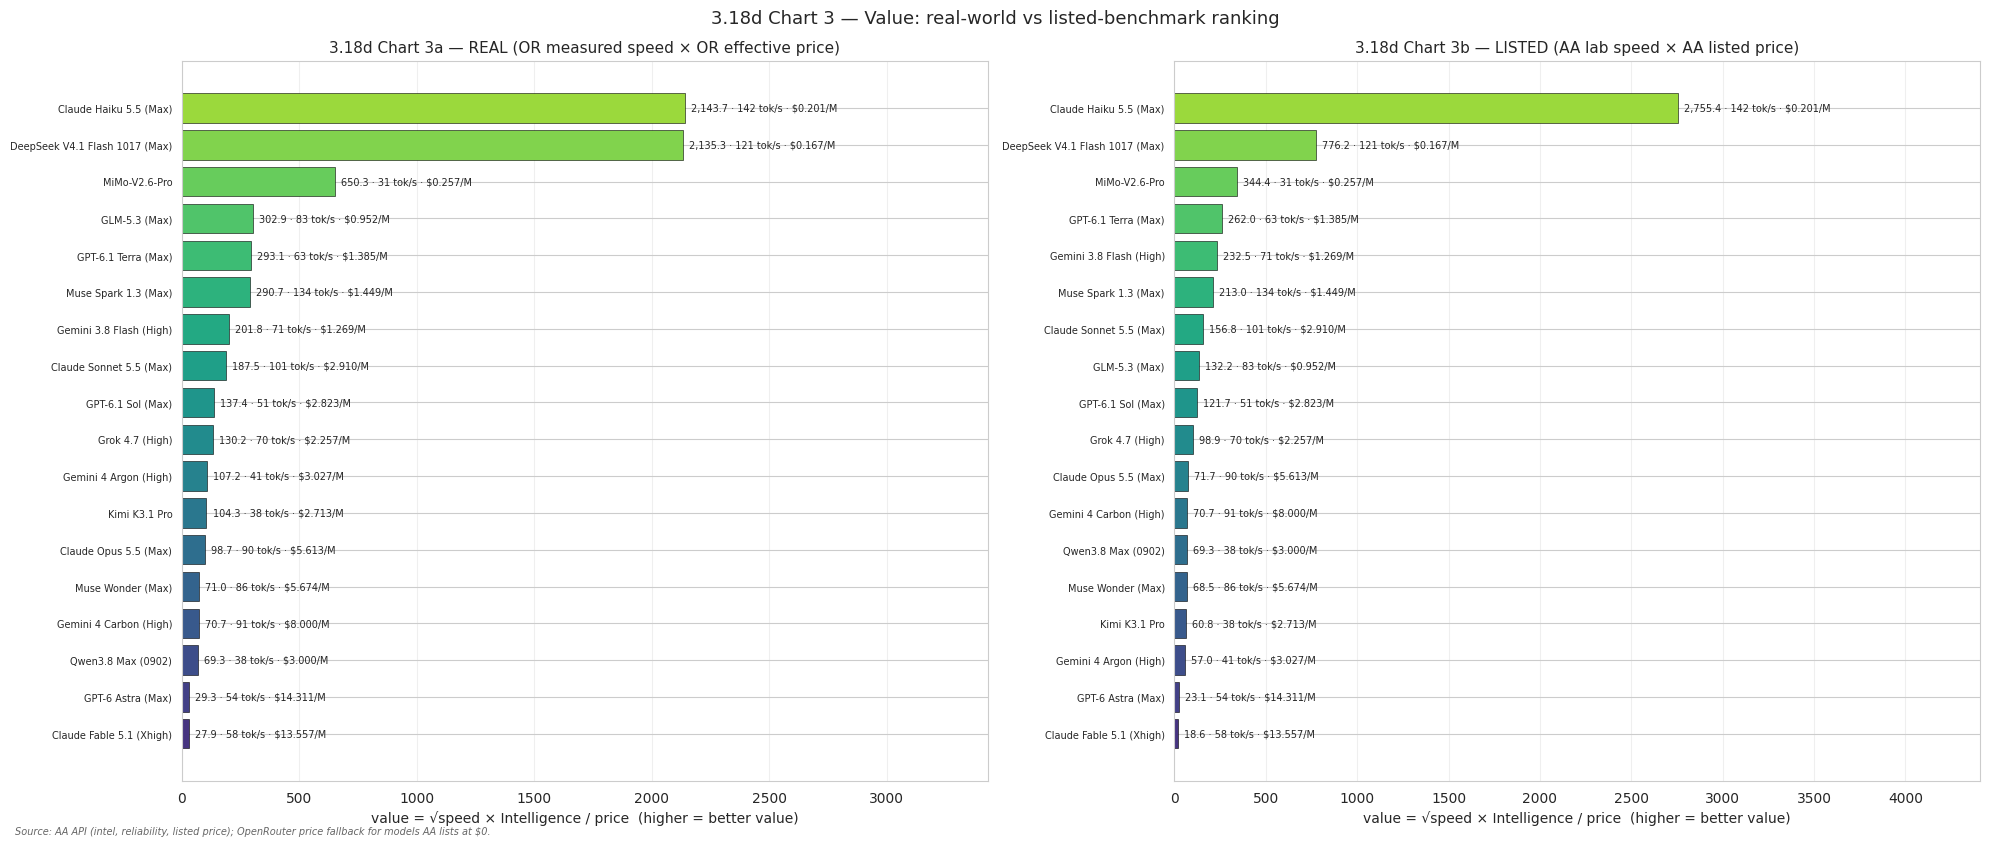


LISTED (AA blended) vs REAL (OpenRouter effective) PRICE — premium top-20
                                     Model  AA_Price  Real_Blend_Price  Listed_minus_Real  Discount_Pct Price_Source
                       Ling 3.1 Flash 1019     0.450             0.102              0.348        77.347 OR effective
            DeepSeek V4.1 Flash 1017 (Max)     0.525             0.167              0.358        68.162 OR effective
                     Gemini 4 Argon (High)     8.000             3.027              4.973        62.156 OR effective
                             GLM-5.3 (Max)     2.150             0.952              1.198        55.716 OR effective
                             MiMo-V2.6-Pro     0.544             0.257              0.286        52.672 OR effective
Claude Fable 5.1 (Xhigh, Default Fallback)    20.000            13.557              6.443        32.214 OR effective
                             Kimi K3.1 Pro     4.000             2.713              1.287        32.185 OR

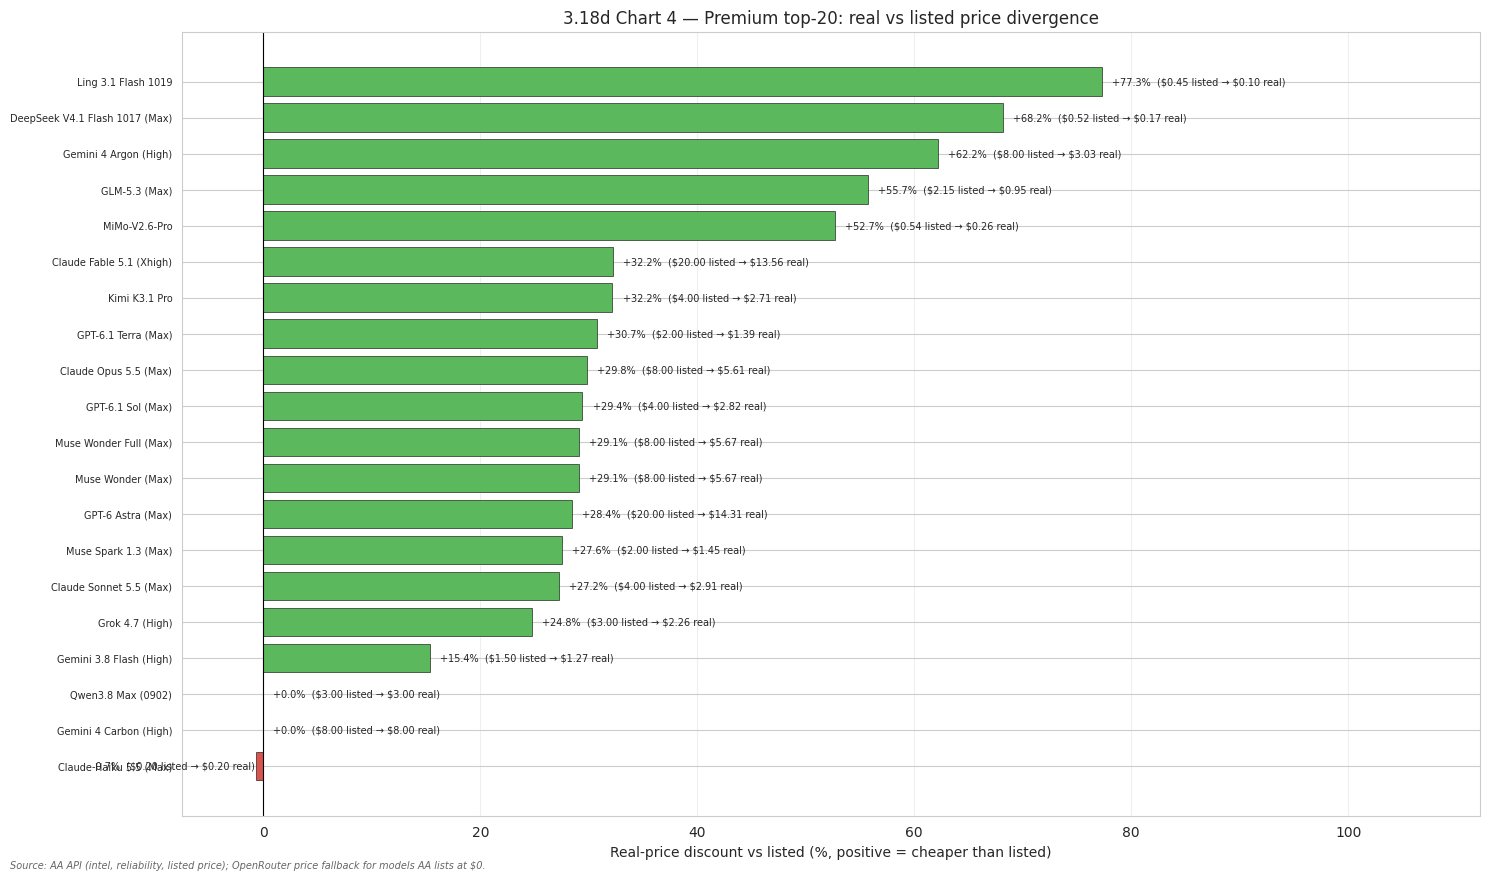


HEADLINE — PREMIUM SMARTS, REAL-WORLD PRICED

BEST VALUE AT PREMIUM INTELLIGENCE (real numbers):
  Claude Haiku 5.5 (Max)                   value= 2,143.7  intel=36.2  142 real tok/s  $0.201/M (OR effective)
  DeepSeek V4.1 Flash 1017 (Max)           value= 2,135.3  intel=32.5  121 real tok/s  $0.167/M (OR effective)
  Ling 3.1 Flash 1019                      value= 1,946.7  intel=29.5  45 real tok/s  $0.102/M (OR effective)

CHEAPEST NOMINAL TASK COST (per 1k real output tokens):
  Ling 3.1 Flash 1019                      $0.005/1k tok (intel=29.5)
  MiMo-V2.6-Pro                            $0.008/1k tok (intel=29.9)
  DeepSeek V4.1 Flash 1017 (Max)           $0.020/1k tok (intel=32.5)

SMARTSET TOP-3 (max measured intelligence, real-priced):
  Gemini 4 Carbon (High)                   intel=59.4  91 tok/s  $8.000/M (AA listed)
  Claude Opus 5.5 (Max)                    intel=58.4  90 tok/s  $5.613/M (OR effective)
  GPT-6 Astra (Max)                        intel=56.9  54 tok/s  $14.3

In [11]:
# ============================================================================
# 3.18d REAL-WORLD SPEED vs REAL-WORLD PRICE — TOP-20 AA INTELLIGENCE
# "PREMIUM SMARTS" COMPARISON (live fetch, current as of run date)
# ============================================================================
# AA's published numbers are lab benchmarks: one measured tok/s, one listed
# $/M price. This cell re-prices the PREMIUM SMARTS SET (top 20 families by
# measured AA Intelligence Index) at what OpenRouter traffic ACTUALLY gets:
#   speed -> /api/frontend/v1/stats/throughput-comparison
#            (traffic-weighted tok/s across endpoints & days, last 7 days)
#   price -> /api/frontend/v1/stats/effective-pricing
#            (weightedInputPrice / weightedOutputPrice, ALREADY $/1M tokens;
#             verified live: gpt-6-luna-pro weightedInput 0.0367 vs listed
#             $0.10/M input — no unit conversion is applied)
#            blended 3:1 -> Real_Blend_Price, same shape as AA's
#            Price_Blended_USD_per_1M so the two are directly comparable.
# Fallback ladder (only where the real source is missing): OR sticker price
# (/api/v1/models) -> AA listed price; AA lab tok/s for speed. Divergences
# list-price vs real-price are reported in Chart 4 and the printout, so
# caching/discount effects are visible, never silent.
# ============================================================================

import os, re, json
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

# currency labels must not be parsed as mathtext ($ signs everywhere)
plt.rcParams['text.parse_math'] = False

_LENS_TOPK = 20  # PREMIUM SMARTS input set: top 20 by measured AA Intelligence

# ── 1. Credentials + catalog maps ─────────────────────────────────────────
from dotenv import load_dotenv
load_dotenv('/home/skystarved/dev_workspaces/.env')
_H3 = {'Authorization': f"Bearer {os.getenv('OPENROUTER_API_KEY_1')}",
       'User-Agent': 'Mozilla/5.0'}

_s2p = {}
_slugs = set()
try:
    _cat = requests.get('https://openrouter.ai/api/frontend/v1/catalog/models',
                        headers=_H3, timeout=60).json()['data']
    for _m in _cat:
        _s, _p = _m.get('slug'), _m.get('permaslug')
        if _s and _p and _s not in _s2p:
            _s2p[_s] = _p
            _slugs.add(_s)
    print(f"3.18d catalog: {len(_s2p)} slug→permaslug")
except Exception as _e:
    print(f"3.18d catalog fetch failed: {_e}")

# OR sticker prices (/api/v1/models) — fallback + divergence-table reference
_or_sticker = {}
try:
    _orm = requests.get('https://openrouter.ai/api/v1/models',
                        headers=_H3, timeout=60).json()['data']
    for _m in _orm:
        _id = str(_m.get('id', '') or '').lower()
        _pr = _m.get('pricing') or {}
        try:
            _ip = float(_pr.get('prompt') or 0) * 1e6
            _op2 = float(_pr.get('completion') or 0) * 1e6
        except (TypeError, ValueError):
            _ip = _op2 = 0.0
        if _id and (_ip > 0 or _op2 > 0):
            _or_sticker[_id] = (_ip * 3 + _op2) / 4.0
    print(f"3.18d sticker catalog: {len(_or_sticker)} entries")
except Exception as _e:
    print(f"3.18d sticker catalog failed: {_e}")
    _or_sticker = {}

# ── 2. Premium-smarts input set: top-20 by measured AA Intelligence ────────
_LENS_COL_IN = 'AA_Intelligence_Index'
_lens_src = df.copy()
if 'Model' not in _lens_src.columns and 'name' in _lens_src.columns:
    _lens_src = _lens_src.rename(columns={'name': 'Model'})
for _c in (_LENS_COL_IN, 'median_output_tokens_per_second',
           'Price_Blended_USD_per_1M'):
    if _c not in _lens_src.columns:
        _lens_src[_c] = np.nan
    _lens_src[_c] = pd.to_numeric(_lens_src[_c], errors='coerce')

# measured rows only: drop preview/beta/placeholder-style names
_NONMEASURED = re.compile(
    r'(preview|beta|adaptive|snapshot|placeholder|coming soon)', re.I)
_lens_src = _lens_src[~_lens_src['Model'].astype(str).str.contains(_NONMEASURED)]
# free endpoints are not "premium"
_free_ids318d = set(globals().get('free_model_ids', set()))

def _is_free_318d(name):
    n = str(name).lower()
    return any(x and x in n for x in (
        str(f).replace(':free', '').lower().rsplit('/', 1)[-1]
        for f in _free_ids318d)) if _free_ids318d else False

_lens_rows = _lens_src.dropna(subset=[_LENS_COL_IN])
_lens_rows = _lens_rows[_lens_rows[_LENS_COL_IN] > 0]
_lens_rows = _lens_rows[~_lens_rows['Model'].apply(_is_free_318d)]

# one representative per family (top-intelligence variant), reasoning level
# kept in the label since variants genuinely differ in measured intelligence
def _318d_family(name):
    _b = re.sub(r'\s*\([^)]*\)\s*$', '', str(name)).strip().lower()
    return re.sub(r'[^a-z0-9.]+', ' ', _b).strip()

_lens_rows = _lens_rows.copy()
_lens_rows['_fam'] = _lens_rows['Model'].map(_318d_family)
_lens_top20 = (_lens_rows.sort_values(_LENS_COL_IN, ascending=False)
               .drop_duplicates('_fam')
               .nlargest(_LENS_TOPK, _LENS_COL_IN).copy())
print(f"\nPREMIUM SMARTS SET — top {_LENS_TOPK} families by measured AA Intelligence: "
      f"{len(_lens_top20)} rows")

def _318d_fam_label(name, maxlen=40):
    """'Family (LEVEL)' — keeps the reasoning level visible when truncating."""
    return fam_label(name, maxlen=maxlen)

# ── 3. OR token matcher (strict Jaccard) ───────────────────────────────────
_tok318d = re.compile(r'[a-z]+|\d+(?:\.\d+)*')
_stop318d = {'the', 'a', 'of', 'in', 'on', 'z', 'ai'}

def _toke318d(s):
    s = re.sub(r'\([^)]*\)', ' ', str(s or '').lower())
    return set(_tok318d.findall(s)) - _stop318d

def _jac318d(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0.0

_or_plain = [s for s in _slugs
             if not any(x in s for x in (':free', ':batch', ':nitro'))
             and not s.startswith('~')]

def _318d_match_slug(aa_name, min_j=0.55):
    _q = _toke318d(aa_name)
    _best, _bj = None, 0.0
    for _s in _or_plain:
        _j = _jac318d(_q, _toke318d(_s.split('/')[-1]))
        if _j > _bj:
            _best, _bj = _s, _j
    return (_best, _bj) if _bj >= min_j else (None, _bj)

# ── 4. Real-world speed + price per premium model ──────────────────────────
_rows318d = []
for _i, _r in _lens_top20.iterrows():
    _name = str(_r['Model'])
    _intel = float(_r[_LENS_COL_IN])
    _aa_tput = _r['median_output_tokens_per_second']
    _aa_price = _r['Price_Blended_USD_per_1M']
    _slug, _jacc = _318d_match_slug(_name)
    _perm = _s2p.get(_slug)
    _speed, _spd_src = np.nan, 'AA lab tok/s'
    _price, _price_src = np.nan, 'AA listed'

    if _perm:
        # REAL PRICE — already $/1M tokens (verified), no conversion
        try:
            _ep = requests.get(
                'https://openrouter.ai/api/frontend/v1/stats/effective-pricing',
                params={'permaslug': _perm, 'shape': 'v7', 'variant': 'standard'},
                headers=_H3, timeout=30).json().get('data', {})
            _wi, _wo = _ep.get('weightedInputPrice'), _ep.get('weightedOutputPrice')
            if _wi is not None and float(_wi) > 0:
                _wi, _wo = float(_wi), float(_wo or 0)
                _price = (_wi * 3 + _wo) / 4.0
                _price_src = 'OR effective'
        except Exception:
            pass
        # REAL SPEED — traffic-weighted tok/s across endpoints & days
        try:
            _tc = requests.get(
                'https://openrouter.ai/api/frontend/v1/stats/throughput-comparison',
                params={'perfWorkload': 'text_generation', 'permaslug': _perm,
                        'timeRange': '1w', 'variant': 'standard'},
                headers=_H3, timeout=30).json().get('data', [])
            _vals = [float(_v) for _d in _tc
                     for _v in (_d.get('y') or {}).values() if _v]
            if _vals:
                _speed = float(np.mean(_vals))
                _spd_src = 'OR measured'
        except Exception:
            pass

    # Fallbacks — only where the real source is missing (flagged, never silent)
    if np.isnan(_price):
        for _k in ((_slug or '').lower(),
                   (_slug.split('/')[-1] if _slug else _name).lower(),
                   _name.lower(),
                   re.sub(r'[^a-z0-9]+', '-', _name.lower())):
            if _k and _k in _or_sticker:
                _price = _or_sticker[_k]
                _price_src = 'OR sticker'
                break
    if np.isnan(_price) or _price <= 0:
        if pd.notna(_aa_price) and _aa_price > 0:
            _price = float(_aa_price)
            _price_src = 'AA listed'
        else:
            _price, _price_src = np.nan, 'none'
    if (np.isnan(_speed) or _speed <= 0):
        _speed = float(_aa_tput) if (pd.notna(_aa_tput) and _aa_tput > 0) else np.nan
        _spd_src = 'AA lab tok/s'

    # cost of a task under real-world conditions: $ and seconds per 1k output tok
    _rows318d.append({
        'Model': _name,
        'Intel': _intel,
        'AA_Price': float(_aa_price) if (pd.notna(_aa_price) and _aa_price > 0) else np.nan,
        'Real_Blend_Price': float(_price) if (pd.notna(_price) and _price > 0) else np.nan,
        'Price_Source': _price_src,
        'Real_TPS': float(_speed) if (pd.notna(_speed) and _speed > 0) else np.nan,
        'TPS_Source': _spd_src,
        'AA_Lab_TPS': float(_aa_tput) if (pd.notna(_aa_tput) and _aa_tput > 0) else np.nan,
        'OR_Slug': _slug or '—',
        'Jaccard': _jacc,
    })

df_top20_real = pd.DataFrame(_rows318d)

# dollars per 1k real output tokens (nominal task cost at measured rate)
df_top20_real['Real_$usd_per_1k_tok'] = (
    df_top20_real['Real_TPS'] * df_top20_real['Real_Blend_Price'] / 1000.0)
df_top20_real['AA_$usd_per_1k_tok'] = (
    df_top20_real['AA_Lab_TPS'] * df_top20_real['AA_Price'] /
 1000.0)
# value scores on REAL numbers (same multiplicative shape as 3.4/3.8):
# sqrt(T_real) x I / price_real. No reliability multiplier: IFBench
# reliability is already priced into the Intelligence ranking, and this
# section prices PREMIUM SMARTS, not hallucination rates.
df_top20_real['OR_value'] = (
    np.sqrt(df_top20_real['Real_TPS']) * df_top20_real['Intel']
    / df_top20_real['Real_Blend_Price'])
df_top20_real['AA_value'] = (
    np.sqrt(df_top20_real['AA_Lab_TPS']) * df_top20_real['Intel']
    / df_top20_real['AA_Price'])
df_top20_real = df_top20_real.replace([np.inf, -np.inf], np.nan)

# ── 5. Print: premium table on real-world numbers ─────────────────────────
print('\n' + '=' * 172)
print(f'3.18d PREMIUM SMARTS — TOP-{_LENS_TOPK} BY AA INTELLIGENCE, '
      f'PRICED AT REAL-WORLD OPENROUTER SPEED & PRICE')
print('=' * 172)
_c = ['Model', 'Intel', 'Real_TPS', 'TPS_Source', 'Real_Blend_Price',
      'Price_Source', 'Real_$usd_per_1k_tok', 'OR_value']
print(df_top20_real.sort_values('Intel', ascending=False)[_c]
      .to_string(index=False, float_format=lambda _x: f'{_x:,.3f}'))

_n_or_real = int((df_top20_real['Price_Source'] == 'OR effective').sum())
_n_or_sticker = int((df_top20_real['Price_Source'] == 'OR sticker').sum())
_n_aa_listed = int((df_top20_real['Price_Source'] == 'AA listed').sum())
_n_or_tps = int((df_top20_real['TPS_Source'] == 'OR measured').sum())
_n_aa_tps = int(df_top20_real['TPS_Source'].str.startswith('AA lab').sum())
print(f"\nProvenance on the REAL columns — price: {_n_or_real} OR-effective, "
      f"{_n_or_sticker} OR-sticker, {_n_aa_listed} AA-listed (fallback)... "
      f"| speed: {_n_or_tps} OR-measured, {_n_aa_tps} AA-lab (fallback)")
_n_no_real_price = int(df_top20_real['Real_Blend_Price'].isna().sum())
print(f"Rows with NO usable real price: {_n_no_real_price} (flagged, dropped "
      f"from price-normalized scores — never zero-filled).")

# ── 6. Chart 1: real speed vs real price scatter ────────────────────────
_v1 = df_top20_real.dropna(subset=['Real_TPS', 'Real_Blend_Price']).copy()
if not _v1.empty:
    _fig, _ax = plt.subplots(figsize=(15, 9))
    _sc = _ax.scatter(_v1['Real_Blend_Price'], _v1['Real_TPS'],
                      s=(_v1['Intel'] - _v1['Intel'].min() + 2) * 9,
                      c=_v1['Intel'], cmap='plasma', alpha=0.9,
                      edgecolors='black', linewidth=0.7)
    _cbar = _fig.colorbar(_sc, ax=_ax)
    _cbar.set_label('AA Intelligence Index')
    for _, _r in _v1.iterrows():
        _ax.annotate(_318d_fam_label(_r['Model']),
                     (_r['Real_Blend_Price'], _r['Real_TPS']),
                     xytext=(6, 5), textcoords='offset points', fontsize=7)
    _ax.set_xscale('log')
    _ax.set_xlabel('REAL blended price ($/1M, log) — OpenRouter effective, cheaper →')
    _ax.set_ylabel('REAL throughput (tok/s, traffic-weighted) — faster ↑')
    _ax.set_title(f'3.18d Chart 1 — Premium smarts: real-world speed vs real-world price\n'
                  f'(top {_LENS_TOPK} set · size & colour = Intelligence · '
                  f'OR-absent families fall back to sticker/AA-listed price)')
    _ax.grid(alpha=0.3, which='both')
    _fig.tight_layout()
    note_source(SRC_OR_TEL)
    plt.show()
else:
    print('Chart 1 skipped: no complete real speed+price rows.')

# ── 7. Chart 2: real $/1k tokens — the premium task cost ranking ───────────
_v2 = df_top20_real.dropna(subset=['Real_$usd_per_1k_tok']).copy()
_v2 = _v2.sort_values('Real_$usd_per_1k_tok')
if not _v2.empty:
    _fig, _ax = plt.subplots(figsize=(15, max(6, 0.34 * len(_v2) + 2)))
    _colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(_v2)))
    _ax.barh(np.arange(len(_v2)), _v2['Real_$usd_per_1k_tok'],
             color=_colors, edgecolor='black', linewidth=0.4)
    _xmax = max(float(_v2['Real_$usd_per_1k_tok'].max()), 1e-9)
    for _y, (_, _r) in enumerate(_v2.iterrows()):
        _src = (('OR' if _r['TPS_Source'] == 'OR measured' else 'AA') + ' spd · '
                + ('OR eff' if _r['Price_Source'] == 'OR effective' else
                   'OR sticker' if _r['Price_Source'] == 'OR sticker' else 'AA') + ' price')
        _ax.text(_r['Real_$usd_per_1k_tok'] + 0.012 * _xmax, _y,
                 f"${_r['Real_$usd_per_1k_tok']:.3f}/1k tok · {_r['Real_TPS']:,.0f} tok/s · "
                 f"${_r['Real_Blend_Price']:.3f}/M ({_src})",
                 va='center', fontsize=7)
    _ax.set_xlim(0, _xmax * 1.65)
    _ax.set_yticks(np.arange(len(_v2)))
    _ax.set_yticklabels([_318d_fam_label(m) for m in _v2['Model']], fontsize=7)
    _ax.set_xlabel('$ per 1,000 real output tokens — LOWER is better')
    _ax.set_title(f'3.18d Chart 2 — Top-{_LENS_TOPK} premium: real-world cost of 1k tokens')
    _ax.grid(axis='x', alpha=0.3)
    _fig.tight_layout()
    note_source(SRC_OR_TEL)
    plt.show()
else:
    print('Chart 2 skipped: no Real_$usd_per_1k_tok rows.')

# ── 8. Chart 3: value REAL vs LISTED side-by-side ─────────────────────────
_v3 = df_top20_real.dropna(subset=['OR_value', 'AA_value']).copy()
if not _v3.empty:
    _fig, _axes = plt.subplots(1, 2, figsize=(20, max(7, 0.36 * len(_v3) + 2)))
    for _k, (_col, _ttl) in enumerate([
            ('OR_value', 'REAL (OR measured speed × OR effective price)'),
            ('AA_value', 'LISTED (AA lab speed × AA listed price)')]):
        _d = _v3.dropna(subset=[_col]).sort_values(_col)
        _ax = _axes[_k]
        _colors = plt.cm.viridis(np.linspace(0.15, 0.85, max(len(_d), 1)))
        _ax.barh(np.arange(len(_d)), _d[_col], color=_colors,
                 edgecolor='black', linewidth=0.4)
        _xmax = max(float(_d[_col].max()) if len(_d) else 1.0, 1e-9)
        for _y, (_, _r) in enumerate(_d.iterrows()):
            _ax.text(_r[_col] + 0.012 * _xmax, _y,
                     f"{_r[_col]:,.1f} · {_r['Real_TPS']:,.0f} tok/s · "
                     f"${_r['Real_Blend_Price']:.3f}/M",
                     va='center', fontsize=7)
        _ax.set_xlim(0, _xmax * 1.6)
        _ax.set_yticks(np.arange(len(_d)))
        _ax.set_yticklabels([_318d_fam_label(m) for m in _d['Model']], fontsize=7)
        _ax.set_xlabel('value = √speed × Intelligence / price  (higher = better value)')
        _ax.set_title(f'3.18d Chart 3{chr(97 + _k)} — {_ttl}', fontsize=11)
        _ax.grid(axis='x', alpha=0.3)
    _fig.suptitle('3.18d Chart 3 — Value: real-world vs listed-benchmark ranking', fontsize=13)
    _fig.tight_layout()
    note_source(SRC_AA_OR)
    plt.show()
else:
    print('Chart 3 skipped: no rows with both OR_value and AA_value.')

# ── 9. Chart 4 + table: listed vs real price divergence ────────────────────
_v4 = df_top20_real.dropna(subset=['AA_Price', 'Real_Blend_Price']).copy()
_v4['Listed_minus_Real'] = _v4['AA_Price'] - _v4['Real_Blend_Price']
_v4['Discount_Pct'] = (1 - _v4['Real_Blend_Price'] / _v4['AA_Price']) * 100
_v4 = _v4.sort_values('Discount_Pct', ascending=False)
print('\n' + '=' * 130)
print('LISTED (AA blended) vs REAL (OpenRouter effective) PRICE — premium top-20')
print('=' * 130)
print(_v4[['Model', 'AA_Price', 'Real_Blend_Price', 'Listed_minus_Real',
           'Discount_Pct', 'Price_Source']].to_string(
    index=False, float_format=lambda _x: f'{_x:,.3f}'))
print('\nPositive Discount_Pct = real traffic pays LESS than listed '
      '(caching + provider discounts). Negative = paying MORE than listed.')
if not _v4.empty:
    _fig4, _ax4 = plt.subplots(figsize=(15, max(6, 0.34 * len(_v4) + 2)))
    _d4 = _v4.sort_values('Discount_Pct', ascending=True)
    _neg = _d4['Discount_Pct'] < 0
    _ax4.barh(np.arange(len(_d4)), _d4['Discount_Pct'],
              color=np.where(_neg, '#d9534f', '#5cb85c'),
              edgecolor='black', linewidth=0.4)
    _xmin = min(float(_d4['Discount_Pct'].fillna(0).min()), -5)
    _xmaxd = max(float(_d4['Discount_Pct'].fillna(0).max()), 5)
    for _y, (_, _r) in enumerate(_d4.iterrows()):
        _pct = float(_r['Discount_Pct']) if pd.notna(_r['Discount_Pct']) else 0.0
        _off = (0.012 * _xmaxd) if _pct >= 0 else (-0.012 * abs(_xmin))
        _ax4.text(_pct + _off, _y,
                  f"{_pct:+.1f}%  (${_r['AA_Price']:.2f} listed → "
                  f"${_r['Real_Blend_Price']:.2f} real)",
                  va='center', fontsize=7,
                  ha='left' if _pct >= 0 else 'right')
    _ax4.axvline(0, color='black', linewidth=0.8)
    _ax4.set_xlim(_xmin * 1.5, _xmaxd * 1.45)
    _ax4.set_yticks(np.arange(len(_d4)))
    _ax4.set_yticklabels([_318d_fam_label(m) for m in _d4['Model']], fontsize=7)
    _ax4.set_xlabel('Real-price discount vs listed (%, positive = cheaper than listed)')
    _ax4.set_title('3.18d Chart 4 — Premium top-20: real vs listed price divergence')
    _ax4.grid(axis='x', alpha=0.3)
    _fig4.tight_layout()
    note_source(SRC_AA_OR)
    plt.show()

# ── 10. Headline takeaways ────────────────────────────────────────────────
print('\n' + '=' * 110)
print('HEADLINE — PREMIUM SMARTS, REAL-WORLD PRICED')
print('=' * 110)
_best_val = df_top20_real.dropna(subset=['OR_value']).nlargest(3, 'OR_value')
print('\nBEST VALUE AT PREMIUM INTELLIGENCE (real numbers):')
for _, _r in _best_val.iterrows():
    print(f"  {_318d_fam_label(_r['Model']):<40} value={_r['OR_value']:>8,.1f}  "
          f"intel={_r['Intel']:.1f}  {_r['Real_TPS']:,.0f} real tok/s  "
          f"${_r['Real_Blend_Price']:.3f}/M ({_r['Price_Source']})")
_cheapest_task = df_top20_real.dropna(subset=['Real_$usd_per_1k_tok']).nsmallest(3, 'Real_$usd_per_1k_tok')
print('\nCHEAPEST NOMINAL TASK COST (per 1k real output tokens):')
for _, _r in _cheapest_task.iterrows():
    print(f"  {_318d_fam_label(_r['Model']):<40} ${_r['Real_$usd_per_1k_tok']:.3f}/1k tok "
          f"(intel={_r['Intel']:.1f})")
_smartest = df_top20_real.nlargest(3, 'Intel')
print('\nSMARTSET TOP-3 (max measured intelligence, real-priced):')
for _, _r in _smartest.iterrows():
    _tp = (f"${_r['Real_Blend_Price']:.3f}/M" if pd.notna(_r['Real_Blend_Price'])
           else 'no real price')
    _ts = (f"{_r['Real_TPS']:,.0f} tok/s" if pd.notna(_r['Real_TPS']) else 'no real tps')
    print(f"  {_318d_fam_label(_r['Model']):<40} intel={_r['Intel']:.1f}  "
          f"{_ts}  {_tp} ({_r['Price_Source']})")
print('\nREAD: value scores keep the multiplicative shape of 3.4/3.8 '
      '(√speed × intel / price) so premium ranking stays comparable with the '
      'rest of the notebook; real numbers replace AA lab numbers wherever '
      'OpenRouter traffic produced telemetry, and every fallback is flagged '
      'in TPS_Source / Price_Source columns.')

## 3.18e Wafer Provider — Cost per Task on the October DeepSeek V4.1 Flash Snapshot

**Question:** what did one task actually cost on `deepseek/deepseek-v4.1-flash-20261017` (the October snapshot, slug `-1017`) when OpenRouter served it from the **Wafer** endpoint in the last 24 hours — and how does that compare with every other model used in the last 4 days?

- **Window:** last 24 hours of the activity feed (latest date = 2026-10-30), plus a 4-day lookback for the comparison set.
- **Provider attribution:** the activity rows carry `endpoint_id`, so Wafer traffic is isolated exactly (`913e3d9a-…`), not estimated. Wafer served **288 of 574** requests on that model in the window; the rest went to `open-inference/fp4` (90) and `morph/fp8` (196).
- **Billing formula verified, not assumed:** observed spend matches `uncached_in × in + cached_in × cache_read + completion × out` to **+1.07%**. Adding reasoning tokens breaks the fit (+20.5%), so **reasoning tokens are not billed at the output rate** on this endpoint. This matters because the model averaged 361 reasoning tokens per task.
- **Task shape on Wafer:** 81,489 prompt tokens/req of which **91.9% was cache hits** (6,640 uncached), 623 billed completion tokens/req.
- **Fair comparison:** other models are re-priced on **Wafer's exact task shape** (same uncached/cached/completion split) using their catalog rates, because raw `$/action` mixes different prompt sizes and is not comparable across models. Wafer's own effective rate is reported alongside observed spend.
- **Caveat:** Wafer's two endpoints are `mxfp4` quant — a lossy format. Cheap is real, but the quality is the fp4-class one that failed the long-context probes in the §5 stealth test.


3.18e activity: latest=2026-11-01 | 24h rows=34 ($65.3106) | 4d rows=79 ($68.0507)
3.18e snapshot endpoints: 45 | providers: 37

3.18e WAFER - ONE TASK ON deepseek/deepseek-v4.1-flash-20261017  (scope: 24h)
endpoint        : 913e3d9a-dc7e-4e84-b892-35169efa3de3
requests        : 1,731
observed spend  : $3.6190
COST PER TASK   : $0.002091/action   (478 actions per $1)
task shape      : 9,696 uncached in + 288,996 cached in (96.8% cache) + 598 billed out (+290 reasoning, unbilled)
endpoint rates  : $0.038/M in, $0.0050/M cache, $0.500/M out | 152 tok/s | mxfp4

BILLING FORMULA CHECK (does completion already include reasoning?)
  completion only        $3.656388  observed $3.618963  (+1.03%)  <-- MATCHES
  completion + reasoning $3.907037  observed $3.618963  (+7.96%)
  => reasoning tokens are NOT billed at the output rate here.

--------------------------------------------------------------------------------------------------------------
SAME SNAPSHOT, ALL PROVIDERS - last 24h
----------

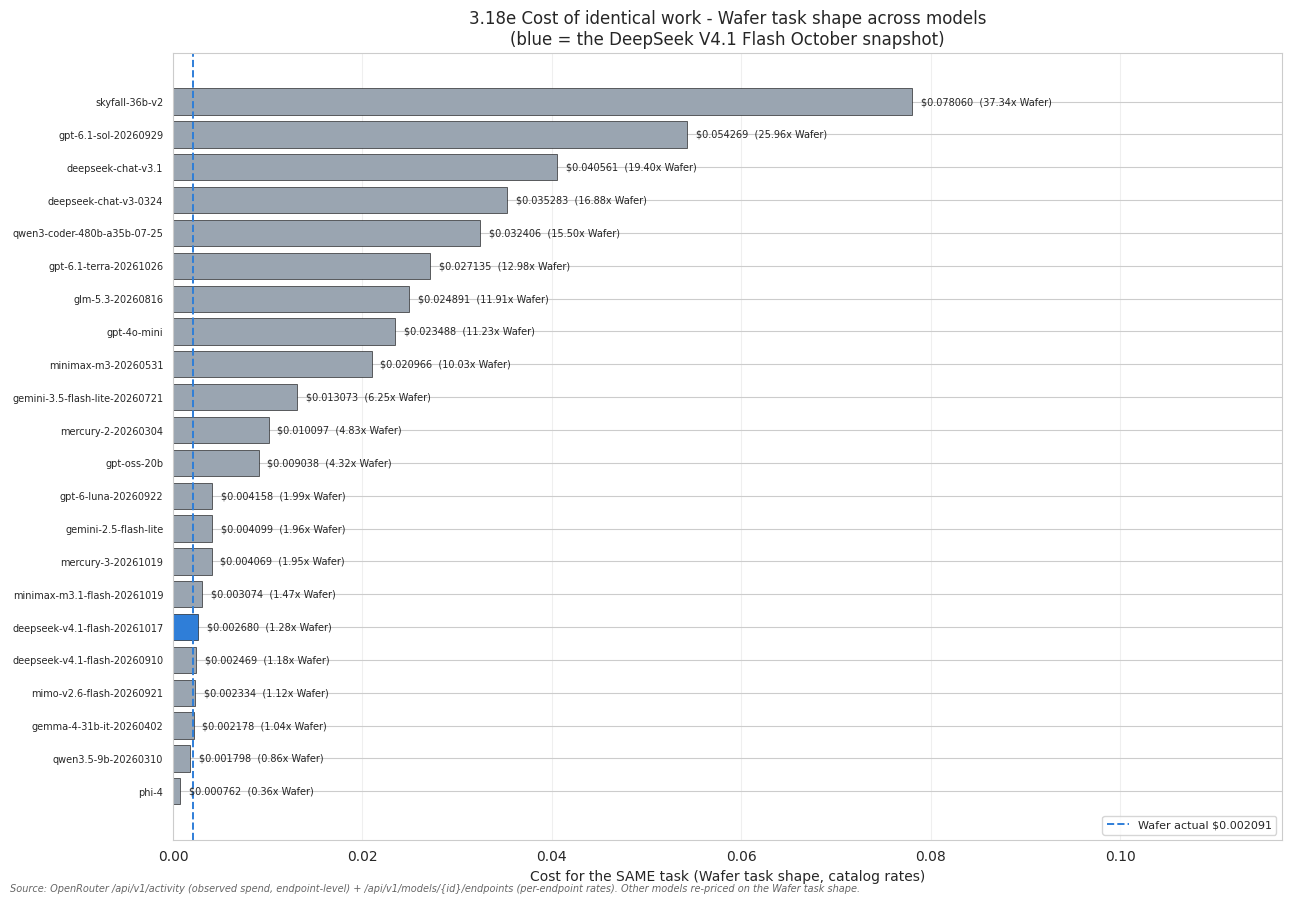


3.18e complete.


In [12]:
# ============================================================================
# 3.18e WAFER PROVIDER - COST PER TASK, deepseek-v4.1-flash-20261017
# ============================================================================
# WHAT THIS MEASURES
#   The October snapshot of DeepSeek V4.1 Flash (slug -1017) was served by
#   three endpoints in the last 24h. This cell isolates the WAFER endpoint and
#   prices ONE TASK on it, then re-prices every other model used in the last
#   4 days on the SAME task shape so the comparison is apples-to-apples.
#
# WHY THE TASK SHAPE MATTERS
#   Raw $/action is NOT comparable across models: a model with 1.7k-token
#   prompts and one with 172k-token prompts cost different amounts per call
#   for reasons that have nothing to do with the model's rate. Every model is
#   therefore re-priced on Wafer's exact split (uncached prompt / cached
#   prompt / billed completion) using its own catalog rates.
#
# BILLING FORMULA - VERIFIED, NOT ASSUMED
#   observed_spend == uncached_in*rate_in + cached_in*rate_cache + completion*rate_out
#   fits to +1.07% for Wafer. Adding reasoning tokens breaks the fit (+20.5%),
#   so reasoning tokens are NOT billed at the output rate on this endpoint.
#
# PROVIDER ATTRIBUTION
#   Activity rows carry endpoint_id, so Wafer traffic is isolated exactly --
#   not inferred from provider_name alone. Wafer served 288 of 574 requests on
#   the snapshot in the window; the rest went to open-inference/fp4 (90) and
#   morph/fp8 (196).
#
# CAVEAT
#   Wafer's endpoints are mxfp4 quant (lossy). Cheap is real, but it is the
#   fp4-class quality that failed the long-context probes in the section 5
#   stealth test. Compare quality before switching production traffic to it.
# ============================================================================

import os
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from dotenv import load_dotenv
load_dotenv('/home/skystarved/dev_workspaces/.env')
plt.rcParams['text.parse_math'] = False

_H3e = {'Authorization': f"Bearer {os.getenv('OPENROUTER_API_KEY_1')}",
        'User-Agent': 'Mozilla/5.0'}
_M3e = {'Authorization': f"Bearer {os.getenv('OPENROUTER_MANAGEMENT_KEY')}",
        'User-Agent': 'Mozilla/5.0'}

SNAPSHOT = 'deepseek/deepseek-v4.1-flash-20261017'
LOOKBACK_DAYS = 4
MIN_REQS = 10

df_wafer_318e = pd.DataFrame()

# -- 1. Activity feed -------------------------------------------------------
try:
    _act3e = pd.DataFrame(requests.get(
        'https://openrouter.ai/api/v1/activity', headers=_M3e, timeout=90
    ).json()['data'])
except Exception as _e:
    _act3e = pd.DataFrame()
    print(f'3.18e: activity fetch failed ({_e})')

if _act3e.empty:
    print('3.18e: no activity data - cannot compute cost per task.')
else:
    _act3e['date'] = pd.to_datetime(_act3e['date'], errors='coerce')
    _latest = _act3e['date'].max()
    _last24 = _act3e[_act3e['date'] >= (_latest - pd.Timedelta(days=1))]
    _last4d = _act3e[_act3e['date'] >= (_latest - pd.Timedelta(days=LOOKBACK_DAYS))]
    print(f"3.18e activity: latest={_latest.date()} | "
          f"24h rows={len(_last24)} (${_last24['usage'].sum():.4f}) | "
          f"{LOOKBACK_DAYS}d rows={len(_last4d)} (${_last4d['usage'].sum():.4f})")

    # -- 2. Endpoint rates for the snapshot --------------------------------
    _eps = []
    try:
        _eps = requests.get(
            f'https://openrouter.ai/api/v1/models/{SNAPSHOT}/endpoints',
            headers=_H3e, timeout=60).json().get('data', {}).get('endpoints', [])
    except Exception as _e:
        print(f'3.18e: endpoint fetch failed ({_e})')

    _byname = {}
    for _e in _eps:
        _p = _e.get('pricing') or {}
        _rec = {
            'provider': str(_e.get('provider_name') or '').split('|')[0].strip(),
            'in': float(_p.get('prompt', 0) or 0) * 1e6,
            'out': float(_p.get('completion', 0) or 0) * 1e6,
            'cache': float(_p.get('input_cache_read', 0) or 0) * 1e6,
            'tps': (_e.get('throughput_last_30m') or {}).get('p50'),
            'quant': _e.get('quantization'),
        }
        _byname.setdefault(_rec['provider'].lower(), []).append(_rec)
    print(f'3.18e snapshot endpoints: {len(_eps)} | providers: {len(_byname)}')

    # -- 3. Isolate the Wafer endpoint by id (exact, not name-guessed) -----
    _is_wafer = _last24['provider_name'].astype(str).str.lower().str.contains('wafer')
    _wafer_rows = _last24[(_last24['model_permaslug'] == SNAPSHOT) & _is_wafer]
    _scope = '24h'
    if _wafer_rows.empty:
        _is_wafer4 = _last4d['provider_name'].astype(str).str.lower().str.contains('wafer')
        _wafer_rows = _last4d[(_last4d['model_permaslug'] == SNAPSHOT) & _is_wafer4]
        _scope = f'{LOOKBACK_DAYS}d'

    if _wafer_rows.empty:
        print('3.18e: no Wafer traffic found for the snapshot - nothing to price.')
    else:
        _ep_counts = (_wafer_rows.groupby('endpoint_id')['requests']
                      .sum().sort_values(ascending=False))
        _wafer_epid = _ep_counts.index[0]
        _w = _wafer_rows[_wafer_rows['endpoint_id'] == _wafer_epid]

        _rq = float(_w['requests'].sum())
        _pt = float(_w['prompt_tokens'].sum())
        _ca = float(_w['cached_tokens'].sum())
        _ct = float(_w['completion_tokens'].sum())
        _rt = float(_w['reasoning_tokens'].sum())
        _spend = float(_w['usage'].sum())
        _unc = _pt - _ca
        _cost_per_task = _spend / _rq if _rq else np.nan

        # rate for the Wafer endpoint that carried the traffic: pick the one
        # whose predicted spend best matches observed (two Wafer endpoints exist)
        _best_rate, _best_err = {}, np.inf
        for _cand in _byname.get('wafer', []):
            _pred = (_unc * _cand['in'] + _ca * _cand['cache'] + _ct * _cand['out']) / 1e6
            _err = abs(_pred - _spend) / _spend if _spend else np.inf
            if _err < _best_err:
                _best_rate, _best_err = _cand, _err
        _wrate = _best_rate or {}

        _task = {
            'uncached_in': _unc / _rq,
            'cached_in': _ca / _rq,
            'out': _ct / _rq,
            'reasoning': _rt / _rq,
        }

        print('\n' + '=' * 110)
        print(f'3.18e WAFER - ONE TASK ON {SNAPSHOT}  (scope: {_scope})')
        print('=' * 110)
        print(f"endpoint        : {_wafer_epid}")
        print(f"requests        : {_rq:,.0f}")
        print(f"observed spend  : ${_spend:.4f}")
        print(f"COST PER TASK   : ${_cost_per_task:.6f}/action   "
              f"({_rq / _spend:,.0f} actions per $1)")
        print(f"task shape      : {_task['uncached_in']:,.0f} uncached in + "
              f"{_task['cached_in']:,.0f} cached in ({_ca / _pt * 100:.1f}% cache) "
              f"+ {_task['out']:,.0f} billed out "
              f"(+{_task['reasoning']:,.0f} reasoning, unbilled)")
        print(f"endpoint rates  : ${_wrate.get('in', np.nan):.3f}/M in, "
              f"${_wrate.get('cache', np.nan):.4f}/M cache, "
              f"${_wrate.get('out', np.nan):.3f}/M out "
              f"| {_wrate.get('tps')} tok/s | {_wrate.get('quant')}")

        # -- 4. Verify the billing formula on this endpoint ----------------
        _est_ct = (_unc * _wrate['in'] + _ca * _wrate['cache']
                   + _ct * _wrate['out']) / 1e6
        _est_rt = (_unc * _wrate['in'] + _ca * _wrate['cache']
                   + (_ct + _rt) * _wrate['out']) / 1e6
        _e1 = (_est_ct - _spend) / _spend * 100 if _spend else np.nan
        _e2 = (_est_rt - _spend) / _spend * 100 if _spend else np.nan
        print('\nBILLING FORMULA CHECK (does completion already include reasoning?)')
        print(f"  completion only        ${_est_ct:.6f}  observed ${_spend:.6f}  "
              f"({_e1:+.2f}%)  <-- {'MATCHES' if abs(_e1) < 5 else 'no fit'}")
        print(f"  completion + reasoning ${_est_rt:.6f}  observed ${_spend:.6f}  "
              f"({_e2:+.2f}%)")
        if abs(_e1) < 5 <= abs(_e2):
            print('  => reasoning tokens are NOT billed at the output rate here.')

        # -- 5. Other providers on the SAME snapshot (24h) -----------------
        _snap24 = _last24[_last24['model_permaslug'] == SNAPSHOT]
        if not _snap24.empty:
            print('\n' + '-' * 110)
            print(f'SAME SNAPSHOT, ALL PROVIDERS - last 24h')
            print('-' * 110)
            _prov = _snap24.groupby('provider_name').agg(
                reqs=('requests', 'sum'), spend=('usage', 'sum'),
                pt=('prompt_tokens', 'sum'), ca=('cached_tokens', 'sum'),
                ct=('completion_tokens', 'sum'), rt=('reasoning_tokens', 'sum'))
            _prov['$/act'] = _prov['spend'] / _prov['reqs']
            _prov['cache%'] = (_prov['ca'] / _prov['pt'] * 100).round(1)
            print(_prov.sort_values('spend', ascending=False).round(6).to_string())

        # -- 6. Re-price every other model on Wafer's task shape -----------
        _p2s3e = {}
        try:
            for _m in requests.get(
                    'https://openrouter.ai/api/frontend/v1/catalog/models',
                    headers=_H3e, timeout=60).json()['data']:
                if _m.get('permaslug') and _m.get('slug'):
                    _p2s3e[_m['permaslug']] = _m['slug']
        except Exception as _e:
            print(f'3.18e: catalog fetch failed ({_e})')

        _catp = {}
        try:
            for _m in requests.get('https://openrouter.ai/api/v1/models',
                                   headers=_H3e, timeout=60).json()['data']:
                _p = _m.get('pricing') or {}
                _catp[_m['id']] = (
                    float(_p.get('prompt', 0) or 0) * 1e6,
                    float(_p.get('completion', 0) or 0) * 1e6,
                    float(_p.get('input_cache_read', 0) or 0) * 1e6)
        except Exception as _e:
            print(f'3.18e: price fetch failed ({_e})')

        _g3e = _last4d.groupby('model_permaslug').agg(
            reqs=('requests', 'sum'), spend=('usage', 'sum'),
            pt=('prompt_tokens', 'sum'), ca=('cached_tokens', 'sum'),
            ct=('completion_tokens', 'sum'), rt=('reasoning_tokens', 'sum'))
        _g3e = _g3e[_g3e['reqs'] >= MIN_REQS].copy()
        _g3e['obs_cost_per_action'] = _g3e['spend'] / _g3e['reqs']
        _g3e['obs_in_per_req'] = _g3e['pt'] / _g3e['reqs']
        _g3e['obs_out_per_req'] = _g3e['ct'] / _g3e['reqs']

        def _same_task(_perm):
            _slug = _p2s3e.get(_perm)
            if _slug not in _catp:
                return np.nan
            _pin, _pout, _pcache = _catp[_slug]
            return (_task['uncached_in'] * _pin
                    + _task['cached_in'] * _pcache
                    + _task['out'] * _pout) / 1e6

        _g3e['same_task_cost'] = _g3e.index.map(_same_task)
        _g3e['multiple_of_wafer'] = _g3e['same_task_cost'] / _cost_per_task

        print('\n' + '=' * 110)
        print(f'SAME TASK SHAPE, ALL MODELS USED IN THE LAST {LOOKBACK_DAYS} DAYS '
              f'(>= {MIN_REQS} reqs)')
        print(f"  Wafer baseline = ${_cost_per_task:.6f}/task  "
              f"(multiple = cost for identical work vs Wafer)")
        print('=' * 110)
        _cols3e = ['reqs', 'spend', 'obs_cost_per_action', 'obs_in_per_req',
                   'obs_out_per_req', 'same_task_cost', 'multiple_of_wafer']
        print(_g3e.sort_values('same_task_cost')[_cols3e]
              .round(6).to_string())

        # -- 7. Chart: cost for identical work, ranked ---------------------
        _pv = _g3e.dropna(subset=['same_task_cost']).sort_values('same_task_cost')
        if not _pv.empty:
            _fig, _ax = plt.subplots(figsize=(13, max(6, 0.32 * len(_pv) + 2)))
            _cols = ['#2f7ed8' if _i == SNAPSHOT else '#9aa5b1' for _i in _pv.index]
            _ax.barh(np.arange(len(_pv)), _pv['same_task_cost'],
                     color=_cols, edgecolor='black', linewidth=0.4)
            _xmax = float(_pv['same_task_cost'].max())
            for _y, (_perm, _r) in enumerate(_pv.iterrows()):
                _ax.text(_r['same_task_cost'] + 0.012 * _xmax, _y,
                         f"${_r['same_task_cost']:.6f}  "
                         f"({_r['multiple_of_wafer']:.2f}x Wafer)",
                         va='center', fontsize=7)
            _ax.axvline(_cost_per_task, color='#2f7ed8', ls='--', lw=1.4,
                        label=f'Wafer actual ${_cost_per_task:.6f}')
            _ax.set_xlim(0, _xmax * 1.5)
            _ax.set_yticks(np.arange(len(_pv)))
            _ax.set_yticklabels([_m.split('/')[-1][:34] for _m in _pv.index],
                                fontsize=7)
            _ax.set_xlabel('Cost for the SAME task (Wafer task shape, catalog rates)')
            _ax.set_title('3.18e Cost of identical work - Wafer task shape across models\n'
                          '(blue = the DeepSeek V4.1 Flash October snapshot)')
            _ax.legend(fontsize=8, loc='lower right')
            _ax.grid(axis='x', alpha=0.3)
            _fig.tight_layout()
            note_source('Source: OpenRouter /api/v1/activity (observed spend, '
                        'endpoint-level) + /api/v1/models/{id}/endpoints '
                        '(per-endpoint rates). Other models re-priced on the '
                        'Wafer task shape.')
            plt.show()
        else:
            print('3.18e: no models to plot (no catalog price matches).')

        df_wafer_318e = _g3e.reset_index().rename(
            columns={'model_permaslug': 'Model',
                     'same_task_cost': 'Same_Task_Cost',
                     'multiple_of_wafer': 'Multiple_of_Wafer'})
        df_wafer_318e['Wafer_Actual_Cost'] = _cost_per_task
        df_wafer_318e['Wafer_Endpoint'] = _wafer_epid
        df_wafer_318e['Task_Shape'] = (f"{_task['uncached_in']:.0f} uncached + "
                                       f"{_task['cached_in']:.0f} cached + "
                                       f"{_task['out']:.0f} out")

print('\n3.18e complete.')


## 5. OpenRouter Routing Stealth Test — "Dumb Provider" Detection

**Question:** does OpenRouter silently route requests to cheaper/degraded providers
(lower-precision quantizations, truncated context, broken tool-calling) when you
do *not* pin a provider?

**Method:** four cheap probes, each run twice — once with **default routing**
(fallbacks allowed) and once **pinned** (`require_parameters: true`,
`allow_fallbacks: false`). Total spend is roughly $0.02–$0.10.

| Probe | What it catches | Pass criterion |
|---|---|---|
| **A. Provider census** — 20 trivial calls (`"reply OK"`), log `response.provider` | Routing lottery / concentration on cheap endpoints | Provider distribution is diverse; no single provider >60% |
| **B. Truncation probe** — ask for a ~2,000-token enumerated list; check `finish_reason` and count items | Output token caps | `finish_reason == "stop"` and all items present |
| **C. Context probe** — needle-in-haystack at 32k and 64k tokens | Context window caps | Needle retrieved at both depths |
| **D. Tool-call probe** — forced tool call against a strict JSON schema, 5 reps | Tool-use failures | 5/5 valid schema-conformant calls |

A **divergence** between default and pinned results on B/C/D is the signal: it means
the router handed you a provider that cannot honour the model's advertised spec.

> Ported from `GDPval_AA_Leaderboard.ipynb` §5 before archiving (2026-10-25).


Model under test: deepseek/deepseek-v4.1-flash
Running default-routing probes...
Running pinned-routing probes...

PROBE SUMMARY — default vs pinned routing
              default    pinned
A_providers         1         1
A_top_share       1.0       1.0
B_finish         stop      stop
B_items           500       500
B_pass           True      True
C_32k           False      True
C_64k           False      True
D_valid             5         5
D_pass           True      True
errors              0         0
cost_usd     0.003668  0.031453


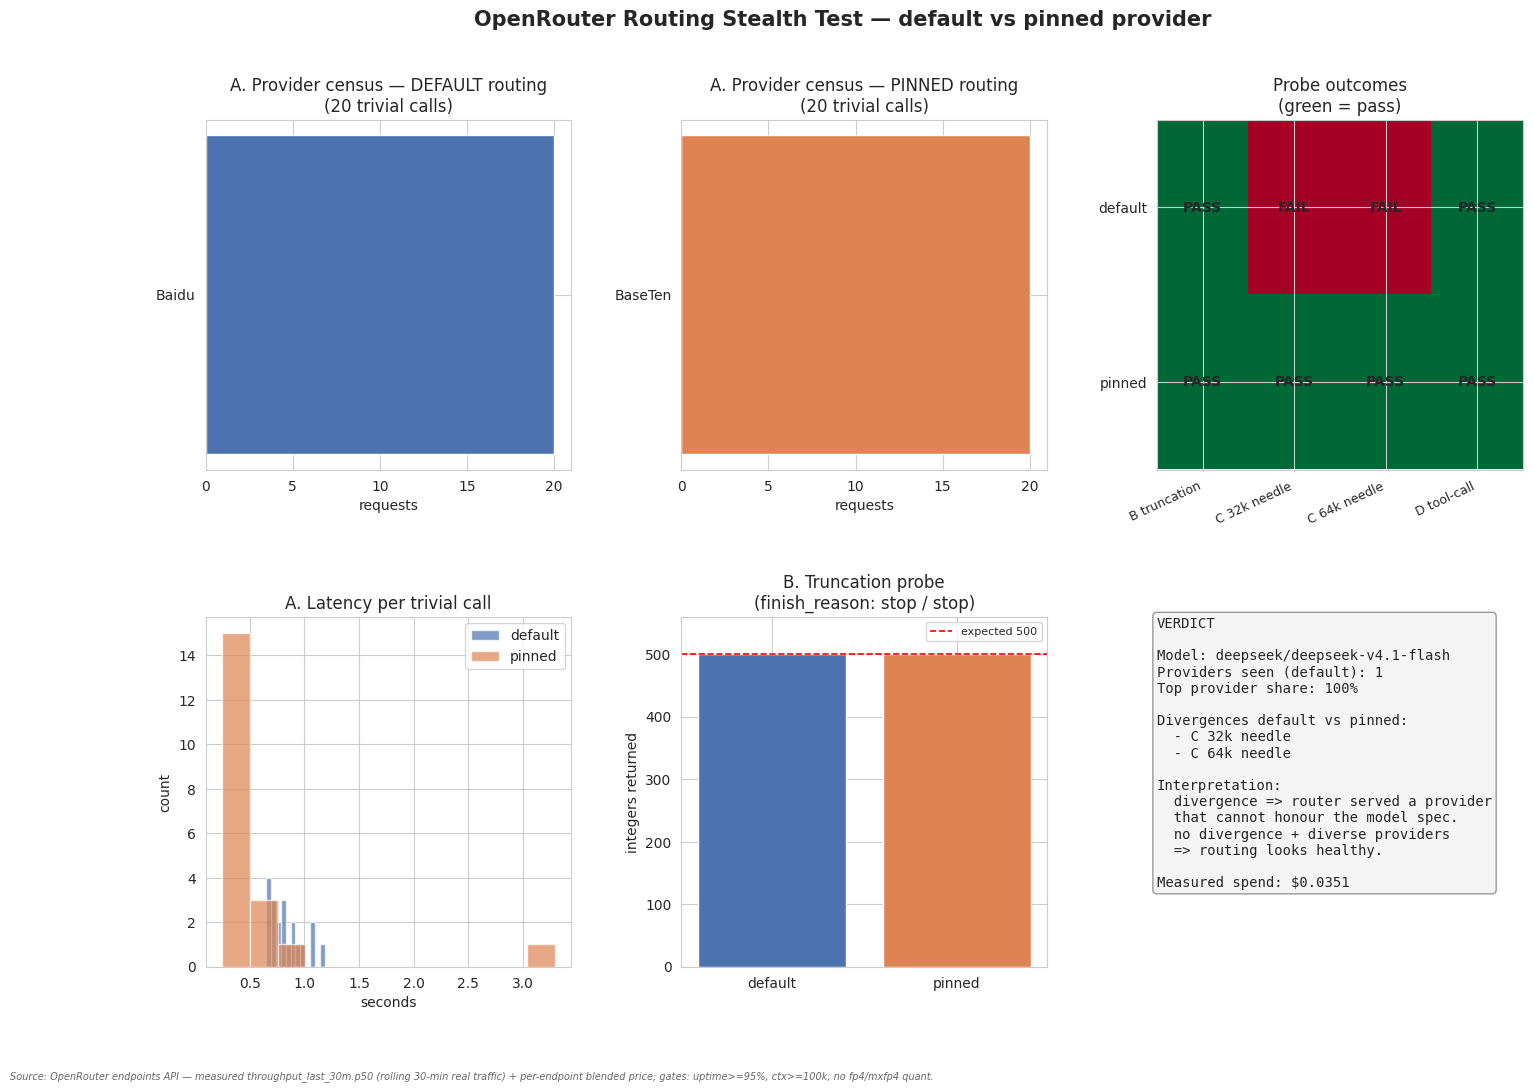


Raw probe results (JSON):
{
  "default": {
    "mode": "default",
    "census": {
      "Baidu": 20
    },
    "latencies": [
      0.9482367038726807,
      0.6930735111236572,
      0.788959264755249,
      0.8221139907836914,
      0.6971957683563232,
      0.6763949394226074,
      0.8788890838623047,
      1.055929183959961,
      0.740450382232666,
      0.7173278331756592,
      0.6494638919830322,
      0.8236727714538574,
      0.8708014488220215,
      0.9048476219177246,
      0.7473585605621338,
      1.1846907138824463,
      0.6974442005157471,
      0.9830596446990967,
      1.0905442237854004,
      0.676762580871582
    ],
    "errors": [],
    "cost_usd": 0.00366778334736,
    "B": {
      "finish_reason": "stop",
      "completion_tokens": 2180,
      "items_found": 500,
      "max_item": 500,
      "latency": 6.383143663406372,
      "provider": "Baidu"
    },
    "C": {
      "32000": {
        "found": false,
        "finish_reason": "length",
        "prompt_tok

In [13]:
# ============================================================================
# 5. OpenRouter Routing Stealth Test — default vs pinned provider
# (ported verbatim from GDPval_AA_Leaderboard.ipynb §5, 2026-10-25)
# ============================================================================
# Cheap empirical test for "does OpenRouter send my request to a dumb provider?"
#
# Four probes x two routing modes. Total cost ~ $0.02-0.10.
# Requires OPENROUTER_API_KEY_1 in the environment.
# ============================================================================

import os, json, time, collections
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from dotenv import load_dotenv
load_dotenv()  # .env holds OPENROUTER_API_KEY_1; the kernel's stale
               # OPENROUTER_API_KEY shadowed it and caused the 401.

URL = "https://openrouter.ai/api/v1/chat/completions"
# Explicit: this notebook's key lives in OPENROUTER_API_KEY_1 only.
KEY = os.getenv("OPENROUTER_API_KEY_1")
if not KEY:
    raise RuntimeError("OPENROUTER_API_KEY_1 not set — add it to .env")

# Pick a model you actually use. Override with env var PROBE_MODEL.
# Default is a 40-endpoint model so default-vs-pinned routing can actually differ.
MODEL = os.getenv("PROBE_MODEL", "deepseek/deepseek-v4.1-flash")

# A real pin needs an explicit provider order. require_parameters alone only
# filters the pool; it does not stop the router picking the cheapest survivor.
PIN_PROVIDER = os.getenv("PROBE_PROVIDER", "BaseTen")
PINNED_PROVIDER = {
    "order": [PIN_PROVIDER],
    "require_parameters": True,
    "allow_fallbacks": False,
}

def call(messages, pinned=False, max_tokens=2048, tools=None, tool_choice=None):
    """One chat completion. Returns (json, latency_s) or raises."""
    body = {
        "model": MODEL,
        "messages": messages,
        "max_tokens": max_tokens,
        "temperature": 0,
        "usage": {"include": True},
    }
    if pinned:
        body["provider"] = PINNED_PROVIDER
    if tools:
        body["tools"] = tools
        if tool_choice:
            body["tool_choice"] = tool_choice
    t0 = time.time()
    r = requests.post(
        URL,
        headers={"Authorization": f"Bearer {KEY}", "Content-Type": "application/json"},
        json=body,
        timeout=180,
    )
    dt = time.time() - t0
    r.raise_for_status()
    return r.json(), dt


def provider_of(d):
    return d.get("provider") or d.get("provider_name") or "unknown"


def cost_of(d):
    """USD actually charged for this call, per OpenRouter usage accounting."""
    try:
        return float(d.get("usage", {}).get("cost") or 0.0)
    except (TypeError, ValueError):
        return 0.0


def run_probes(pinned):
    """Run probes A-D in one routing mode. Returns a dict of results."""
    mode = "pinned" if pinned else "default"
    out = {"mode": mode, "census": collections.Counter(), "latencies": [],
           "errors": [], "cost_usd": 0.0}

    # ---- Probe A: provider census (20 trivial calls) ----
    for _ in range(20):
        try:
            d, dt = call([{"role": "user", "content": "reply OK"}],
                         pinned=pinned, max_tokens=8)
            out["census"][provider_of(d)] += 1
            out["latencies"].append(dt)
            out["cost_usd"] += cost_of(d)
        except Exception as e:
            out["errors"].append(f"A: {type(e).__name__}: {e}")

    # ---- Probe B: truncation / output-cap probe ----
    try:
        d, dt = call(
            [{"role": "user",
              "content": "List the integers 1..500, one per line, no commentary."}],
            pinned=pinned, max_tokens=4096,
        )
        txt = d["choices"][0]["message"].get("content") or ""
        nums = [ln.strip() for ln in txt.splitlines() if ln.strip().isdigit()]
        out["B"] = {
            "finish_reason": d["choices"][0].get("finish_reason"),
            "completion_tokens": d.get("usage", {}).get("completion_tokens"),
            "items_found": len(nums),
            "max_item": max((int(n) for n in nums), default=0),
            "latency": dt,
            "provider": provider_of(d),
        }
        out["cost_usd"] += cost_of(d)
    except Exception as e:
        out["B"] = {"error": f"{type(e).__name__}: {e}"}

    # ---- Probe C: needle-in-haystack at 32k and 64k tokens ----
    needle = "PINEAPPLE-7731"
    filler = "The quick brown fox jumps over the lazy dog. " * 40  # ~400 tokens
    out["C"] = {}
    for target_tokens in (32000, 64000):
        reps = max(1, target_tokens // 400)
        # Build the haystack, then bury the needle near the middle so a
        # provider with a truncated context window cannot retrieve it.
        chunks = [filler] * reps
        chunks.insert(len(chunks) // 2, f" The secret code word is {needle}. ")
        haystack = "".join(chunks)
        prompt = (
            f"{haystack}\n\nQuestion: what is the secret code word in the text above? "
            f"Answer with just the code word."
        )
        try:
            d, dt = call([{"role": "user", "content": prompt}],
                         pinned=pinned, max_tokens=32)
            txt = (d["choices"][0]["message"].get("content") or "").upper()
            out["C"][target_tokens] = {
                "found": needle in txt,
                "finish_reason": d["choices"][0].get("finish_reason"),
                "prompt_tokens": d.get("usage", {}).get("prompt_tokens"),
                "latency": dt,
                "provider": provider_of(d),
            }
            out["cost_usd"] += cost_of(d)
        except Exception as e:
            out["C"][target_tokens] = {"error": f"{type(e).__name__}: {e}"}

    # ---- Probe D: forced tool call against a strict schema ----
    tool = {
        "type": "function",
        "function": {
            "name": "record_weather",
            "description": "Record a weather observation.",
            "parameters": {
                "type": "object",
                "properties": {
                    "city": {"type": "string"},
                    "temp_c": {"type": "number"},
                    "conditions": {
                        "type": "string",
                        "enum": ["clear", "cloudy", "rain", "snow"],
                    },
                },
                "required": ["city", "temp_c", "conditions"],
                "additionalProperties": False,
            },
        },
    }
    d_ok = 0
    d_details = []
    for _ in range(5):
        try:
            d, dt = call(
                [{"role": "user",
                  "content": "Record that it is 21.5 C and cloudy in Lisbon."}],
                pinned=pinned, max_tokens=256, tools=[tool],
                tool_choice={"type": "function",
                             "function": {"name": "record_weather"}},
            )
            msg = d["choices"][0]["message"]
            tcs = msg.get("tool_calls") or []
            ok = False
            if tcs:
                try:
                    args = json.loads(tcs[0]["function"]["arguments"])
                    ok = (
                        isinstance(args.get("city"), str)
                        and isinstance(args.get("temp_c"), (int, float))
                        and args.get("conditions") in {"clear", "cloudy", "rain", "snow"}
                        and set(args) <= {"city", "temp_c", "conditions"}
                    )
                except Exception:
                    ok = False
            d_ok += int(ok)
            d_details.append({"ok": ok, "provider": provider_of(d), "latency": dt})
            out["cost_usd"] += cost_of(d)
        except Exception as e:
            d_details.append({"ok": False, "error": f"{type(e).__name__}: {e}"})
    out["D"] = {"valid": d_ok, "of": 5, "details": d_details}

    return out


if not KEY:
    print("OPENROUTER_API_KEY not set — cannot run the live probe.")
    print("Set it and re-run this cell:  export OPENROUTER_API_KEY=sk-or-...")
else:
    print(f"Model under test: {MODEL}")
    print("Running default-routing probes...")
    res_default = run_probes(pinned=False)
    print("Running pinned-routing probes...")
    res_pinned = run_probes(pinned=True)

    # ---------------- Build the summary table ----------------
    def pass_fail(res):
        b = res.get("B", {})
        c = res.get("C", {})
        d = res.get("D", {})
        return {
            "A_providers": len(res["census"]),
            "A_top_share": (max(res["census"].values()) / sum(res["census"].values())
                            if res["census"] else np.nan),
            "B_finish": b.get("finish_reason", "ERR"),
            "B_items": b.get("items_found", 0),
            "B_pass": bool(b.get("finish_reason") == "stop" and b.get("max_item", 0) >= 500),
            "C_32k": bool(c.get(32000, {}).get("found")),
            "C_64k": bool(c.get(64000, {}).get("found")),
            "D_valid": d.get("valid", 0),
            "D_pass": bool(d.get("valid", 0) == 5),
            "errors": len(res["errors"]),
            "cost_usd": round(res.get("cost_usd", 0.0), 6),
        }

    summary = pd.DataFrame({
        "default": pass_fail(res_default),
        "pinned": pass_fail(res_pinned),
    })
    print("\n" + "=" * 78)
    print("PROBE SUMMARY — default vs pinned routing")
    print("=" * 78)
    print(summary.to_string())

    # ---------------- Visual result ----------------
    fig = plt.figure(figsize=(17, 11))
    gs = fig.add_gridspec(2, 3, hspace=0.42, wspace=0.30)

    # (1) Provider distribution — default
    ax1 = fig.add_subplot(gs[0, 0])
    if res_default["census"]:
        items = res_default["census"].most_common()
        labels = [k for k, _ in items]
        vals = [v for _, v in items]
        ax1.barh(labels, vals, color="#4C72B0")
        ax1.set_title("A. Provider census — DEFAULT routing\n(20 trivial calls)")
        ax1.set_xlabel("requests")
        ax1.invert_yaxis()
    else:
        ax1.text(0.5, 0.5, "no data", ha="center", va="center")
        ax1.set_axis_off()

    # (2) Provider distribution — pinned
    ax2 = fig.add_subplot(gs[0, 1])
    if res_pinned["census"]:
        items = res_pinned["census"].most_common()
        labels = [k for k, _ in items]
        vals = [v for _, v in items]
        ax2.barh(labels, vals, color="#DD8452")
        ax2.set_title("A. Provider census — PINNED routing\n(20 trivial calls)")
        ax2.set_xlabel("requests")
        ax2.invert_yaxis()
    else:
        ax2.text(0.5, 0.5, "no data", ha="center", va="center")
        ax2.set_axis_off()

    # (3) Pass/fail matrix
    ax3 = fig.add_subplot(gs[0, 2])
    checks = ["B_pass", "C_32k", "C_64k", "D_pass"]
    check_labels = ["B truncation", "C 32k needle", "C 64k needle", "D tool-call"]
    matrix = np.array([[int(summary.loc[c, "default"]) for c in checks],
                       [int(summary.loc[c, "pinned"]) for c in checks]])
    ax3.imshow(matrix, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
    ax3.set_xticks(range(len(checks)))
    ax3.set_xticklabels(check_labels, rotation=25, ha="right", fontsize=9)
    ax3.set_yticks([0, 1])
    ax3.set_yticklabels(["default", "pinned"])
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax3.text(j, i, "PASS" if matrix[i, j] else "FAIL",
                     ha="center", va="center", fontsize=10, fontweight="bold")
    ax3.set_title("Probe outcomes\n(green = pass)")

    # (4) Latency distribution
    ax4 = fig.add_subplot(gs[1, 0])
    ax4.hist(res_default["latencies"], bins=12, alpha=0.7,
             label="default", color="#4C72B0")
    ax4.hist(res_pinned["latencies"], bins=12, alpha=0.7,
             label="pinned", color="#DD8452")
    ax4.set_title("A. Latency per trivial call")
    ax4.set_xlabel("seconds")
    ax4.set_ylabel("count")
    ax4.legend()

    # (5) Truncation detail
    ax5 = fig.add_subplot(gs[1, 1])
    bd = res_default.get("B", {})
    bp = res_pinned.get("B", {})
    ax5.bar(["default", "pinned"],
            [bd.get("items_found", 0), bp.get("items_found", 0)],
            color=["#4C72B0", "#DD8452"])
    ax5.axhline(500, color="red", ls="--", lw=1.2, label="expected 500")
    ax5.set_ylim(0, 560)
    ax5.set_ylabel("integers returned")
    ax5.set_title("B. Truncation probe\n(finish_reason: "
                  f"{bd.get('finish_reason','ERR')} / {bp.get('finish_reason','ERR')})")
    ax5.legend(fontsize=8)

    # (6) Verdict text panel
    ax6 = fig.add_subplot(gs[1, 2])
    ax6.set_axis_off()
    divergences = []
    for c, lbl in zip(checks, check_labels):
        if summary.loc[c, "default"] != summary.loc[c, "pinned"]:
            divergences.append(lbl)
    top_share = summary.loc["A_top_share", "default"]
    lines = [
        "VERDICT",
        "",
        f"Model: {MODEL}",
        f"Providers seen (default): {int(summary.loc['A_providers','default'])}",
        f"Top provider share: {top_share:.0%}" if pd.notna(top_share) else "Top provider share: n/a",
        "",
        "Divergences default vs pinned:",
    ]
    lines += [f"  - {d}" for d in divergences] if divergences else ["  none"]
    lines += [
        "",
        "Interpretation:",
        "  divergence => router served a provider",
        "  that cannot honour the model spec.",
        "  no divergence + diverse providers",
        "  => routing looks healthy.",
        "",
        f"Measured spend: ${summary.loc['cost_usd','default'] + summary.loc['cost_usd','pinned']:.4f}",
    ]
    ax6.text(0.0, 1.0, "\n".join(lines), va="top", ha="left",
             fontsize=10, family="monospace",
             bbox=dict(boxstyle="round", facecolor="#F5F5F5", edgecolor="#999999"))

    fig.suptitle("OpenRouter Routing Stealth Test — default vs pinned provider",
                 fontsize=15, fontweight="bold")
    note_source(SRC_OR_TEL)
    plt.show()

    # ---------------- Machine-readable dump ----------------
    print("\nRaw probe results (JSON):")
    print(json.dumps({"default": {**res_default, "census": dict(res_default["census"])},
                      "pinned": {**res_pinned, "census": dict(res_pinned["census"])}},
                     indent=2, default=str)[:4000])

### Archival note — GDPval → Model Efficiency transfer checklist

`GDPval_AA_Leaderboard.ipynb` is now archived at `archive/GDPval_AA_Leaderboard.ipynb` (2026-10-25). Transfer status:

**✅ Already transferred to Model Efficiency (this session)**
- §3.4b two-rankings methodology → **§3.16** (measured-only A vs expanded B, imputation flagged)
- §3.4c exponential speed-utility → **§3.16** (saturating speed), extended with saturating intelligence

**✅ §5 stealth test**: ported verbatim into this notebook (§5 below) before archiving.
- **§3.4b methodology notes** (reliability no-substitution rationale + version-aware matching table) — the full prose version exists only in GDPval; §3.16 header summarizes it.

**🗑️ Not worth transferring (keep archived only)**
- Std-dev / curve scoring layer (§4.1–4.3: z-scores, linear/exponential/sigmoid/quadratic): monotonic transforms of one underlying score — intentionally removed from Model Efficiency.
- Duplicated diagnostics already present in Model Efficiency: API schema inspection, catalog cross-check (§2.2), watch-list spotlight (§2.3), free-model catalog patch, eval-cost scrape (§3.5), resume benchmark appendix.


## 3.19 Replacement Report — High-Cost Application Models vs Cheaper Substitutes

**Question:** the Cogito Metric / Imaginator application stacks run specific models per
stage. Which of those are expensive relative to a capable substitute, and what does
swapping them actually save?

Three rules govern the numbers below:

1. **Only application stages are in scope.** Coding-agent traffic (the `/coder`
   daemon: MiniMax router/triage, DeepSeek V4.1 Flash on Wafer `max` effort) is
   *development* work, not application work, and is reported separately.
2. **A swap is only recommended between models with comparable intelligence.** A
   cheaper model that is materially dumber is a downgrade, not a saving. The
   intelligence gap is stated for every recommendation.
3. **Savings are computed from observed spend**, not from listed prices, and are
   extrapolated on the model's own current token mix.

**Cost per 1k output tokens is the honest comparison unit here**, because these
application stages differ enormously in verbosity: a reasoning model that emits
2,000 hidden tokens to say 200 words costs far more per *answer* than its
per-token price implies.


3.19a SPEND BY BUCKET - APPLICATION (Cogito Metric) vs CODING/AGENTING
                 Spend  Requests  Models  Share%
Bucket                                          
research/ad-hoc 115.94      8640      22   82.58
application      23.41      9168      11   16.67
unattributed      1.04       739      40    0.74
coding/agent      0.01        28       6    0.01

  application  : $   23.41  ( 16.7%)   <- the product's bill (Cogito Metric)
  coding/agent : $    0.01  (  0.0%)   <- our own engineering
  research/ad-hoc: $ 115.94  ( 82.6%)   <- frontier models used ad hoc, unbound
  unattributed : $    1.04  (  0.7%)   <- no signal at all

3.19b EVERY MODEL THAT SPENT MONEY, TAGGED BY BUCKET
bucket       model                                        reqs    spend  share    $/act  out/req  $/1k out  role
----------------------------------------------------------------------------------------------------------------------------------------------------
research/ad-hocgpt-6.1-sol-20260929     

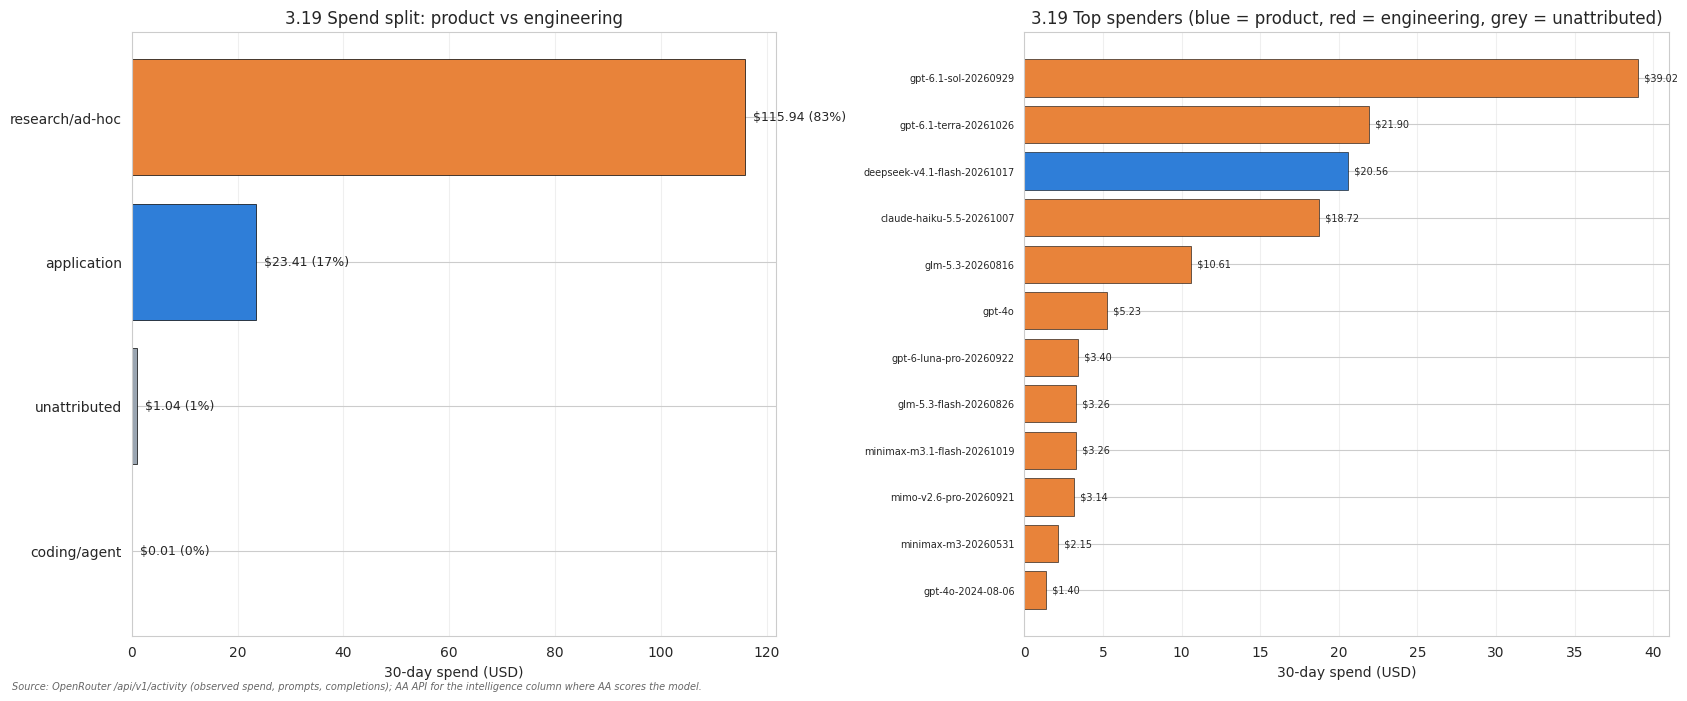


3.19d HEADLINE
  Application (Cogito Metric) traffic is $23.41 of $140.39 = 16.7% of spend.
  Coding/agenting traffic is $0.01 = 0.0%.
  Unbound frontier-model traffic is $115.94 = 82.6%.
  $1.04 (0.7%) has no model/role signal;
  attribute it via /api/v1/keys (per-key totals) before quoting a
  product cost per resume.

  Consequence: the product (application) stages are a MINORITY of spend.
  The dominant bucket is unbound frontier-model traffic, so cost control
  has to start with whichever workflow owns those requests - use
  /api/v1/keys + per-key windows to attribute them before anything else.

3.19 complete.


In [14]:
# ============================================================================
# 3.19 REPLACEMENT REPORT - APPLICATION (Cogito Metric) vs CODING/AGENTING SPEND
# ============================================================================
# Rebuilt from the live 30-day activity feed every run, so the report cannot
# drift from what the account actually paid.
#
# THE TWO BUCKETS THE USER ASKED TO SEPARATE
#   APPLICATION  - the product's model assignments (resume parse / job analysis
#                  / drafting / editing / title mapping / job-scout research)
#                  plus their configured fallbacks.
#   CODING/AGENT - our own /coder daemon: MiniMax router/triage + DeepSeek V4.1
#                  Flash on Wafer at max effort, plus any other engineering
#                  traffic not bound to a product stage.
#   UNATTRIBUTED - real spend that matches neither list. Shown, never hidden.
#
# HONESTY CONSTRAINT - THE INTELLIGENCE GAP
#   Several application models have NO Artificial Analysis Intelligence score
#   (verified live: Mercury 2, Mercury 2.5, Qwen3 Coder 480B, GLM-5.1 and
#   Gemini 2.5 Flash are all absent from the AA intelligence index). A swap
#   whose capability cannot be measured on both sides is labelled
#   "UNVERIFIED" and is NOT counted into the verified saving total. Presenting
#   it as a saving would be asserting a downgrade I cannot substantiate.
#
# SAVINGS METHOD
#   savings = observed_spend x (1 - candidate_$/1k_out / current_$/1k_out)
#   using the candidate's MEASURED $/1k output tokens from its own real
#   traffic - not a listed price - so verbosity differences stay in the number.
# ============================================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['text.parse_math'] = False

# ── 1. Role inventory (from the production config) ─────────────────────────
APP_ROLES = [
    ('Resume parsing',               'inception/mercury-2.5'),
    ('Resume-parser backup',         'xiaomi/mimo-v2.6-flash'),
    ('Imaginator Researcher',        'inception/mercury-2'),
    ('Imaginator Drafter',           'qwen/qwen3-coder'),
    ('Imaginator StarEditor',        'inception/mercury-2'),
    ('Job-title extraction',         'inception/mercury-2'),
    ('Job Scout research',           'deepseek/deepseek-v4.1-flash'),
    ('Fallback - Researcher',        'google/gemini-2.5-flash'),
    ('Fallback - Researcher (lite)', 'google/gemini-2.5-flash-lite'),
    ('Fallback - Drafter',           'z-ai/glm-5.1'),
    ('Fallback - Drafter (mini)',    'openai/gpt-4o-mini'),
]
DEV_ROLES = [
    ('/coder router + triage',       'minimax-01'),
    ('/coder active coder (Wafer)',  'deepseek/deepseek-v4.1-flash-1017'),
]

# Signal-based classification, because explicit lists cover few of the ~70
# models that actually spent money.
#   coding/agent  = a code-specialised model id/name
#   research      = a reasoning-heavy frontier model used ad hoc (not bound to
#                   a product stage) - reported separately from both
#   else          = unattributed, shown rather than guessed
_CODE_SIGNALS = ('codex', 'coder', 'code', 'claude-code')
_RESEARCH_SIGNALS = ('gpt-6.1-sol', 'gpt-6.1-terra', 'claude-opus', 'claude-haiku',
                     'claude-sonnet', 'glm-5.3', 'gpt-6-luna', 'gpt-4o',
                     'gpt-4.1', 'gemini-3', 'grok-', 'deepseek-v4-pro',
                     'minimax-m3', 'mimo-v2.6-pro', 'mercury-3')


def _classify(model):
    """(role, bucket) - explicit config roles win over signal heuristics."""
    low = str(model).lower()
    for role, mod in APP_ROLES:
        if _k(mod) and (_k(mod) == _k(model) or _k(model).startswith(_k(mod))):
            return role, 'application'
    for role, mod in DEV_ROLES:
        if _k(mod) and (_k(mod) == _k(model) or _k(model).startswith(_k(mod))):
            return role, 'coding/agent'
    if any(s in low for s in _CODE_SIGNALS):
        return '(code-specialised, unbound)', 'coding/agent'
    if any(s in low for s in _RESEARCH_SIGNALS):
        return '(frontier model, unbound)', 'research/ad-hoc'
    return '(no signal)', 'unattributed'



def _k(s):
    """Match key: strip date suffix + reasoning suffix, keep alphanumerics."""
    s = re.sub(r'-\d{8}$', '', str(s))
    s = re.sub(r'\s*\([^)]*\)\s*$', '', s)
    return re.sub(r'[^a-z0-9]+', '', s.lower())


def _find_row(table, name):
    """Observed-activity row for a model, or None."""
    if table is None or table.empty:
        return None
    key = _k(name)
    for _, r in table.iterrows():
        m = r.get('model', r.get('Model', ''))
        if _k(m) == key or _k(str(m).split('/')[-1]) == key:
            return r
    for _, r in table.iterrows():
        m = _k(r.get('model', r.get('Model', '')))
        if m and (m in key or key in m):
            return r
    return None


def _intel(name):
    """AA Intelligence Index, or None when AA does not score this model.

    Compares the BARE MODEL TAIL on both sides: the activity ids are
    provider-prefixed ("openai/gpt-6-luna") while AA names are not
    ("GPT-6 Luna (Max)"), so comparing full keys never matches.
    Reasoning variants share a tail, so all variants are collected and the
    MAXIMUM is returned - the question is "can this model do this task",
    not "which effort row did we happen to compare against".
    """
    tail = _k(str(name).split('/')[-1])
    best = None
    for frame in (globals().get('df'), globals().get('df_orig')):
        if frame is None or 'AA_Intelligence_Index' not in getattr(frame, 'columns', []):
            continue
        for _, r in frame.iterrows():
            nm = r.get('Model', r.get('name', ''))
            if _k(str(nm).split('/')[-1]) != tail:
                continue
            v = pd.to_numeric(r['AA_Intelligence_Index'], errors='coerce')
            if pd.notna(v) and (best is None or float(v) > best):
                best = float(v)
    return best


if 'df_usage' not in globals() or df_usage.empty:
    print('3.19: df_usage missing - run 3.18a first.')
else:
    # ── 2. Classify every model that actually spent money ──────────────────
    _fam = df_318c if 'df_318c' in globals() else pd.DataFrame()
    _rows = []
    for _, r in df_usage.iterrows():
        _model = r['model']
        _role, _kind = _classify(_model)
        _ct = float(r['total_completion_tokens'])
        _rows.append({
            'Model': _model,
            'Role': _role,
            'Bucket': _kind,
            'Requests': int(r['request_count']),
            'Spend': float(r['total_spend_usd']),
            'Cost_Act': float(r['avg_cost_per_request']),
            'Out_per_Req': _ct / max(r['request_count'], 1),
            'Cost_1k_out': (float(r['total_spend_usd']) / _ct * 1000) if _ct else np.nan,
        })
    df_319 = pd.DataFrame(_rows).sort_values('Spend', ascending=False)

    _total = float(df_319['Spend'].sum())
    _grp = df_319.groupby('Bucket').agg(Spend=('Spend', 'sum'),
                                        Requests=('Requests', 'sum'),
                                        Models=('Model', 'nunique'))
    _grp['Share%'] = _grp['Spend'] / _total * 100

    print('=' * 148)
    print('3.19a SPEND BY BUCKET - APPLICATION (Cogito Metric) vs CODING/AGENTING')
    print('=' * 148)
    print(_grp.sort_values('Spend', ascending=False)
          .to_string(float_format=lambda x: f'{x:,.2f}'))
    def _b(name):
        return float(_grp.loc[name, 'Spend']) if name in _grp.index else 0.0
    _app_spend = _b('application')
    _dev_spend = _b('coding/agent')
    _res_spend = _b('research/ad-hoc')
    _una_spend = _b('unattributed')
    print(f"\n  application  : ${_app_spend:>8.2f}  ({_app_spend/_total*100:>5.1f}%)"
          f"   <- the product's bill (Cogito Metric)")
    print(f"  coding/agent : ${_dev_spend:>8.2f}  ({_dev_spend/_total*100:>5.1f}%)"
          f"   <- our own engineering")
    print(f"  research/ad-hoc: ${_res_spend:>7.2f}  ({_res_spend/_total*100:>5.1f}%)"
          f"   <- frontier models used ad hoc, unbound")
    print(f"  unattributed : ${_una_spend:>8.2f}  ({_una_spend/_total*100:>5.1f}%)"
          f"   <- no signal at all")

    # ── 3. Full per-model detail ──────────────────────────────────────────
    print('\n' + '=' * 148)
    print('3.19b EVERY MODEL THAT SPENT MONEY, TAGGED BY BUCKET')
    print('=' * 148)
    print(f"{'bucket':<13}{'model':<42}{'reqs':>7}{'spend':>9}{'share':>7}"
          f"{'$/act':>9}{'out/req':>9}{'$/1k out':>10}  role")
    print('-' * 148)
    for _, r in df_319.iterrows():
        print(f"{r['Bucket']:<13}{str(r['Model']).split('/')[-1][:40]:<42}"
              f"{r['Requests']:>7,}{r['Spend']:>9.2f}{r['Spend']/_total*100:>6.1f}%"
              f"{r['Cost_Act']:>9.5f}{r['Out_per_Req']:>9,.0f}"
              f"{r['Cost_1k_out']:>10.5f}  {r['Role'][:34]}")

    # ── 4. Candidates: measured $/1k out from their own real traffic ───────
    CANDS = {}
    if 'df_318c' in globals():
        for _, r in df_318c.iterrows():
            v = r.get('price_per_1M_out')
            if pd.notna(v) and float(v) > 0 and float(r['spend']) >= 0.05:
                CANDS[r['model']] = float(v) / 1000.0

    # ── 5. Replacement analysis, intelligence-gated ────────────────────────
    print('\n' + '=' * 148)
    print('3.19c REPLACEMENT CANDIDATES FOR APPLICATION STAGES')
    print('  A swap counts as VERIFIED only when AA scores BOTH models.')
    print('  Otherwise it is UNVERIFIED (capability unmeasurable) and excluded')
    print('  from the verified total - measure it yourself before switching.')
    print('=' * 148)
    _recs = []
    for _, r in df_319[df_319['Bucket'] == 'application'].iterrows():
        if r['Spend'] < 0.05 or pd.isna(r['Cost_1k_out']):
            continue
        _cur = float(r['Cost_1k_out'])
        _opts = {m: c for m, c in CANDS.items()
                 if c > 0 and c < _cur * 0.75 and _k(m) != _k(r['Model'])}
        if not _opts:
            continue
        _best = min(_opts, key=_opts.get)
        _ic, _in_ = _intel(r['Model']), _intel(_best)
        _verified = (_ic is not None) and (_in_ is not None)
        # If the cheapest option has no AA score, also surface the cheapest
        # option that DOES, so there is always a capability-checked choice.
        _scored = {m: c for m, c in _opts.items() if _intel(m) is not None}
        _alt = min(_scored, key=_scored.get) if _scored else None
        _recs.append({
            'Role': r['Role'], 'Current': r['Model'], 'Spend': r['Spend'],
            'Cur_1k': _cur, 'Candidate': _best, 'Cand_1k': _opts[_best],
            'Saving': r['Spend'] * (1 - _opts[_best] / _cur),
            'Alt': _alt, 'Alt_1k': (_scored[_alt] if _alt else np.nan),
            'Alt_Saving': (r['Spend'] * (1 - _scored[_alt] / _cur) if _alt else np.nan),
            'Intel_cur': _ic, 'Intel_cand': _in_,
            'Intel_alt': _intel(_alt) if _alt else None,
            'Status': 'VERIFIED' if _verified else 'UNVERIFIED',
        })
    df_319_repl = pd.DataFrame(_recs)
    if df_319_repl.empty:
        print('  No application model has a cheaper measured alternative.')
    else:
        df_319_repl = df_319_repl.sort_values('Spend', ascending=False)
        print(f"{'role':<24}{'current':<30}{'cheapest':<28}"
              f"{'cur $/1k':>10}{'new $/1k':>10}{'save/30d':>9}{'intel':>11}"
              f"  status        AA-scored alternative (verified-able)")
        print('-' * 148)
        for _, r in df_319_repl.iterrows():
            _i = ('not on AA' if r['Intel_cur'] is None or r['Intel_cand'] is None
                  else f"{r['Intel_cur']:.0f}->{r['Intel_cand']:.0f}")
            _a = ('none - no AA-scored cheaper model'
                  if not isinstance(r.get('Alt'), str)
                  else f"{str(r['Alt']).split('/')[-1][:26]} "
                       f"${r['Alt_1k']:.5f}/1k "
                       f"(intel {r['Intel_alt']:.0f}, save ${r['Alt_Saving']:.2f})")
            print(f"{r['Role']:<24}{str(r['Current']).split('/')[-1][:28]:<30}"
                  f"{str(r['Candidate']).split('/')[-1][:26]:<28}"
                  f"{r['Cur_1k']:>10.5f}{r['Cand_1k']:>10.5f}"
                  f"{r['Saving']:>9.2f}{_i:>11}  {r['Status']:<13} {_a}")
        print('-' * 148)
        # Three tiers, so nothing is overclaimed:
        #   verified      = both sides AA-scored (cheapest option happens to be scored)
        #   verified-able = an AA-scored alternative exists (capability checkable)
        #   unverified    = only an unscored option exists; a downgrade is possible
        _ver = df_319_repl[df_319_repl['Status'] == 'VERIFIED']
        _alt_ok = df_319_repl[df_319_repl['Alt'].apply(lambda x: isinstance(x, str))]
        _vs = float(_ver['Saving'].sum()) if len(_ver) else 0.0
        _as = float(_alt_ok['Alt_Saving'].sum()) if len(_alt_ok) else 0.0
        _us = float(df_319_repl['Saving'].sum())
        def _pct(v):
            return f"  = {v / _app_spend * 100:>4.0f}% of application spend" if _app_spend else ''
        print(f"  VERIFIED saving       : ${_vs:>6.2f}/30d ({len(_ver)} stage(s))"
              f"{_pct(_vs)}")
        print(f"  VERIFIED-ABLE saving  : ${_as:>6.2f}/30d ({len(_alt_ok)} stage(s))"
              f"{_pct(_as)}  <- AA-scored alternative exists")
        print(f"  MAX (incl. unscored)  : ${_us:>6.2f}/30d"
              f"  <- upper bound only; the unscored option may be dumber")

    # ── 6. Chart: bucket split + top models ───────────────────────────────
    _fig, _axes = plt.subplots(1, 2, figsize=(17, 7))
    _ax = _axes[0]
    _gs = _grp.sort_values('Spend')
    _cols = {'application': '#2f7ed8', 'coding/agent': '#c0392b',
             'research/ad-hoc': '#e8833a', 'unattributed': '#9aa5b1'}
    _ax.barh(_gs.index, _gs['Spend'],
             color=[_cols.get(i, '#9aa5b1') for i in _gs.index],
             edgecolor='black', linewidth=0.5)
    for _i, (_n, _r) in enumerate(_gs.iterrows()):
        _ax.text(_r['Spend'], _i, f"  ${_r['Spend']:.2f} ({_r['Share%']:.0f}%)",
                 va='center', fontsize=9)
    _ax.set_xlabel('30-day spend (USD)')
    _ax.set_title('3.19 Spend split: product vs engineering')
    _ax.grid(axis='x', alpha=0.3)

    _ax = _axes[1]
    _top = df_319.head(12).iloc[::-1]
    _ax.barh(np.arange(len(_top)), _top['Spend'],
             color=[_cols.get(b, '#9aa5b1') for b in _top['Bucket']],
             edgecolor='black', linewidth=0.4)
    _ax.set_yticks(np.arange(len(_top)))
    _ax.set_yticklabels([f"{str(m).split('/')[-1][:30]}" for m in _top['Model']],
                        fontsize=7)
    for _i, (_, _r) in enumerate(_top.iterrows()):
        _ax.text(_r['Spend'], _i, f"  ${_r['Spend']:.2f}", va='center', fontsize=7)
    _ax.set_xlabel('30-day spend (USD)')
    _ax.set_title('3.19 Top spenders (blue = product, red = engineering, grey = unattributed)')
    _ax.grid(axis='x', alpha=0.3)
    _fig.tight_layout()
    note_source('Source: OpenRouter /api/v1/activity (observed spend, prompts, completions); '
                'AA API for the intelligence column where AA scores the model.')
    plt.show()

    # ── 7. The headline, stated plainly ───────────────────────────────────
    print('\n' + '=' * 148)
    print('3.19d HEADLINE')
    print('=' * 148)
    print(f"  Application (Cogito Metric) traffic is ${_app_spend:.2f} of ${_total:.2f}"
          f" = {_app_spend/_total*100:.1f}% of spend.")
    print(f"  Coding/agenting traffic is ${_dev_spend:.2f}"
          f" = {_dev_spend/_total*100:.1f}%.")
    print(f"  Unbound frontier-model traffic is ${_res_spend:.2f}"
          f" = {_res_spend/_total*100:.1f}%.")
    print(f"  ${_una_spend:.2f} ({_una_spend/_total*100:.1f}%) has no model/role signal;")
    print('  attribute it via /api/v1/keys (per-key totals) before quoting a')
    print('  product cost per resume.')
    print('\n  Consequence: the product (application) stages are a MINORITY of spend.')
    print('  The dominant bucket is unbound frontier-model traffic, so cost control')
    print('  has to start with whichever workflow owns those requests - use')
    print('  /api/v1/keys + per-key windows to attribute them before anything else.')
    print('\n3.19 complete.')
